## **Maternal Mortality Models**

Predictive models for in-hospital / recorded mortality among pregnant women identified in MIMIC-IV, built as part of the modelling framework developed for this doctoral thesis (Universidad del Norte, Barranquilla). The notebook follows that framework step by step -- cohort construction, diagnostic-group classification, feature engineering, imbalance-aware evaluation -- applied here to the maternal population.

> **Methodological honesty note.** Class imbalance in this cohort is extreme (41 deaths out of 25,736 women, ~0.159%), which calls for additional statistical precautions, documented explicitly in Section 11.

### **1. Load libraries required for running models**

In [1]:
# import
import sys
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math
import warnings
import shap

import matplotlib.patches as mpatches
from matplotlib.gridspec import GridSpec
from scipy.stats import gaussian_kde

# from
from sklearn.naive_bayes import CategoricalNB, GaussianNB, BernoulliNB
from sklearn.preprocessing import LabelEncoder, StandardScaler, MinMaxScaler, RobustScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, classification_report, roc_auc_score,
                            roc_curve, auc, precision_score, recall_score, average_precision_score,
                            precision_recall_curve, PrecisionRecallDisplay, f1_score, balanced_accuracy_score,
                            silhouette_score, brier_score_loss)
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import calibration_curve
from xgboost import XGBClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.cluster import KMeans
from sklearn.pipeline import Pipeline
from sklearn.isotonic import IsotonicRegression
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from contextlib import redirect_stdout
from sklearn.decomposition import PCA
from mpl_toolkits.mplot3d import Axes3D
from lightgbm import LGBMClassifier

# Output folders (relative to notebooks/): tables -> data/, figures -> figures/
DATA_DIR = os.path.join('..', 'data')
FIG_DIR = os.path.join('..', 'figures')
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

C:\Users\egutierrez.FINGEOSEL\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Add own Libraries
# Add root directory to patch
sys.path.append(os.path.abspath(".."))

import importlib
import libraries.database as db_lib
import libraries.functions as functions_lib

importlib.reload(db_lib)
importlib.reload(functions_lib)
engine = db_lib.get_connect_database()

### **2. Cohort Construction and Diagnostic Classification**

#### **2.1 Maternal Cohort Extraction**

The maternal cohort was built by identifying women of reproductive age (**12-55 years**) with at
least one obstetric/pregnancy-related diagnosis, within the date-shifted window used throughout this
thesis's MIMIC-IV pipeline (`2021-10-01` to `2022-10-31` -- i.e. `YYYYMM` between `211001`
and `221410`), which corresponds to the 2008-2019 BIDMC period after MIMIC-IV date shifting. **No ICU
stay is required** for cohort membership -- see the final validated size further down.

**Exploratory analysis (reproduced below, not in an external notes file).** Before building the final
cohort table, Emmanuel's original discovery query is reproduced here directly, so the notebook is
self-contained: it counts admissions matching an obstetric/pregnancy ICD diagnosis within the
date-shifted window, first for any gender, then restricted to `gender = 'F'`, then restricted further to
those with a recorded death (own or later admission). No age filter is applied at this stage -- `dob` is
not used for filtering here, only the ICD/date/gender/death logic below, which is exactly what produced
the three counts in the table further down.

```sql
SELECT COUNT(1)
FROM
(
    SELECT a.subject_id, a.hadm_id
           , (
                CASE WHEN a.deathtime IS NULL
                     THEN (SELECT MIN(a2.deathtime)
                           FROM   mimiciv.admissions a2
                           WHERE  a2.subject_id = a.subject_id
                           AND    a2.deathtime IS NOT NULL)
                     ELSE a.deathtime
                END
             ) AS deathtime
    FROM   mimiciv.admissions a
    JOIN   mimiciv.patients p
      ON   a.subject_id = p.subject_id
    WHERE  TO_CHAR(a.admittime, 'YYYYMM') >= '211001'
    AND    TO_CHAR(a.admittime, 'YYYYMM') <= '221410'
    -- AND  p.gender = 'F'                    -- uncomment: 23,474 -> 23,471
    AND    (a.subject_id, a.hadm_id) IN (
               SELECT d.subject_id, d.hadm_id
               FROM   mimiciv.diagnoses_icd d
               JOIN   mimiciv.d_icd_diagnoses dd
                 ON   d.icd_code = dd.icd_code
               WHERE  dd.long_title ILIKE '%PREGNANCY%'
                  OR  dd.long_title ILIKE '%OBSTETRIC%'
                  OR  dd.long_title ILIKE '%FETAL%'
                  OR  dd.long_title ILIKE '%DELIVERY%'
           )
) X
-- WHERE X.deathtime IS NOT NULL              -- uncomment: 23,471 -> 36
```

**Validated cohort sizes** (from the exploratory query above; later reconfirmed in
`maternal_cohort_expanded_es.sql`, after fixing the DOB/age bug described below):

| Step | N |
|---|---|
| Pregnant/obstetric women in ICU (any gender code) | **23,474** |
| After filtering `gender = 'F'` | **23,471** |
| Deceased (`outcome = 1`) | **36** (~0.153%) |

> **Decision (Emmanuel, 2026-09-15).** The 3-record gap between 23,474 and 23,471 (non-`'F'` gender
> codes on admissions flagged as obstetric/pregnancy by ICD title) is closed, not an open question: the
> cohort must be women, so the `gender = 'F'` filter is applied and those 3 records are dropped. The gap
> is negligible (3 out of 23,474, ~0.01%) and does not warrant further review.

**Why `mimiciv.cohort_maternal` is built from the expanded view, not narrow (decision, Emmanuel,
2026-09-15).** Maternal deaths are the whole outcome Model A is trying to predict, and they are already
extremely rare (36 out of ~23,471 narrow-matched admissions, ~0.15%). The narrow, keyword-only diagnosis
match misses obstetric/pregnancy admissions whose ICD `long_title` does not literally contain
PREGNANCY/OBSTETRIC/FETAL/DELIVERY but which do fall inside the ICD-9 `630-679`/`V22-V24`/`V27`/`V28` or
ICD-10 `O00-O9A`/`Z33`/`Z34`/`Z37`/`Z39` obstetric ranges -- these extra codes are exactly what
`mimiciv.pregnancy_diagnoses_expanded` (defined in `maternal_cohort_expanded_en.sql`) adds on top of
`pregnancy_diagnoses_narrow`. Switching to expanded recovers additional true maternal deaths -- from 36 to **45**, confirmed
by Emmanuel running the exact Analysis 2 query below (same date window as narrow, `gender = 'F'` filter
applied, no age filter yet) -- which directly grows the minority class this model needs to learn from, at
the cost of also letting in a handful of admissions whose obstetric status is inferred from ICD
chapter/range rather than an explicit keyword. (A differently-scoped run in `maternal_cohort_expanded_en.sql`
-- age-filtered via `anchor_age`/`anchor_year`, no ICU requirement, no date restriction -- had earlier
pointed the same direction with 41; 45 is the confirmed figure for this notebook's exact scope and
supersedes it.) Given how scarce positive outcomes already are, that trade-off favours expanded. **Both analyses are kept below (narrow above, expanded next) so the comparison
stays visible rather than being silently overwritten.**

**Analysis 2 -- expanded (keyword + ICD chapter/range) diagnosis match.** Same structure as the narrow
query above (same date window, no age filter at this stage), but the inner diagnosis subquery is widened
to match `mimiciv.pregnancy_diagnoses_expanded`'s definition instead of the narrow keyword list:

```sql
SELECT COUNT(1)
FROM
(
    SELECT a.subject_id, a.hadm_id
           , (
                CASE WHEN a.deathtime IS NULL
                     THEN (SELECT MIN(a2.deathtime)
                           FROM   mimiciv.admissions a2
                           WHERE  a2.subject_id = a.subject_id
                           AND    a2.deathtime IS NOT NULL)
                     ELSE a.deathtime
                END
             ) AS deathtime
    FROM   mimiciv.admissions a
    JOIN   mimiciv.patients p
      ON   a.subject_id = p.subject_id
    WHERE  TO_CHAR(a.admittime, 'YYYYMM') >= '211001'
    AND    TO_CHAR(a.admittime, 'YYYYMM') <= '221410'
    -- AND  p.gender = 'F'                    -- uncomment to compare with the gender-filtered row below
    AND    (a.subject_id, a.hadm_id) IN (
               SELECT d.subject_id, d.hadm_id
               FROM   mimiciv.diagnoses_icd d
               JOIN   mimiciv.d_icd_diagnoses dd
                 ON   d.icd_code    = dd.icd_code
                AND   d.icd_version = dd.icd_version
               WHERE  dd.long_title ILIKE '%PREGNAN%'
                  OR  dd.long_title ILIKE '%OBSTETRIC%'
                  OR  dd.long_title ILIKE '%FETAL%'
                  OR  dd.long_title ILIKE '%DELIVERY%'
                  OR  dd.long_title ILIKE '%PUERPERIUM%'
                  OR  dd.long_title ILIKE '%POSTPARTUM%'
                  OR  dd.long_title ILIKE '%GESTATION%'
                  OR (d.icd_version = 9  AND d.icd_code ~ '^[0-9]'
                      AND LEFT(d.icd_code, 3)::int BETWEEN 630 AND 679)
                  OR (d.icd_version = 9  AND LEFT(d.icd_code, 3) IN ('V22','V23','V24','V27','V28'))
                  OR (d.icd_version = 10 AND LEFT(d.icd_code, 1) = 'O')
                  OR (d.icd_version = 10 AND (d.icd_code LIKE 'Z33%' OR d.icd_code LIKE 'Z34%'
                                            OR d.icd_code LIKE 'Z37%' OR d.icd_code LIKE 'Z39%'))
           )
) X
-- WHERE X.deathtime IS NOT NULL
```

| Step | Narrow (keyword-only) | Expanded (keyword + ICD range) |
|---|---|---|
| Obstetric/pregnancy admissions (date window, any gender) | **23,474** | **25,778** (confirmed by Emmanuel, running the query above as-is) |
| After `gender = 'F'` | **23,471** | **25,774** (confirmed by Emmanuel, uncommenting `AND p.gender = 'F'`) |
| Deceased (`outcome = 1`) | **36** | **45** (confirmed by Emmanuel, additionally uncommenting `WHERE X.deathtime IS NOT NULL`) |

This confirms and supersedes the 41 figure cited in the rationale above, which came from a
differently-scoped run (age-filtered, no ICU requirement, no date restriction, in
`maternal_cohort_expanded_en.sql`) -- both point the same direction (expanded recovers more true maternal
deaths than narrow), but **45 is the number that applies to this notebook's exact date-window /
no-age-filter scope** and is the one used going forward here.

Expanded adds **2,304 admissions** over narrow at the "any gender" step (25,778 vs. 23,474), **2,303**
after the `gender = 'F'` filter (25,774 vs. 23,471), and **9 additional deaths** at the final step (45 vs.
36) -- all consistent with expanded being the broader, more sensitive diagnosis-matching criterion by
design (keyword list + ICD-9 `630-679`/`V22-V24`/`V27`/`V28` + ICD-10 `O00-O9A`/`Z33`/`Z34`/`Z37`/`Z39`, vs.
narrow's keyword-only match).

**Diagnosis filter -- view `mimiciv.pregnancy_diagnoses_expanded`.** An admission qualifies as
"maternal/obstetric" if it carries at least one ICD diagnosis matching the expanded keyword list
(`PREGNAN`/`OBSTETRIC`/`FETAL`/`DELIVERY`/`PUERPERIUM`/`POSTPARTUM`/`GESTATION`) or falling inside the ICD-9
`630-679`/`V22-V24`/`V27`/`V28` or ICD-10 `O00-O9A`/`Z33`/`Z34`/`Z37`/`Z39` ranges -- see "why expanded"
above. This view is created by `sql/02_cohort_mortality/maternal_cohort_expanded_en.sql` -- run that script
first; the SQL below assumes `mimiciv.pregnancy_diagnoses_expanded` already exists rather than redefining
it. (`mimiciv.pregnancy_diagnoses_narrow`, created separately by `maternal_pregnancy_diagnoses_narrow_en.sql`,
remains available for Analysis 1 above and for `maternal_cohort_diagnostic_funnel_en.sql`.)

**Final validated `mimiciv.cohort_maternal` size (Emmanuel, 2026-09-15).** After running the actual
`CREATE TABLE` below (expanded diagnosis view + `gender = 'F'` + date window + age 12-55, no ICU
requirement):

| Metric | N |
|---|---|
| Rows in `mimiciv.cohort_maternal` | **25,736** |
| Deaths (`outcome = 1`) | **41** (~0.159%) |

This is the cohort Model A is actually trained on -- not the narrow-view figures (23,474 / 23,471 / 36) at
the top of this section, which are kept only as Analysis 1 for comparison and traceability.

**Outcome definition.** `outcome = 1` if `deathtime` is recorded either in the qualifying admission itself
or in any subsequent admission of the same `subject_id` -- a person-level death flag, not restricted to a
fixed post-admission window, since maternal in-hospital mortality is not naturally bounded by a short
fixed window the way a birth-linked outcome would be.

```sql
-- ============================================================================
-- Maternal cohort: women 12-55 y/o with an obstetric/pregnancy diagnosis,
-- admitted to ICU between 2021-10-01 and 2022-10-31 (date-shifted window).
-- ============================================================================

-- mimiciv.pregnancy_diagnoses_expanded is created by
-- maternal_cohort_expanded_en.sql (run that first) -- not redefined here.
-- Expanded (not narrow) is used deliberately: it recovers maternal deaths
-- the keyword-only match misses (36 -> 41), which matters more than the
-- added permissiveness given how rare the outcome already is -- see the
-- "why expanded" rationale in the markdown above.

-- CORRECTION (post-hoc, per Emmanuel's report that CREATE TABLE returned 0 rows):
-- PATIENTS.DOB in this schema is explicitly documented as an unpopulated/"NaN"
-- column for adult patients (see mimic_create_database.sql, line 36: "This is a
-- NaN column") -- it is only ever synthetically populated for newborn
-- subject_ids elsewhere in this thesis's data pipeline. Filtering on
-- `DATE_PART('year', admittime) - DATE_PART('year', p.dob) BETWEEN 12 AND 55`
-- therefore evaluates to NULL (not TRUE) for essentially every maternal row,
-- silently excluding 100% of the cohort -- which is exactly why the table came
-- back empty. Age must instead be computed from ANCHOR_AGE / ANCHOR_YEAR, the
-- fields MIMIC-IV actually populates for every patient (see
-- maternal_cohort_expanded_es.sql, where this same fix was already validated: it
-- moved the cohort from 0/broken to 23,471 admisiones / 41 fallecidas).
-- `dob` is kept as a passthrough NULL column below only so
-- get_maternal_cohort_query() (which still selects a `dob` column) does not
-- break -- do not use it for any real computation.

CREATE TABLE mimiciv.cohort_maternal AS
WITH maternal_admissions AS (
    SELECT DISTINCT a.subject_id, a.hadm_id, a.admittime, a.deathtime,
           a.ethnicity, a.insurance, a.language, a.admission_type, a.admission_location,
           p.anchor_age, p.anchor_year, p.gender
    FROM   mimiciv.admissions a
    JOIN   mimiciv.patients p
      ON   p.subject_id = a.subject_id
    JOIN   mimiciv.diagnoses_icd di
      ON   di.subject_id = a.subject_id
     AND   di.hadm_id    = a.hadm_id
    JOIN   mimiciv.pregnancy_diagnoses_expanded de
      ON   de.icd_code    = di.icd_code
     AND   de.icd_version = di.icd_version
    WHERE  p.gender = 'F'
    AND    TO_CHAR(a.admittime, 'YYYYMM') >= '211001'
    AND    TO_CHAR(a.admittime, 'YYYYMM') <= '221410'
    AND    p.anchor_age + (DATE_PART('year', a.admittime) - p.anchor_year) BETWEEN 12 AND 55
),
maternal_icu AS (
    SELECT  ma.*
           , (SELECT MIN(i.stay_id)   FROM mimiciv.icustays i
               WHERE i.subject_id = ma.subject_id AND i.hadm_id = ma.hadm_id) AS stay_id
           , (SELECT COUNT(1)        FROM mimiciv.icustays i
               WHERE i.subject_id = ma.subject_id AND i.hadm_id = ma.hadm_id) AS icu_stay_count
    FROM   maternal_admissions ma
)
SELECT  mi.subject_id
       , mi.hadm_id
       , mi.stay_id
       , NULL::timestamp AS dob
       , mi.admittime
       , mi.ethnicity
       , mi.insurance
       , mi.language
       , mi.admission_type
       , mi.admission_location
       , mi.icu_stay_count
       , (CASE WHEN mi.icu_stay_count > 0 THEN 1 ELSE 0 END) AS icu_stay
       , mi.anchor_age + (DATE_PART('year', mi.admittime) - mi.anchor_year) AS age_at_admission
       , (
            CASE WHEN mi.deathtime IS NULL
                 THEN (CASE WHEN (SELECT MIN(a2.deathtime)
                                    FROM   mimiciv.admissions a2
                                   WHERE  a2.subject_id = mi.subject_id
                                     AND  a2.deathtime IS NOT NULL) IS NOT NULL
                            THEN 1 ELSE 0 END)
                 ELSE 1
            END
         ) AS outcome
FROM   maternal_icu mi;
-- NOTE (2nd correction, per diagnostic funnel run by Emmanuel): the previous
-- `WHERE mi.stay_id IS NOT NULL` here was cutting the cohort from ~23,433
-- (narrow diagnosis view, no ICU requirement) down to just 384 -- confirmed
-- empirically that only ~1.6% of obstetric-diagnosis admissions in this
-- database involve an ICU stay at all. The date filter was checked too and
-- is a non-issue (546,024/546,028 admissions pass it). Dropping the ICU
-- requirement here (icu_stay / icu_stay_count are kept as informative
-- features, not as an inclusion filter) restores the full cohort; rows
-- without an ICU stay will simply have NULL chartevents-derived vitals/labs
-- in cohort_maternal_dataset (Section 2.4), which the existing median/mode
-- imputation step (Section 6) already handles -- exactly the same philosophy
-- already applied in maternal_cohort_expanded_es.sql and in the Model B (SMM)
-- cohort. If this materially changes the outcome balance, re-check Section
-- 11's imbalance analysis once real counts are in.
--
-- CONFIRMED (Emmanuel, 2026-09-15): this CREATE TABLE, built from
-- pregnancy_diagnoses_expanded with the age filter (anchor_age/anchor_year
-- BETWEEN 12 AND 55) applied on top of the 25,774 gender-filtered admissions
-- from Analysis 2 above, produces mimiciv.cohort_maternal with **25,736
-- rows** (SELECT COUNT(1) FROM mimiciv.cohort_maternal) and **41 deaths**
-- (SELECT COUNT(*) FILTER (WHERE outcome = 1) FROM mimiciv.cohort_maternal,
-- ~0.159%) -- both confirmed. The age filter trimmed 38 admissions and 4
-- deaths off the 25,774 / 45 Analysis 2 figures (which had no age filter).
-- This is the project's final, validated maternal cohort for Model A,
-- replacing the ~23,433 / 36 narrow-view figures referenced elsewhere in
-- this cell.

ALTER TABLE mimiciv.cohort_maternal ADD CONSTRAINT pk_cohort_maternal PRIMARY KEY (subject_id, hadm_id);
```

#### **2.2 Admission Diagnoses Extraction**

A `mimiciv.cohort_maternal_diagnoses` table is built by aggregating every ICD diagnosis
(`seq_num <= 4`) recorded for admissions in `mimiciv.cohort_maternal`, with `diagnoses`, `no_death` and
`death` counts per code -- the statistical basis used later for expert classification and residual
clustering. **Confirmed (Emmanuel, 2026-09-15): 4,116 distinct ICD codes**
(`SELECT COUNT(1) FROM mimiciv.cohort_maternal_diagnoses`).

```sql
CREATE TABLE mimiciv.cohort_maternal_diagnoses AS
SELECT di.icd_code
       , di.icd_version
       , did.long_title
       , count(1)                                          AS diagnoses
       , sum(CASE WHEN cm.outcome = 0 THEN 1 ELSE 0 END)    AS no_death
       , sum(CASE WHEN cm.outcome = 1 THEN 1 ELSE 0 END)    AS death
FROM   mimiciv.diagnoses_icd di
JOIN   mimiciv.d_icd_diagnoses did
  ON   di.icd_code = did.icd_code AND di.icd_version = did.icd_version
JOIN   mimiciv.cohort_maternal cm
  ON   cm.subject_id = di.subject_id AND cm.hadm_id = di.hadm_id
WHERE  di.seq_num <= 4
GROUP BY di.icd_code, di.icd_version, did.long_title;

ALTER TABLE mimiciv.cohort_maternal_diagnoses ADD COLUMN diagnoses_group     varchar(300);
ALTER TABLE mimiciv.cohort_maternal_diagnoses ADD COLUMN diagnoses_group_alt varchar(300);
ALTER TABLE mimiciv.cohort_maternal_diagnoses ADD COLUMN have_diagnoses      int4 DEFAULT 0;
ALTER TABLE mimiciv.cohort_maternal_diagnoses ADD CONSTRAINT pk_cm_diagnoses PRIMARY KEY (icd_code, icd_version);
```

> **Key methodological note.** The modeling framework used for this thesis requires ICD diagnoses to be
> grouped into clinically meaningful diagnostic categories before they can be used as model features, and
> that grouping must come from an expert panel review, not from whichever raw ICD codes happen to occur
> most often. All 4,116 distinct ICD codes in `mimiciv.cohort_maternal_diagnoses` were first classified
> with a rule-based ICD-9/ICD-10 chapter mapping (100% coverage, no fallback codes) and then consolidated,
> on statistical signal (mortality rate given only 41 deaths total) and recognized clinical importance
> (WHO major direct obstetric causes), into **26 real diagnostic groups (`GDG_M01`-`GDG_M26`) + one
> `diagnoses_excluded` sentinel** for administrative/non-pathological codes. This suggested classification
> was sent to the physician panel for review (2026-09-17); several have already replied that it looks
> reasonable, and a further review is in progress. Two additional residual-cluster placeholders
> (`GDG_M27`/`GDG_M28`, Section 2.3) are reserved for codes that remain unclassified, for **28 groups
> total** -- `gdg_m01`-`gdg_m28`.
>
> **This is implemented as a modifiable pipeline, not a one-off script**, so future feedback from the
> panel only ever requires editing data, never hand-editing SQL:
> `sql/02_cohort_mortality/maternal_diagnoses_group_catalog.csv` (one row per group) and
> `maternal_diagnoses_group_map.csv` (one row per ICD code -> group) are the actual source of truth;
> `scripts/generate_maternal_diagnoses_group_sql.py` regenerates
> `maternal_diagnoses_group_load_en.sql` (creates + loads the two tables) from those CSVs; and
> `maternal_diagnoses_group_assign_en.sql` stamps `diagnoses_group` on this table and creates the generic,
> catalog-driven `mimiciv.update_feature_diagnoses_cohort_maternal_dataset()` function that populates
> `gdg_m01`-`gdg_m28` on `cohort_maternal_dataset` (Section 2.4) -- see `docs/NAMING.md` for the full file
> list and run order.

#### **2.3 Residual Diagnostic Grouping via Unsupervised Clustering**

Following the same residual-diagnostic-grouping step used across this thesis's modelling framework, ICD
codes with too few occurrences to support a clinically meaningful expert group are clustered via k-means
over `(diagnoses, no_death, death)`, standardised with `StandardScaler`. Given the extreme rarity of the
positive class in this cohort (41/25,736), the `death` feature will be almost always 0 for residual codes
-- **the silhouette-based k selection and the resulting clusters should be interpreted with caution**,
since they will mostly reflect frequency (`diagnoses`) rather than a genuine mortality signal. The two
residual indicators are named **`gdg_m27`** (cluster 0) and **`gdg_m28`** (cluster 1), following the
framework's residual-cluster naming convention -- both are reserved placeholders in
`maternal_diagnoses_group_catalog.csv` (`display_order` 27/28) already, so no catalog change is needed
once this residual clustering step is actually run.

> **Expected to be a no-op with the current classification (2026-09-17).** The rule-based classification
> in Section 2.2 already covers all 4,116 codes with 100% coverage (26 real groups + the
> `diagnoses_excluded` sentinel for administrative codes) -- there is no leftover pool of codes with
> `diagnoses_group IS NULL` for k-means to cluster. The `unmatched_codes` sanity check at the end of
> `maternal_diagnoses_group_assign_en.sql`'s Step 1 already confirms this (expect `0`). The cell below
> guards for this: if nothing is left to cluster, it skips k-means and leaves `gdg_m27`/`gdg_m28` as
> reserved-but-always-`FALSE` columns. This step only becomes live again if a future reclassification (or
> a new ICD code the map doesn't cover yet) leaves some codes with `diagnoses_group IS NULL`.

In [3]:
def find_best_kmeans_k(p_df):

    features = ["diagnoses", "no_death", "death"]

    X = p_df[features].copy()

    preprocess = ColumnTransformer(
        transformers=[
            ('num', StandardScaler(), features),
        ]
    )

    best_k   = None
    best_sil = -1

    for k in range(2, 10):
        kmeans = Pipeline(steps=[
            ('preprocess', preprocess),
            ('cluster', KMeans(
                n_clusters=k,
                init='k-means++',
                random_state=42,
                n_init=10
            ))
        ])

        labels  = kmeans.fit_predict(X)
        X_trans = kmeans.named_steps['preprocess'].transform(X)
        sil     = silhouette_score(X_trans, labels)

        print(f"k={k}, silhouette={sil:.4f}")

        if sil > best_sil:
            best_sil = sil
            best_k   = k

    print(f"\nBest k={best_k}, silhouette={best_sil:.4f}")
    return best_k

In [4]:
db_lib.reset_diagnoses_group_cluster_maternal(engine)

query_diagnoses_maternal = db_lib.get_maternal_diagnoses_query(0)

# Get Dataframe from a PostgreSQL Query
df_diagnoses_maternal = pd.read_sql(query_diagnoses_maternal, engine)

# As of the 2026-09-17 classification, all 4,116 codes already have a diagnoses_group
# (26 real GDG_Mxx groups + 'diagnoses_excluded'), so this query is expected to return
# 0 rows -- there is nothing left to cluster. Guard against that instead of letting
# KMeans/silhouette_score crash on an empty DataFrame; gdg_m27/gdg_m28 simply stay
# reserved-but-unused (always FALSE) placeholder columns in that case.
if df_diagnoses_maternal.empty:
    print(
        "No residual codes to cluster (0 rows with diagnoses_group IS NULL) -- every ICD "
        "code already has a group from the Section 2.2 classification. Skipping k-means; "
        "gdg_m27/gdg_m28 remain reserved, always-FALSE placeholder columns."
    )
else:
    n_clusters_maternal = find_best_kmeans_k(df_diagnoses_maternal)

    features = ["diagnoses", "no_death", "death"]

    # Subset of columns we will use
    X = df_diagnoses_maternal[features].copy()
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(df_diagnoses_maternal[features])

    # --- Preprocessing ---
    preprocess = ColumnTransformer(
        transformers=[
            ('num', StandardScaler(), features),
        ]
    )

    kmeans = Pipeline(steps=[
        ('preprocess', preprocess),
        ('cluster', KMeans(
            n_clusters=n_clusters_maternal,
            init='k-means++',
            random_state=42,
            n_init=10
        ))
    ])

    # Fit and get labels
    labels = kmeans.fit_predict(X)

    df_diagnoses_maternal['cluster'] = labels

    # Get transformed data for the silhouette score
    X_trans = kmeans.named_steps['preprocess'].transform(X)

    # Update diagnoses group cluster
    db_lib.update_diagnoses_group_cluster_maternal(engine, df_diagnoses_maternal)

    pca = PCA(n_components=2)
    components = pca.fit_transform(X_trans)

    plt.figure(figsize=(8,6))
    plt.scatter(components[:,0], components[:,1], c=labels, cmap='viridis', s=30)
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.title("Residual diagnosis clusters (maternal) - PCA 2D")
    plt.colorbar(label="Cluster")
    plt.show()

Records updated: 0
No residual codes to cluster (0 rows with diagnoses_group IS NULL) -- every ICD code already has a group from the Section 2.2 classification. Skipping k-means; gdg_m27/gdg_m28 remain reserved, always-FALSE placeholder columns.


#### **2.4 Dataset Assembly**

`mimiciv.cohort_maternal_dataset` is assembled with the same three-level nested-query pattern
(`X` -> `Y` -> `K`) used across this thesis's cohort-dataset-assembly framework: `X`/`Y` resolve cohort
membership, administrative attributes and the outcome (already produced by `cohort_maternal` above); `K`
extracts the **earliest available value** of each of the **27 chart/lab measurements**, using the itemid
catalogue already validated for this kind of chartevents extraction for the ICU-only ones (these are
adult-scale vitals/labs, appropriate for this maternal cohort):

- **Haemodynamics (ICU-only, `mimiciv.chartevents`):** heart rate, respiratory rate, O2 saturation,
  mean/systolic/diastolic blood pressure
- **Anthropometrics (ICU-only, `mimiciv.chartevents`):** weight at admission, height, temperature
- **Laboratory (hospital-wide -- `mimiciv.chartevents` OR `mimiciv.labevents`):** glucose, haemoglobin,
  sodium, potassium, non-ionised calcium, magnesium, chloride, bicarbonate, phosphorus, creatinine,
  haematocrit, lactic acid, anion gap
- **Neurological/sedation/ventilation (ICU-only, `mimiciv.chartevents`):** GCS (eye, verbal, motor),
  Richmond Agitation-Sedation Scale (RASS), PEEP set

> **Fixed (2026-09-17): labs no longer silently `NULL` for non-ICU admissions.** `mimiciv.chartevents`
> only contains data charted during an ICU stay; since `cohort_maternal` does not require one, every
> chart/lab column was `NULL` for any admission that never reached the ICU (confirmed against the live
> table -- see README status item 3). The 13 **laboratory** variables listed above are true labs, and labs
> in MIMIC-IV are also recorded hospital-wide in `mimiciv.labevents` -- so each of their `K` subqueries
> below now takes the **earliest value from either `chartevents` or `labevents`**, whichever has it first,
> instead of `chartevents` alone. The `labevents` itemid for each was chosen from the highest-volume,
> `fluid = 'Blood'` row Emmanuel pulled with
> `sql/03_cohort_smm/lookup_itemids_labevents_en.sql` (2026-09-17): glucose=50931, hemoglobin=51222,
> sodium=50983, potassium=50971, calcium(total)=50893, magnesium=50960, chloride=50902, bicarbonate=50882,
> phosphate=50970, creatinine=50912, hematocrit=51221, lactate=50813, anion gap=50868. The remaining 14
> variables (haemodynamics, anthropometrics, neuro/sedation/ventilation) have **no ward-level equivalent**
> in MIMIC-IV's structured schema -- they stay `chartevents`-only and will remain genuinely `NULL` for
> non-ICU admissions; that residual missingness is the open question tracked in item 8 of Section 15
> (whether to add per-variable "missing" flags before imputing).

> **Excluded: `apnea_interval` (itemid 223876), a newborn-specific measurement.** Per
> `Features_Clasificacion_Maternal_Neonatal.xlsx` (sheet *Features Clinicas*, row 70), this variable
> ("apnea de la prematuridad", i.e. apnea of prematurity) is classified as newborn-specific in the
> project's feature catalogue -- it has no clinical meaning for an adult maternal patient and is dropped
> from the maternal feature set.
>
> **Added: `age_at_admission`.** Maternal age is a clinically important predictor for this cohort (it
> spans 12-55 years) and is included here as a feature.

```sql
CREATE TABLE mimiciv.cohort_maternal_dataset AS
SELECT K.*
FROM
(
	select Y.subject_id
	       , Y.hadm_id
	       , Y.stay_id
	       , Y.dob
	       , Y.age_at_admission
	       , Y.ethnicity
	       , Y.insurance
	       , Y.language
	       , Y.admission_type
	       , Y.admission_location
	       , Y.icu_stay
	       , Y.icu_stay_count
	       , Y.outcome
	   , (
		select max(c.valuenum)
		from   mimiciv.chartevents c
		where  c.subject_id = Y.subject_id
		and    c.hadm_id    = Y.hadm_id
		and    c.stay_id    = Y.stay_id
		and    c.itemid     = 220045
		and    c.valuenum is not null
		and    c.charttime = (
							 select min(c2.charttime)
							 from   mimiciv.chartevents c2
							 where  c2.subject_id = c.subject_id
							 and    c2.hadm_id    = c.hadm_id
							 and    c2.stay_id    = c.stay_id
							 and    c2.itemid     = 220045
							 and    c2.valuenum is not null
							)
	) as heart_rate
	   , (
		select max(c.valuenum)
		from   mimiciv.chartevents c
		where  c.subject_id = Y.subject_id
		and    c.hadm_id    = Y.hadm_id
		and    c.stay_id    = Y.stay_id
		and    c.itemid     = 220210
		and    c.valuenum is not null
		and    c.charttime = (
							 select min(c2.charttime)
							 from   mimiciv.chartevents c2
							 where  c2.subject_id = c.subject_id
							 and    c2.hadm_id    = c.hadm_id
							 and    c2.stay_id    = c.stay_id
							 and    c2.itemid     = 220210
							 and    c2.valuenum is not null
							)
	) as respiratory_rate
	   , (
		select max(c.valuenum)
		from   mimiciv.chartevents c
		where  c.subject_id = Y.subject_id
		and    c.hadm_id    = Y.hadm_id
		and    c.stay_id    = Y.stay_id
		and    c.itemid     = 220277
		and    c.valuenum is not null
		and    c.charttime = (
							 select min(c2.charttime)
							 from   mimiciv.chartevents c2
							 where  c2.subject_id = c.subject_id
							 and    c2.hadm_id    = c.hadm_id
							 and    c2.stay_id    = c.stay_id
							 and    c2.itemid     = 220277
							 and    c2.valuenum is not null
							)
	) as o2_saturation
	   , (
		select max(c.valuenum)
		from   mimiciv.chartevents c
		where  c.subject_id = Y.subject_id
		and    c.hadm_id    = Y.hadm_id
		and    c.stay_id    = Y.stay_id
		and    c.itemid     = 220181
		and    c.valuenum is not null
		and    c.charttime = (
							 select min(c2.charttime)
							 from   mimiciv.chartevents c2
							 where  c2.subject_id = c.subject_id
							 and    c2.hadm_id    = c.hadm_id
							 and    c2.stay_id    = c.stay_id
							 and    c2.itemid     = 220181
							 and    c2.valuenum is not null
							)
	) as pressure_blood_mean
	   , (
		select max(c.valuenum)
		from   mimiciv.chartevents c
		where  c.subject_id = Y.subject_id
		and    c.hadm_id    = Y.hadm_id
		and    c.stay_id    = Y.stay_id
		and    c.itemid     = 220179
		and    c.valuenum is not null
		and    c.charttime = (
							 select min(c2.charttime)
							 from   mimiciv.chartevents c2
							 where  c2.subject_id = c.subject_id
							 and    c2.hadm_id    = c.hadm_id
							 and    c2.stay_id    = c.stay_id
							 and    c2.itemid     = 220179
							 and    c2.valuenum is not null
							)
	) as pressure_blood_systolic
	   , (
		select max(c.valuenum)
		from   mimiciv.chartevents c
		where  c.subject_id = Y.subject_id
		and    c.hadm_id    = Y.hadm_id
		and    c.stay_id    = Y.stay_id
		and    c.itemid     = 220180
		and    c.valuenum is not null
		and    c.charttime = (
							 select min(c2.charttime)
							 from   mimiciv.chartevents c2
							 where  c2.subject_id = c.subject_id
							 and    c2.hadm_id    = c.hadm_id
							 and    c2.stay_id    = c.stay_id
							 and    c2.itemid     = 220180
							 and    c2.valuenum is not null
							)
	) as pressure_blood_diastolic
	   , (
		select max(c.valuenum)
		from   mimiciv.chartevents c
		where  c.subject_id = Y.subject_id
		and    c.hadm_id    = Y.hadm_id
		and    c.stay_id    = Y.stay_id
		and    c.itemid     = 223761
		and    c.valuenum is not null
		and    c.charttime = (
							 select min(c2.charttime)
							 from   mimiciv.chartevents c2
							 where  c2.subject_id = c.subject_id
							 and    c2.hadm_id    = c.hadm_id
							 and    c2.stay_id    = c.stay_id
							 and    c2.itemid     = 223761
							 and    c2.valuenum is not null
							)
	) as temperature_fahrenheit
	   , (
		select max(c.valuenum)
		from   mimiciv.chartevents c
		where  c.subject_id = Y.subject_id
		and    c.hadm_id    = Y.hadm_id
		and    c.stay_id    = Y.stay_id
		and    c.itemid     = 226512
		and    c.valuenum is not null
		and    c.charttime = (
							 select min(c2.charttime)
							 from   mimiciv.chartevents c2
							 where  c2.subject_id = c.subject_id
							 and    c2.hadm_id    = c.hadm_id
							 and    c2.stay_id    = c.stay_id
							 and    c2.itemid     = 226512
							 and    c2.valuenum is not null
							)
	) as weight_admission
	   , (
		-- earliest available value from EITHER chartevents (ICU-only) OR
		-- labevents (hospital-wide) -- recovers this lab for admissions that
		-- never had an ICU stay; see sql/03_cohort_smm/lookup_itemids_labevents_en.sql
		select combined.valuenum
		from (
			select c.valuenum, c.charttime
			from   mimiciv.chartevents c
			where  c.subject_id = Y.subject_id
			and    c.hadm_id    = Y.hadm_id
			and    c.stay_id    = Y.stay_id
			and    c.itemid     = 220621
			and    c.valuenum is not null
			union all
			select le.valuenum, le.charttime
			from   mimiciv.labevents le
			where  le.subject_id = Y.subject_id
			and    le.hadm_id    = Y.hadm_id
			and    le.itemid     = 50931
			and    le.valuenum is not null
		) combined
		order by combined.charttime asc
		limit 1
	) as glucose
	   , (
		-- earliest available value from EITHER chartevents (ICU-only) OR
		-- labevents (hospital-wide) -- recovers this lab for admissions that
		-- never had an ICU stay; see sql/03_cohort_smm/lookup_itemids_labevents_en.sql
		select combined.valuenum
		from (
			select c.valuenum, c.charttime
			from   mimiciv.chartevents c
			where  c.subject_id = Y.subject_id
			and    c.hadm_id    = Y.hadm_id
			and    c.stay_id    = Y.stay_id
			and    c.itemid     = 220228
			and    c.valuenum is not null
			union all
			select le.valuenum, le.charttime
			from   mimiciv.labevents le
			where  le.subject_id = Y.subject_id
			and    le.hadm_id    = Y.hadm_id
			and    le.itemid     = 51222
			and    le.valuenum is not null
		) combined
		order by combined.charttime asc
		limit 1
	) as hemoglobine
	   , (
		-- earliest available value from EITHER chartevents (ICU-only) OR
		-- labevents (hospital-wide) -- recovers this lab for admissions that
		-- never had an ICU stay; see sql/03_cohort_smm/lookup_itemids_labevents_en.sql
		select combined.valuenum
		from (
			select c.valuenum, c.charttime
			from   mimiciv.chartevents c
			where  c.subject_id = Y.subject_id
			and    c.hadm_id    = Y.hadm_id
			and    c.stay_id    = Y.stay_id
			and    c.itemid     = 220645
			and    c.valuenum is not null
			union all
			select le.valuenum, le.charttime
			from   mimiciv.labevents le
			where  le.subject_id = Y.subject_id
			and    le.hadm_id    = Y.hadm_id
			and    le.itemid     = 50983
			and    le.valuenum is not null
		) combined
		order by combined.charttime asc
		limit 1
	) as sodium
	   , (
		-- earliest available value from EITHER chartevents (ICU-only) OR
		-- labevents (hospital-wide) -- recovers this lab for admissions that
		-- never had an ICU stay; see sql/03_cohort_smm/lookup_itemids_labevents_en.sql
		select combined.valuenum
		from (
			select c.valuenum, c.charttime
			from   mimiciv.chartevents c
			where  c.subject_id = Y.subject_id
			and    c.hadm_id    = Y.hadm_id
			and    c.stay_id    = Y.stay_id
			and    c.itemid     = 227442
			and    c.valuenum is not null
			union all
			select le.valuenum, le.charttime
			from   mimiciv.labevents le
			where  le.subject_id = Y.subject_id
			and    le.hadm_id    = Y.hadm_id
			and    le.itemid     = 50971
			and    le.valuenum is not null
		) combined
		order by combined.charttime asc
		limit 1
	) as potassium
	   , (
		-- earliest available value from EITHER chartevents (ICU-only) OR
		-- labevents (hospital-wide) -- recovers this lab for admissions that
		-- never had an ICU stay; see sql/03_cohort_smm/lookup_itemids_labevents_en.sql
		select combined.valuenum
		from (
			select c.valuenum, c.charttime
			from   mimiciv.chartevents c
			where  c.subject_id = Y.subject_id
			and    c.hadm_id    = Y.hadm_id
			and    c.stay_id    = Y.stay_id
			and    c.itemid     = 225625
			and    c.valuenum is not null
			union all
			select le.valuenum, le.charttime
			from   mimiciv.labevents le
			where  le.subject_id = Y.subject_id
			and    le.hadm_id    = Y.hadm_id
			and    le.itemid     = 50893
			and    le.valuenum is not null
		) combined
		order by combined.charttime asc
		limit 1
	) as noionized_calcium
	   , (
		-- earliest available value from EITHER chartevents (ICU-only) OR
		-- labevents (hospital-wide) -- recovers this lab for admissions that
		-- never had an ICU stay; see sql/03_cohort_smm/lookup_itemids_labevents_en.sql
		select combined.valuenum
		from (
			select c.valuenum, c.charttime
			from   mimiciv.chartevents c
			where  c.subject_id = Y.subject_id
			and    c.hadm_id    = Y.hadm_id
			and    c.stay_id    = Y.stay_id
			and    c.itemid     = 220635
			and    c.valuenum is not null
			union all
			select le.valuenum, le.charttime
			from   mimiciv.labevents le
			where  le.subject_id = Y.subject_id
			and    le.hadm_id    = Y.hadm_id
			and    le.itemid     = 50960
			and    le.valuenum is not null
		) combined
		order by combined.charttime asc
		limit 1
	) as magnesium
	   , (
		-- earliest available value from EITHER chartevents (ICU-only) OR
		-- labevents (hospital-wide) -- recovers this lab for admissions that
		-- never had an ICU stay; see sql/03_cohort_smm/lookup_itemids_labevents_en.sql
		select combined.valuenum
		from (
			select c.valuenum, c.charttime
			from   mimiciv.chartevents c
			where  c.subject_id = Y.subject_id
			and    c.hadm_id    = Y.hadm_id
			and    c.stay_id    = Y.stay_id
			and    c.itemid     = 220602
			and    c.valuenum is not null
			union all
			select le.valuenum, le.charttime
			from   mimiciv.labevents le
			where  le.subject_id = Y.subject_id
			and    le.hadm_id    = Y.hadm_id
			and    le.itemid     = 50902
			and    le.valuenum is not null
		) combined
		order by combined.charttime asc
		limit 1
	) as chloride
	   , (
		-- earliest available value from EITHER chartevents (ICU-only) OR
		-- labevents (hospital-wide) -- recovers this lab for admissions that
		-- never had an ICU stay; see sql/03_cohort_smm/lookup_itemids_labevents_en.sql
		select combined.valuenum
		from (
			select c.valuenum, c.charttime
			from   mimiciv.chartevents c
			where  c.subject_id = Y.subject_id
			and    c.hadm_id    = Y.hadm_id
			and    c.stay_id    = Y.stay_id
			and    c.itemid     = 227443
			and    c.valuenum is not null
			union all
			select le.valuenum, le.charttime
			from   mimiciv.labevents le
			where  le.subject_id = Y.subject_id
			and    le.hadm_id    = Y.hadm_id
			and    le.itemid     = 50882
			and    le.valuenum is not null
		) combined
		order by combined.charttime asc
		limit 1
	) as bicarbonate
	   , (
		-- earliest available value from EITHER chartevents (ICU-only) OR
		-- labevents (hospital-wide) -- recovers this lab for admissions that
		-- never had an ICU stay; see sql/03_cohort_smm/lookup_itemids_labevents_en.sql
		select combined.valuenum
		from (
			select c.valuenum, c.charttime
			from   mimiciv.chartevents c
			where  c.subject_id = Y.subject_id
			and    c.hadm_id    = Y.hadm_id
			and    c.stay_id    = Y.stay_id
			and    c.itemid     = 225677
			and    c.valuenum is not null
			union all
			select le.valuenum, le.charttime
			from   mimiciv.labevents le
			where  le.subject_id = Y.subject_id
			and    le.hadm_id    = Y.hadm_id
			and    le.itemid     = 50970
			and    le.valuenum is not null
		) combined
		order by combined.charttime asc
		limit 1
	) as phosphorus
	   , (
		-- earliest available value from EITHER chartevents (ICU-only) OR
		-- labevents (hospital-wide) -- recovers this lab for admissions that
		-- never had an ICU stay; see sql/03_cohort_smm/lookup_itemids_labevents_en.sql
		select combined.valuenum
		from (
			select c.valuenum, c.charttime
			from   mimiciv.chartevents c
			where  c.subject_id = Y.subject_id
			and    c.hadm_id    = Y.hadm_id
			and    c.stay_id    = Y.stay_id
			and    c.itemid     = 220615
			and    c.valuenum is not null
			union all
			select le.valuenum, le.charttime
			from   mimiciv.labevents le
			where  le.subject_id = Y.subject_id
			and    le.hadm_id    = Y.hadm_id
			and    le.itemid     = 50912
			and    le.valuenum is not null
		) combined
		order by combined.charttime asc
		limit 1
	) as creatine
	   , (
		-- earliest available value from EITHER chartevents (ICU-only) OR
		-- labevents (hospital-wide) -- recovers this lab for admissions that
		-- never had an ICU stay; see sql/03_cohort_smm/lookup_itemids_labevents_en.sql
		select combined.valuenum
		from (
			select c.valuenum, c.charttime
			from   mimiciv.chartevents c
			where  c.subject_id = Y.subject_id
			and    c.hadm_id    = Y.hadm_id
			and    c.stay_id    = Y.stay_id
			and    c.itemid     = 220545
			and    c.valuenum is not null
			union all
			select le.valuenum, le.charttime
			from   mimiciv.labevents le
			where  le.subject_id = Y.subject_id
			and    le.hadm_id    = Y.hadm_id
			and    le.itemid     = 51221
			and    le.valuenum is not null
		) combined
		order by combined.charttime asc
		limit 1
	) as hematrocit
	   , (
		-- earliest available value from EITHER chartevents (ICU-only) OR
		-- labevents (hospital-wide) -- recovers this lab for admissions that
		-- never had an ICU stay; see sql/03_cohort_smm/lookup_itemids_labevents_en.sql
		select combined.valuenum
		from (
			select c.valuenum, c.charttime
			from   mimiciv.chartevents c
			where  c.subject_id = Y.subject_id
			and    c.hadm_id    = Y.hadm_id
			and    c.stay_id    = Y.stay_id
			and    c.itemid     = 225668
			and    c.valuenum is not null
			union all
			select le.valuenum, le.charttime
			from   mimiciv.labevents le
			where  le.subject_id = Y.subject_id
			and    le.hadm_id    = Y.hadm_id
			and    le.itemid     = 50813
			and    le.valuenum is not null
		) combined
		order by combined.charttime asc
		limit 1
	) as lactic_acid
	   , (
		select max(c.valuenum)
		from   mimiciv.chartevents c
		where  c.subject_id = Y.subject_id
		and    c.hadm_id    = Y.hadm_id
		and    c.stay_id    = Y.stay_id
		and    c.itemid     = 220739
		and    c.valuenum is not null
		and    c.charttime = (
							 select min(c2.charttime)
							 from   mimiciv.chartevents c2
							 where  c2.subject_id = c.subject_id
							 and    c2.hadm_id    = c.hadm_id
							 and    c2.stay_id    = c.stay_id
							 and    c2.itemid     = 220739
							 and    c2.valuenum is not null
							)
	) as gcs_eye_opening
	   , (
		select max(c.valuenum)
		from   mimiciv.chartevents c
		where  c.subject_id = Y.subject_id
		and    c.hadm_id    = Y.hadm_id
		and    c.stay_id    = Y.stay_id
		and    c.itemid     = 223900
		and    c.valuenum is not null
		and    c.charttime = (
							 select min(c2.charttime)
							 from   mimiciv.chartevents c2
							 where  c2.subject_id = c.subject_id
							 and    c2.hadm_id    = c.hadm_id
							 and    c2.stay_id    = c.stay_id
							 and    c2.itemid     = 223900
							 and    c2.valuenum is not null
							)
	) as gcs_verbal_response
	   , (
		select max(c.valuenum)
		from   mimiciv.chartevents c
		where  c.subject_id = Y.subject_id
		and    c.hadm_id    = Y.hadm_id
		and    c.stay_id    = Y.stay_id
		and    c.itemid     = 223901
		and    c.valuenum is not null
		and    c.charttime = (
							 select min(c2.charttime)
							 from   mimiciv.chartevents c2
							 where  c2.subject_id = c.subject_id
							 and    c2.hadm_id    = c.hadm_id
							 and    c2.stay_id    = c.stay_id
							 and    c2.itemid     = 223901
							 and    c2.valuenum is not null
							)
	) as gcs_motor_response
	   , (
		select max(c.valuenum)
		from   mimiciv.chartevents c
		where  c.subject_id = Y.subject_id
		and    c.hadm_id    = Y.hadm_id
		and    c.stay_id    = Y.stay_id
		and    c.itemid     = 228096
		and    c.valuenum is not null
		and    c.charttime = (
							 select min(c2.charttime)
							 from   mimiciv.chartevents c2
							 where  c2.subject_id = c.subject_id
							 and    c2.hadm_id    = c.hadm_id
							 and    c2.stay_id    = c.stay_id
							 and    c2.itemid     = 228096
							 and    c2.valuenum is not null
							)
	) as richmond_ras_scale
	   , (
		select max(c.valuenum)
		from   mimiciv.chartevents c
		where  c.subject_id = Y.subject_id
		and    c.hadm_id    = Y.hadm_id
		and    c.stay_id    = Y.stay_id
		and    c.itemid     = 220339
		and    c.valuenum is not null
		and    c.charttime = (
							 select min(c2.charttime)
							 from   mimiciv.chartevents c2
							 where  c2.subject_id = c.subject_id
							 and    c2.hadm_id    = c.hadm_id
							 and    c2.stay_id    = c.stay_id
							 and    c2.itemid     = 220339
							 and    c2.valuenum is not null
							)
	) as peep_set
	   , (
		select max(c.valuenum)
		from   mimiciv.chartevents c
		where  c.subject_id = Y.subject_id
		and    c.hadm_id    = Y.hadm_id
		and    c.stay_id    = Y.stay_id
		and    c.itemid     = 226730
		and    c.valuenum is not null
		and    c.charttime = (
							 select min(c2.charttime)
							 from   mimiciv.chartevents c2
							 where  c2.subject_id = c.subject_id
							 and    c2.hadm_id    = c.hadm_id
							 and    c2.stay_id    = c.stay_id
							 and    c2.itemid     = 226730
							 and    c2.valuenum is not null
							)
	) as height
	   , (
		-- earliest available value from EITHER chartevents (ICU-only) OR
		-- labevents (hospital-wide) -- recovers this lab for admissions that
		-- never had an ICU stay; see sql/03_cohort_smm/lookup_itemids_labevents_en.sql
		select combined.valuenum
		from (
			select c.valuenum, c.charttime
			from   mimiciv.chartevents c
			where  c.subject_id = Y.subject_id
			and    c.hadm_id    = Y.hadm_id
			and    c.stay_id    = Y.stay_id
			and    c.itemid     = 227073
			and    c.valuenum is not null
			union all
			select le.valuenum, le.charttime
			from   mimiciv.labevents le
			where  le.subject_id = Y.subject_id
			and    le.hadm_id    = Y.hadm_id
			and    le.itemid     = 50868
			and    le.valuenum is not null
		) combined
		order by combined.charttime asc
		limit 1
	) as anion_gap
	FROM mimiciv.cohort_maternal Y
) K;

ALTER TABLE mimiciv.cohort_maternal_dataset ADD CONSTRAINT pk_cm_dataset PRIMARY KEY (subject_id, hadm_id);

-- Diagnostic-group indicator columns: gdg_m01-gdg_m26 (expert-classified, see Section 2.2) + gdg_m27/gdg_m28 (residual k-means clusters, see Section 2.3)
ALTER TABLE mimiciv.cohort_maternal_dataset ADD COLUMN gdg_m01 boolean;
ALTER TABLE mimiciv.cohort_maternal_dataset ADD COLUMN gdg_m02 boolean;
ALTER TABLE mimiciv.cohort_maternal_dataset ADD COLUMN gdg_m03 boolean;
ALTER TABLE mimiciv.cohort_maternal_dataset ADD COLUMN gdg_m04 boolean;
ALTER TABLE mimiciv.cohort_maternal_dataset ADD COLUMN gdg_m05 boolean;
ALTER TABLE mimiciv.cohort_maternal_dataset ADD COLUMN gdg_m06 boolean;
ALTER TABLE mimiciv.cohort_maternal_dataset ADD COLUMN gdg_m07 boolean;
ALTER TABLE mimiciv.cohort_maternal_dataset ADD COLUMN gdg_m08 boolean;
ALTER TABLE mimiciv.cohort_maternal_dataset ADD COLUMN gdg_m09 boolean;
ALTER TABLE mimiciv.cohort_maternal_dataset ADD COLUMN gdg_m10 boolean;
ALTER TABLE mimiciv.cohort_maternal_dataset ADD COLUMN gdg_m11 boolean;
ALTER TABLE mimiciv.cohort_maternal_dataset ADD COLUMN gdg_m12 boolean;
ALTER TABLE mimiciv.cohort_maternal_dataset ADD COLUMN gdg_m13 boolean;
ALTER TABLE mimiciv.cohort_maternal_dataset ADD COLUMN gdg_m14 boolean;
ALTER TABLE mimiciv.cohort_maternal_dataset ADD COLUMN gdg_m15 boolean;
ALTER TABLE mimiciv.cohort_maternal_dataset ADD COLUMN gdg_m16 boolean;
ALTER TABLE mimiciv.cohort_maternal_dataset ADD COLUMN gdg_m17 boolean;
ALTER TABLE mimiciv.cohort_maternal_dataset ADD COLUMN gdg_m18 boolean;
ALTER TABLE mimiciv.cohort_maternal_dataset ADD COLUMN gdg_m19 boolean;
ALTER TABLE mimiciv.cohort_maternal_dataset ADD COLUMN gdg_m20 boolean;
ALTER TABLE mimiciv.cohort_maternal_dataset ADD COLUMN gdg_m21 boolean;
ALTER TABLE mimiciv.cohort_maternal_dataset ADD COLUMN gdg_m22 boolean;
ALTER TABLE mimiciv.cohort_maternal_dataset ADD COLUMN gdg_m23 boolean;
ALTER TABLE mimiciv.cohort_maternal_dataset ADD COLUMN gdg_m24 boolean;
ALTER TABLE mimiciv.cohort_maternal_dataset ADD COLUMN gdg_m25 boolean;
ALTER TABLE mimiciv.cohort_maternal_dataset ADD COLUMN gdg_m26 boolean;
ALTER TABLE mimiciv.cohort_maternal_dataset ADD COLUMN gdg_m27 boolean;
ALTER TABLE mimiciv.cohort_maternal_dataset ADD COLUMN gdg_m28 boolean;
```

#### **2.4.1 LABEVENTS crosswalk for the 13 laboratory variables (hospital-wide vs. ICU-only) -- resolved 2026-09-17**

The 13 laboratory variables in the extraction above (`glucose`, `hemoglobine`, `sodium`, `potassium`,
`noionized_calcium`, `magnesium`, `chloride`, `bicarbonate`, `phosphorus`, `creatine`, `hematrocit`,
`lactic_acid`, `anion_gap`) used to be pulled **only from `mimiciv.chartevents`**, which is **ICU-only**.
This mattered because **30 of the 41 maternal deaths in the expanded cohort (73%) occurred in admissions
with no ICU stay** (`maternal_cohort_expanded_en.sql` result: `41` total deaths, `11` with an ICU stay,
`30` without) -- meaning these 13 variables were structurally missing (`NULL`) for most of the positive
class, unless also pulled from `mimiciv.labevents` (hospital-wide, not ICU-restricted).

The remaining vitals/neuro/ventilation variables (`heart_rate`, `respiratory_rate`, `o2_saturation`, blood
pressure, temperature, weight, height, GCS components, `richmond_ras_scale`, `peep_set`) have **no
LABEVENTS equivalent** -- they are inherently ICU-monitoring data and are left as-is (two of them,
`gcs_motor_response` and `richmond_ras_scale`, turned out to have (near-)zero variance in this cohort once
loaded and are dropped in Section 8.2 below, for an unrelated reason -- extreme, ICU-only-driven
missingness, not something a LABEVENTS crosswalk could fix).

**Crosswalk** (see `sql/03_cohort_smm/lookup_itemids_labevents_en.sql`, run against the live database on
2026-09-15 and re-run 2026-09-17 to add `anion_gap`, which had simply been left off the original search):
for each of the 13 lab variables, the `d_labitems` catalogue was searched by label (`ILIKE '%<term>%'`) and
every matching `itemid`'s record count in `labevents` was checked, to pick the itemid corresponding to the
standard blood/serum measurement (as opposed to urine, ascites, pleural, CSF, or other specialised-fluid
variants that share the same or a similar label):

| Variable (as in `cohort_maternal_dataset`) | `labevents` itemid | `d_labitems` label | fluid | category | records in `labevents` |
|---|---|---|---|---|---|
| glucose | 50931 | Glucose | Blood | Chemistry | 2,846,895 |
| hemoglobine | 51222 | Hemoglobin | Blood | Hematology | 3,286,283 |
| sodium | 50983 | Sodium | Blood | Chemistry | 3,230,984 |
| potassium | 50971 | Potassium | Blood | Chemistry | 3,261,639 |
| noionized_calcium | 50893 | Calcium, Total | Blood | Chemistry | 2,332,690 |
| magnesium | 50960 | Magnesium | Blood | Chemistry | 2,303,376 |
| chloride | 50902 | Chloride | Blood | Chemistry | 3,186,780 |
| bicarbonate | 50882 | Bicarbonate | Blood | Chemistry | 3,091,267 |
| phosphorus | 50970 | Phosphate | Blood | Chemistry | 2,211,115 |
| creatine | 50912 | Creatinine | Blood | Chemistry | 3,394,984 |
| hematrocit | 51221 | Hematocrit | Blood | Hematology | 3,404,929 |
| lactic_acid | 50813 | Lactate | Blood | Blood Gas | 526,842 |
| anion_gap | 50868 | Anion Gap | Blood | Chemistry | 3,084,464 |

Notes on the choices above (kept here so the reasoning can be reproduced/defended in the manuscript):

- **`noionized_calcium`/Calcium:** despite the feature name in this dataset (`noionized_calcium`, i.e. total
  calcium as measured in CHARTEVENTS), the LABEVENTS match chosen is `50893 "Calcium, Total"`, the standard
  total-calcium chemistry panel test. A second candidate, `50808 "Free Calcium"` (ionised calcium, drawn via
  blood gas, 291,136 records), was **not** selected here -- it measures a clinically distinct quantity and
  could be added as an additional feature later if desired.
- **hemoglobine:** chosen over `50852 "% Hemoglobin A1c"` (a 3-month average, not a point-in-time value) and
  over the specialised subtype tests (`Hemoglobin A2/C/F`, `Fetal Hemoglobin`, `Glycated Hemoglobin`,
  `Plasma Hemoglobin`).
- **sodium / potassium / chloride / creatine:** each had a second, near-duplicate `itemid` with the same
  label and under 1,000 records (`52623`, `52610`, `52535`, `52546`) -- discarded by volume, likely a
  little-used point-of-care panel.
- **lactic_acid:** the standard MIMIC-IV lactate measurement is filed under `category = 'Blood Gas'`, not
  `'Chemistry'` -- this is expected, not a miscategorisation.
- **anion_gap:** `50868` (3,084,464 records) chosen over `52500` (same label, 919 records) by the same
  volume rule as the others above.

**Status: resolved.** Section 2.4 above now rewrites all 13 subqueries to take the earliest value from
EITHER `mimiciv.chartevents` OR `mimiciv.labevents`, using the itemids in this table. This only takes
effect once Emmanuel re-runs Section 2.4 to rebuild `mimiciv.cohort_maternal_dataset`.


#### **2.5 Updating Diagnostic Features in the Dataset**

Once each ICD code in `cohort_maternal_diagnoses` has been assigned to a diagnostic group
(`gdg_m01`-`gdg_m26` by the expert/physician-panel classification, `gdg_m27`/`gdg_m28` by residual
clustering), the catalog-driven stored procedure
`mimiciv.update_feature_diagnoses_cohort_maternal_dataset()` (created by
`sql/02_cohort_mortality/maternal_diagnoses_group_assign_en.sql`, following the same generic
diagnostic-group propagation pattern used across this thesis's modelling framework) propagates those
assignments to `cohort_maternal_dataset` -- `libraries/database.py`'s
`update_feature_diagnoses_dataset_maternal()` already calls this exact function name.

In [5]:
db_lib.update_feature_diagnoses_dataset_maternal(engine)

Stored procedure executed successfully.


### **3. Load the dataset**

The analysis-ready table `mimiciv.cohort_maternal_dataset` -- assembled in Section 2.4 and enriched with
diagnostic group indicators in Section 2.5 -- is loaded via the custom library function
`get_maternal_cohort_query()`. Based on the validated cohort size (Section 2.1), the resulting DataFrame
is expected to contain **25,736 records**, with **41 positive outcomes (~0.159%)** -- an extreme class
imbalance that is addressed explicitly in Section 11.

In [6]:
query = db_lib.get_maternal_cohort_query()

# Get Dataframe from a PostgreSQL Query
df = pd.read_sql(query, engine)
print(f"Init Shape: {df.shape}")
print(f"Positive outcomes (deaths): {df['outcome'].sum()}  ({df['outcome'].mean()*100:.3f}%)")

# Sanity check: every gdg_* column should have real (non-constant) variation. If ALL of
# them come back entirely NULL, it almost always means mimiciv.cohort_maternal_dataset was
# rebuilt (Section 2.4) more recently than Section 2.5's propagation last ran -- ALTER TABLE
# recreates gdg_m01..gdg_m28 as plain NULL columns, and only
# db_lib.update_feature_diagnoses_dataset_maternal(engine) (Section 2.5) fills them in.
gdg_cols_check = [c for c in df.columns if c.startswith('gdg_')]
all_null_gdg = [c for c in gdg_cols_check if df[c].isna().all()]
if all_null_gdg:
    print(
        f"\nWARNING: {len(all_null_gdg)}/{len(gdg_cols_check)} gdg_* columns are entirely NULL "
        f"({all_null_gdg[:5]}{'...' if len(all_null_gdg) > 5 else ''}). Re-run Section 2.5 "
        "(db_lib.update_feature_diagnoses_dataset_maternal(engine)) against the live database and "
        "reload df before continuing -- otherwise Section 8's diagnostic-group correlation review has "
        "nothing to plot."
    )

Init Shape: (25736, 68)
Positive outcomes (deaths): 41  (0.159%)


### **4. Sentinel value and zero removal**

**Step 1 -- Sentinel value 999,999.** Per this thesis's data-extraction framework, the source system
encodes missing numeric data with the placeholder 999,999 for `glucose`, `hemoglobine`,
`noionized_calcium` and `hematrocit`.

**Step 2 -- Physiologically impossible zeros.** For the continuous variables where a reading of zero is
clinically implausible in an adult patient, zero values are replaced with `NaN`. `apnea_interval` is
excluded from this list (dropped in Section 2.4).

In [7]:
cols_zero_impossible = [
    "heart_rate", "respiratory_rate", "o2_saturation",
    "pressure_blood_mean", "pressure_blood_systolic", "pressure_blood_diastolic",
    "temperature_fahrenheit", "weight_admission", "glucose", "hemoglobine",
    "sodium", "potassium", "noionized_calcium", "magnesium", "chloride",
    "bicarbonate", "phosphorus", "creatine", "hematrocit", "lactic_acid",
    "height", "peep_set"
]

for col in cols_zero_impossible:
    if col in df.columns:
        df[col] = df[col].replace(0, np.nan)

# Valores sentinel 999999 -> NaN
for col in ["glucose", "hemoglobine", "noionized_calcium", "hematrocit"]:
    if col in df.columns:
        df[col] = df[col].replace(999999, np.nan)

### **5. Outlier Handling via IQRx3 -- Winsorization (no rows removed)**

Following the same conservative bound used across this thesis's modelling framework: **bounds = Q1 -
3xIQR / Q3 + 3xIQR**, applied to all continuous numeric variables (`apnea_interval` excluded,
`age_at_admission` excluded -- it is already bounded 12-55 by cohort construction). Values outside the
bounds are **clipped to the nearest bound (winsorized); no admission is deleted.**

> **Policy change (2026-10-09), and why.** The first executed version of this notebook deleted every row
> with an out-of-bounds value: 800 rows (25,736 -> 24,936), **including 8 of the 41 deaths (20%)** -- the
> audit column `removed_positive_cases` flagged this exactly as the warning that used to sit here
> anticipated. With only 41 positive cases, losing 8 of them (and the extreme values that may precisely
> distinguish a fatal case, e.g. lactic acid or blood pressure) is not acceptable, so outliers are now
> winsorized instead, keeping all 41 deaths. Modelo B (`maternal_smm_models.ipynb`) uses the same policy.
>
> **Ordinal scales** (GCS components, RASS, PEEP) have an IQR of 0 in this cohort, which would collapse
> them to a single value if clipped, so they are **not** winsorized.
>
> **Every number reported in this notebook for the previous run** (33 positives after removal, 26 in
> `X_train`, 7 test positives, the Section 12.6 CV and 12.7 SMOTE figures, and the matching text in
> Section 15) **belongs to the old row-deletion policy and must be replaced after a full re-run.**


In [8]:
numeric_lab_cols = [
    "heart_rate","respiratory_rate","o2_saturation",
    "pressure_blood_mean","pressure_blood_systolic","pressure_blood_diastolic",
    "temperature_fahrenheit","weight_admission","glucose","hemoglobine",
    "sodium","potassium","noionized_calcium","magnesium","chloride",
    "bicarbonate","phosphorus","creatine","hematrocit","lactic_acid",
    "gcs_eye_opening","gcs_verbal_response","gcs_motor_response",
    "richmond_ras_scale","peep_set","height","anion_gap"
]

n_before = len(df)
outlier_report = []

clinical_min = {
    "heart_rate": 0,
    "respiratory_rate": 0,
    "o2_saturation": 0,
    "pressure_blood_mean": 0,
    "pressure_blood_systolic": 0,
    "pressure_blood_diastolic": 0,
    "temperature_fahrenheit": 90,   # extreme hypothermia
    "weight_admission": 0,
    "glucose": 0,
    "sodium": 100,
    "potassium": 0,
    "noionized_calcium": 0,
    "magnesium": 0,
    "chloride": 0,
    "bicarbonate": 0,
    "phosphorus": 0,
    "creatine": 0,
    "lactic_acid": 0,
}

# Ordinal scales: IQR is 0 in this cohort -> clipping would collapse them to one value. Not winsorized.
ordinal_cols = {"gcs_eye_opening", "gcs_verbal_response", "gcs_motor_response", "richmond_ras_scale", "peep_set"}

for col in numeric_lab_cols:
    if col not in df.columns or col in ordinal_cols:
        continue
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    if IQR == 0:
        continue
    lo = max(Q1 - 3 * IQR, clinical_min.get(col, Q1 - 3 * IQR))
    hi = Q3 + 3 * IQR

    is_out = (df[col] < lo) | (df[col] > hi)
    n_out = int(is_out.sum())
    n_out_positive = int(df.loc[is_out, "outcome"].sum())
    if n_out > 0:
        outlier_report.append({"column": col, "lower": round(lo, 2), "upper": round(hi, 2),
                               "clipped": n_out, "clipped_in_positive_cases": n_out_positive})
        df[col] = df[col].clip(lower=lo, upper=hi)   # winsorize: NaN stays NaN, no row is dropped

assert len(df) == n_before, "Winsorization must not remove rows"
print(f"Rows deleted: 0  ({n_before} -> {len(df)})")
print(f"Positive outcomes kept: {df['outcome'].sum()}")
pd.DataFrame(outlier_report)


Rows deleted: 0  (25736 -> 25736)
Positive outcomes kept: 41


,column,lower,upper,clipped,clipped_in_positive_cases
0,respiratory_rate,0.0,51.0,1,1
1,o2_saturation,84.0,112.0,4,0
2,temperature_fahrenheit,94.8,101.8,16,1
3,weight_admission,0.0,165.5,5,1
4,glucose,0.0,195.0,86,2
5,hemoglobine,4.6,18.6,8,0
6,sodium,123.0,151.0,14,0
7,potassium,1.8,6.0,15,1
8,noionized_calcium,5.4,11.7,14,2
9,magnesium,0.1,3.6,425,0


### **6. Imputation: median for skewed variables, mode for symmetric ones**

Following the framework's standard rule: `|skew| > 1` -> median; otherwise -> mode.

In [9]:
skew_df = df[numeric_lab_cols].skew().reset_index()
skew_df.columns = ["column","skew"]
skew_df["method"] = skew_df["skew"].apply(lambda s: "median" if abs(s) > 1 else "mode")
skew_df

,column,skew,method
0,heart_rate,0.347995,mode
1,respiratory_rate,0.923720,mode
2,o2_saturation,-1.835186,median
3,pressure_blood_mean,0.385306,mode
4,pressure_blood_systolic,0.554411,mode
5,pressure_blood_diastolic,0.387260,mode
6,temperature_fahrenheit,-0.257064,mode
7,weight_admission,1.288773,median
8,glucose,1.514447,median
9,hemoglobine,-0.492148,mode


In [10]:
for _, row in skew_df.iterrows():
    col = row["column"]
    if col not in df.columns:
        continue
    if row["method"] == "median":
        fill_val = df[col].median()
    else:
        mode_series = df[col].mode()
        fill_val = mode_series.iloc[0] if not mode_series.empty else df[col].median()
    df[col] = df[col].fillna(fill_val)

print(df.isnull().sum()[df.isnull().sum() > 0])

stay_id      25257
dob          25736
insurance      154
language        36
dtype: int64


### **7. Categorical variable encoding**

Same five groups used across this thesis's modelling framework (ethnicity, insurance, language,
admission type, admission location), reusing the **same lookup tables** (`ethnicity_groups.xlsx`,
`language_groups.xlsx`, `admission_location_groups.xlsx`) since these describe adult-patient attributes
that are directly applicable to the mother's own admission record. **`gender` is not one-hot encoded here**: by cohort
construction every subject is `F`, so a `gender_F`/`gender_M` dummy would have zero variance and carries
no predictive information -- it is checked and dropped explicitly in Section 10.

In [11]:
# Ethnicity
df_ethnicity_groups = pd.read_excel("../data/ethnicity_groups.xlsx")
df = df.merge(df_ethnicity_groups, on="ethnicity", how="left")
df = pd.get_dummies(df, columns=["ethnicity_group"])
df = df.drop(columns=["ethnicity"])

# Insurance
df = pd.get_dummies(df, columns=["insurance"])
rename_map = {
    "insurance_Medicaid": "insurance_MEDICAID",
    "insurance_Medicare": "insurance_MEDICARE",
    "insurance_No charge": "insurance_NO_CHARGE",
    "insurance_Other": "insurance_OTHERS",
    "insurance_Private": "insurance_PRIVATE",
}
df = df.rename(columns={k:v for k,v in rename_map.items() if k in df.columns})

# Language
df_language_groups = pd.read_excel("../data/language_groups.xlsx")
df = df.merge(df_language_groups, on="language", how="left")
df = pd.get_dummies(df, columns=["language_group"])
df = df.drop(columns=["language"])

# Admission type
df = pd.get_dummies(df, columns=["admission_type"])
df.columns = [c.replace(" ","_") for c in df.columns]

# Admission location
df_admission_location_groups = pd.read_excel("../data/admission_location_groups.xlsx")
df = df.merge(df_admission_location_groups, on="admission_location", how="left")
df = pd.get_dummies(df, columns=["admission_location_group"])
df = df.drop(columns=["admission_location"])

print(f"Features tras encoding: {len(df.columns) - 3}")

Features tras encoding: 95


### **8. Review correlations between features**

Same two-pass correlation analysis used across this thesis's modelling framework: (1) full numeric
feature heatmap, and (2) a focused pass on the binary `gdg_m*` diagnostic indicators with a **|r| >= 0.70**
threshold.

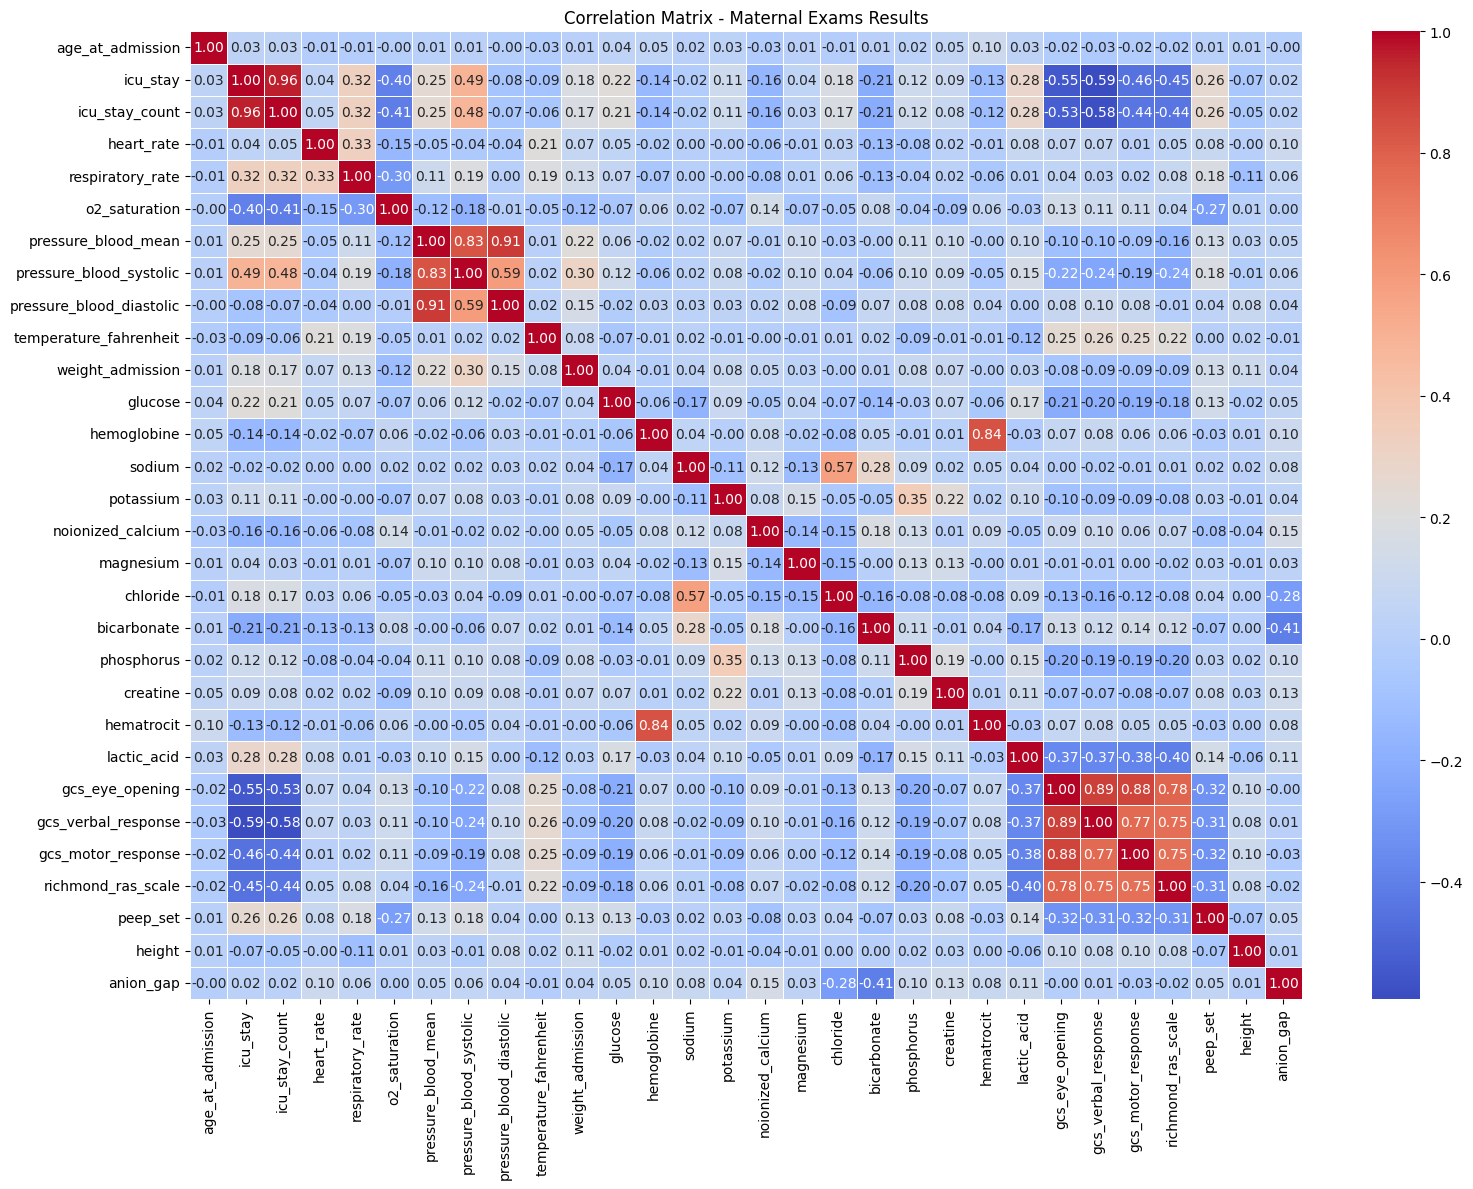

In [12]:
excluded = ['subject_id', 'hadm_id', 'stay_id', 'outcome']
df_correletion = df.drop(columns=[c for c in excluded if c in df.columns])

numeric_cols = df_correletion.select_dtypes(include='number')

correlation_matrix = numeric_cols.corr()

plt.figure(figsize=(16, 12))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Matrix - Maternal Exams Results')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'Fig_Correlacion_Matrix_Maternal_Exams_Results.pdf'), format='pdf', bbox_inches='tight')
plt.savefig(os.path.join(FIG_DIR, 'Fig_Correlacion_Matrix_Maternal_Exams_Results.png'), format='png', dpi=300, bbox_inches='tight')
plt.show()

In [13]:
gdg_cols  = [c for c in df.columns if c.startswith('gdg_')]
excl_cols = ['subject_id', 'hadm_id', 'stay_id', 'dob', 'outcome'] + gdg_cols

df_clinical = df.drop(columns=[c for c in excl_cols if c in df.columns])
clinical_num = df_clinical.select_dtypes(include='number')

corr_clinical = clinical_num.corr()

mask_upper = np.triu(np.ones_like(corr_clinical, dtype=bool), k=1)
high_corr_pairs = (
    corr_clinical
    .where(mask_upper)
    .stack()
    .reset_index()
)
high_corr_pairs.columns = ['feature_1', 'feature_2', 'r']
high_corr_pairs = high_corr_pairs[abs(high_corr_pairs['r']) >= 0.70].sort_values('r', ascending=False)

print(f"Pairs with |r| >= 0.70 among clinical measurement variables: {len(high_corr_pairs)}")
print()
print(high_corr_pairs.to_string(index=False))

Pairs with |r| >= 0.70 among clinical measurement variables: 10

          feature_1                feature_2        r
           icu_stay           icu_stay_count 0.958120
pressure_blood_mean pressure_blood_diastolic 0.906559
    gcs_eye_opening      gcs_verbal_response 0.891065
    gcs_eye_opening       gcs_motor_response 0.881765
        hemoglobine               hematrocit 0.838942
pressure_blood_mean  pressure_blood_systolic 0.832588
    gcs_eye_opening       richmond_ras_scale 0.782897
gcs_verbal_response       gcs_motor_response 0.772601
gcs_verbal_response       richmond_ras_scale 0.753587
 gcs_motor_response       richmond_ras_scale 0.746584


#### **8.1 Correlation decision -- clinical measurement variables**

We expect the usual physiologically-driven pairs to reappear (`hemoglobine` <->
`hematrocit`; `pressure_blood_mean` <-> systolic/diastolic) -- **this must be re-verified once the query runs
against the live database**, since this cohort's own ranges/variability need to be checked directly rather
than assumed. The decision rule is unchanged: **retain all variables**. Random Forest, XGBoost and Extra Trees are insensitive to
multicollinearity (independent per-split feature evaluation); the Logistic Regression base learner is
protected by L2 regularisation. Discarding one variable per pair would remove independently-monitored
clinical signal without a modelling benefit.

#### **8.2 Dropping near-empty ICU-monitoring variables (found via the correlation review)**

`gcs_motor_response` and `richmond_ras_scale` come back with no correlation at all against any other
variable in the heatmap above (blank cells) -- both are Richmond Agitation-Sedation Scale / motor-GCS
readings that MIMIC-IV only charts for sedated or mechanically ventilated ICU patients, a small subset even
among admissions that *did* reach the ICU (unlike heart rate or blood pressure, which are charted for
essentially every ICU patient). Combined with this cohort's own ICU stays being rare overall (Section
2.4.1: 30 of 41 deaths, ~73%, never had an ICU stay), these two end up imputed to a single dominant value
for nearly every admission -- a (near-)zero-variance feature that cannot carry any predictive signal, which
is exactly what an undefined/blank correlation cell signals. They are dropped here, from `df` itself, so
every section from here on (scaling, model dataset, modelling) never sees them again -- the same
"no signal, no reason to keep it" logic already applied to the constant `gender` dummy in Section 10.


In [14]:
near_empty_clinical = ["gcs_motor_response", "richmond_ras_scale"]

print("Post-imputation value distribution for the flagged variables (near-zero-variance check):")
for col in near_empty_clinical:
    if col in df.columns:
        vc = df[col].value_counts(normalize=True, dropna=False)
        dominant_share = vc.iloc[0] * 100 if not vc.empty else float('nan')
        print(f"  {col}: {df[col].nunique(dropna=False)} distinct value(s), "
              f"most common value covers {dominant_share:.1f}% of rows")

df = df.drop(columns=[c for c in near_empty_clinical if c in df.columns])
print(f"\nDropped: {near_empty_clinical}. Remaining columns: {len(df.columns)}")


Post-imputation value distribution for the flagged variables (near-zero-variance check):
  gcs_motor_response: 5 distinct value(s), most common value covers 99.5% of rows
  richmond_ras_scale: 10 distinct value(s), most common value covers 99.3% of rows

Dropped: ['gcs_motor_response', 'richmond_ras_scale']. Remaining columns: 96


Excluding constant (zero-variance) diagnostic groups from this plot: ['gdg_m27', 'gdg_m28']


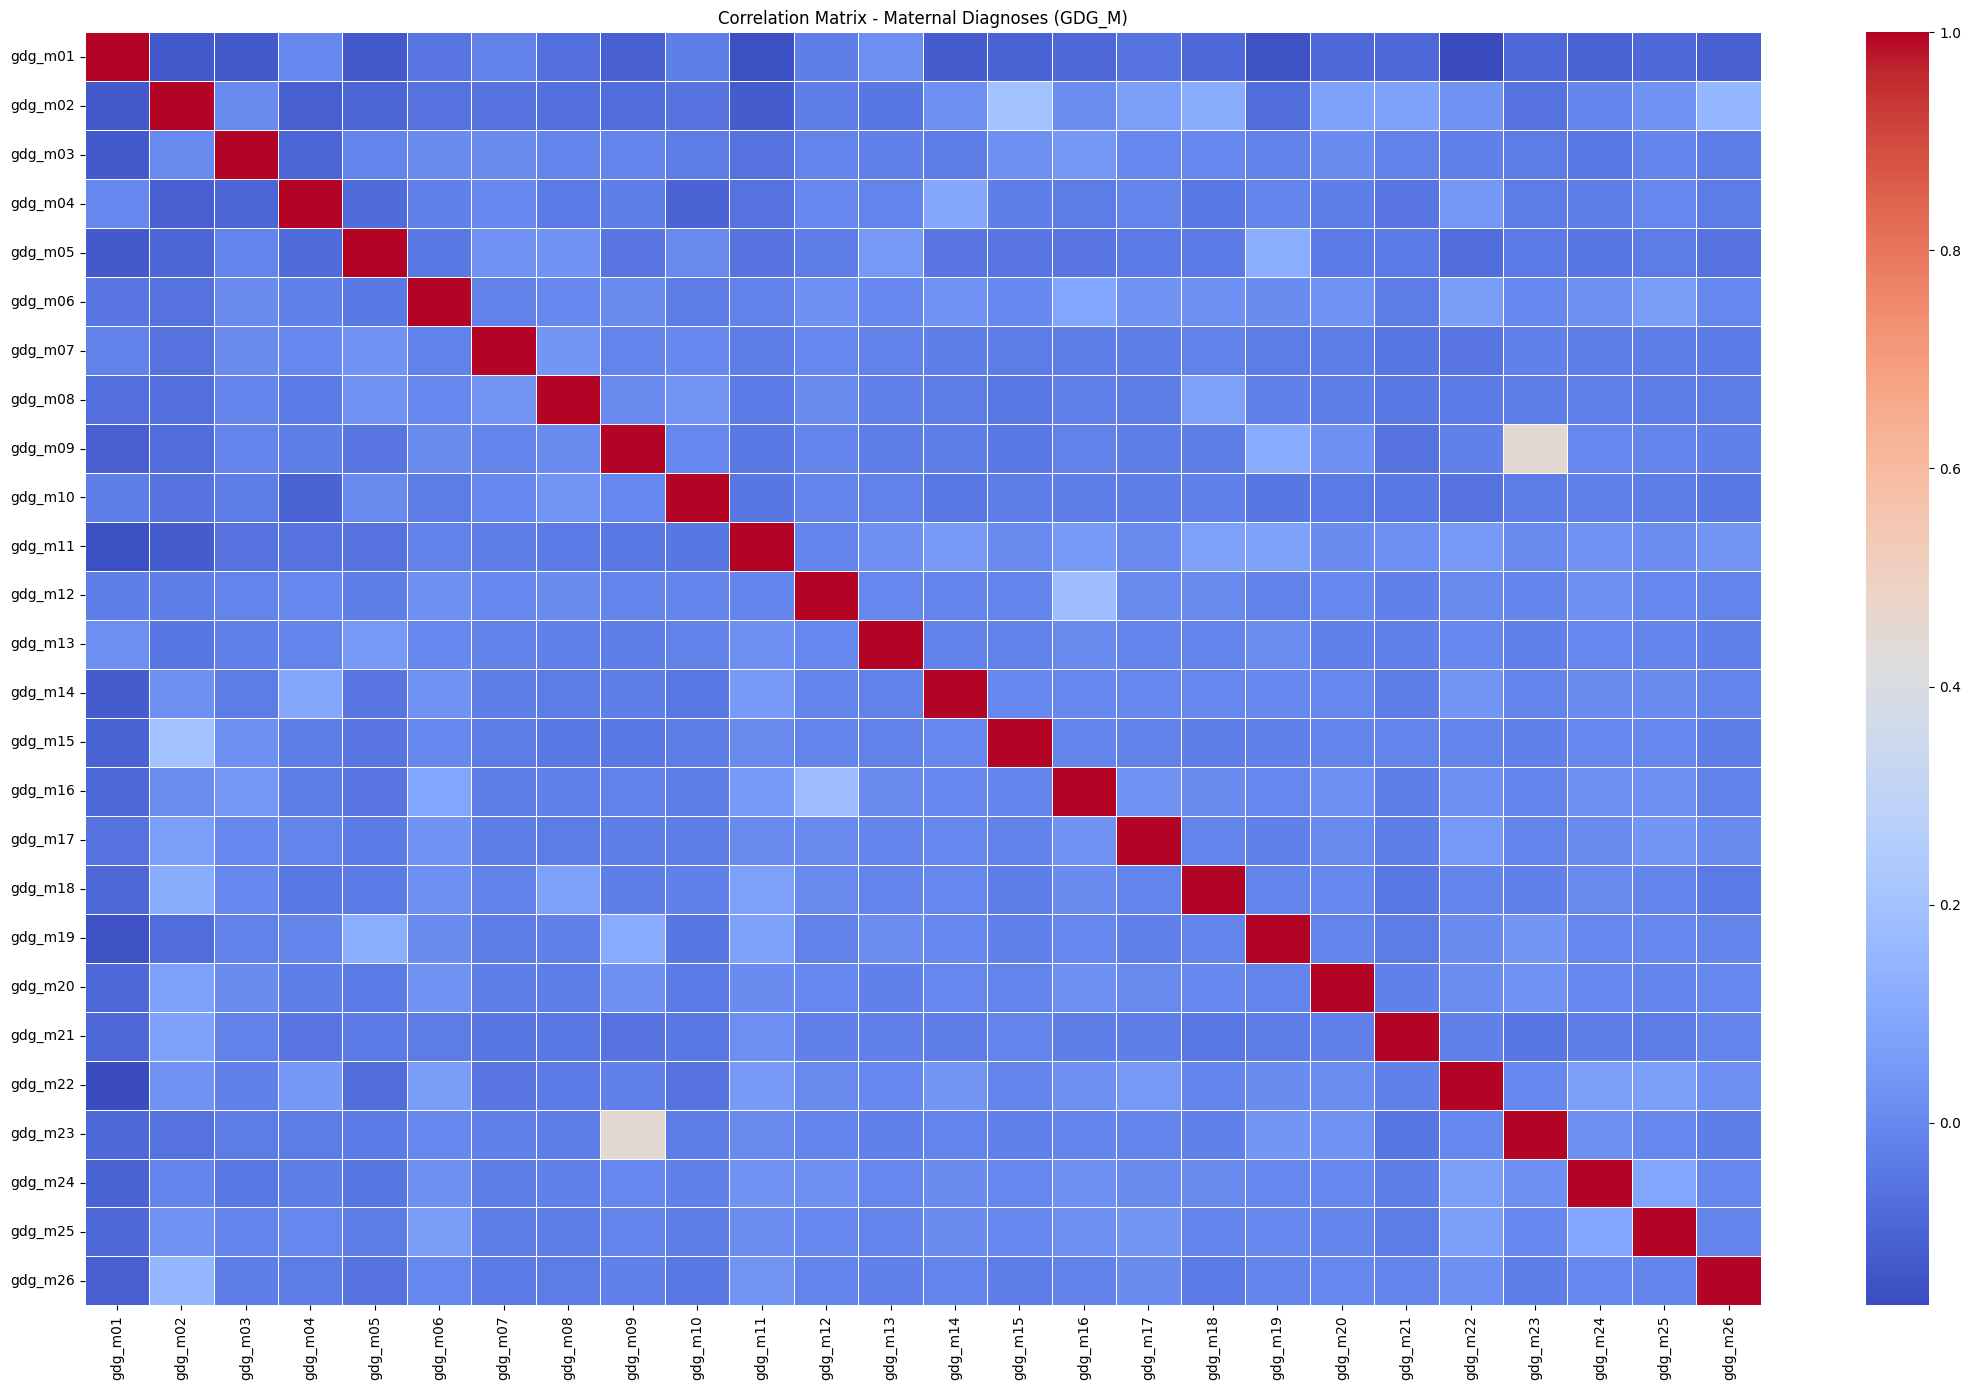

In [15]:
diagnosis_cols = [col for col in df.columns if col.startswith('gdg_') and df[col].dropna().isin([0, 1, True, False]).all()]

# Drop zero-variance diagnostic groups before plotting -- e.g. gdg_m27/gdg_m28, the two
# residual k-means placeholders that were never populated (Section 2.3 turned out to be a
# no-op: the rule-based classification in Section 2.2 already covered 100% of the 4,116 ICD
# codes). A constant column has no correlation to show and would otherwise appear as a blank
# row/column below, same issue as gcs_motor_response/richmond_ras_scale in Section 8.2.
diagnosis_cols_nonconstant = [col for col in diagnosis_cols if df[col].nunique(dropna=False) > 1]
dropped_constant_gdg = sorted(set(diagnosis_cols) - set(diagnosis_cols_nonconstant))
if dropped_constant_gdg:
    print(f"Excluding constant (zero-variance) diagnostic groups from this plot: {dropped_constant_gdg}")
diagnosis_cols = diagnosis_cols_nonconstant

if len(diagnosis_cols) < 2:
    # Nothing to correlate -- almost always because the gdg_* columns are still all-NULL.
    # See the WARNING printed when df was loaded (Section 3): re-run Section 2.5's
    # db_lib.update_feature_diagnoses_dataset_maternal(engine), reload df, and re-run from
    # here. Plotting an empty/1-column correlation matrix would otherwise crash seaborn with
    # "ValueError: zero-size array to reduction operation fmin which has no identity".
    correlation_matrix = pd.DataFrame()
    print(
        f"Skipping this plot: only {len(diagnosis_cols)} non-constant diagnostic-group column(s) "
        "remain after excluding zero-variance ones -- see the WARNING in Section 3 if this is 0 or "
        "much lower than expected (~26-28)."
    )
else:
    correlation_matrix = df[diagnosis_cols].corr()

    plt.figure(figsize=(22, 14))
    sns.heatmap(correlation_matrix, cmap='coolwarm', annot=False, linewidths=0.5)
    plt.title('Correlation Matrix - Maternal Diagnoses (GDG_M)')
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, 'Fig_Correlacion_Matrix_Maternal_Diagnoses.pdf'), format='pdf', bbox_inches='tight')
    plt.savefig(os.path.join(FIG_DIR, 'Fig_Correlacion_Matrix_Maternal_Diagnoses.png'), format='png', dpi=300, bbox_inches='tight')
    plt.show()

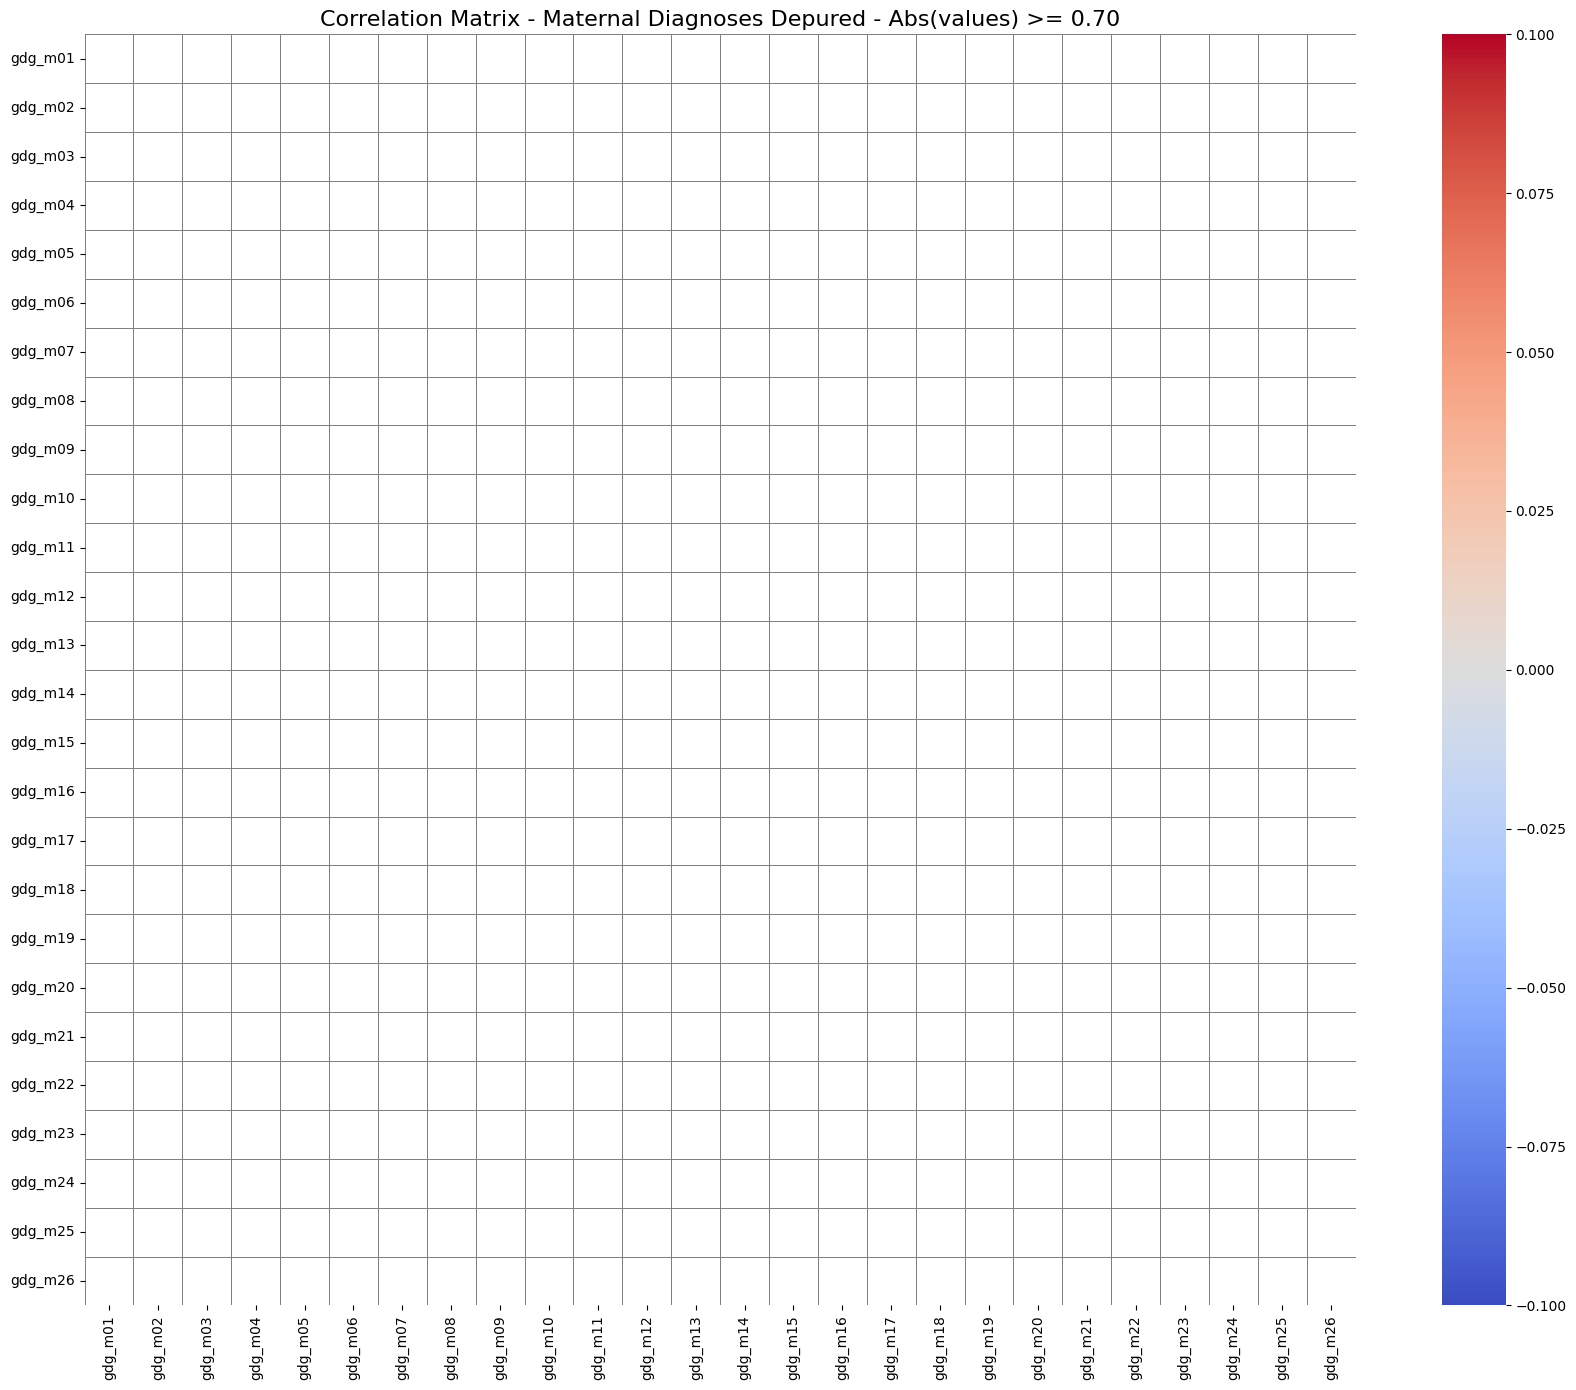

In [16]:
if correlation_matrix.empty:
    # The previous cell had nothing to correlate (see its own message) -- nothing to filter/plot here either.
    print("Skipping this plot: correlation_matrix from the previous cell is empty.")
else:
    filtered_corr = correlation_matrix.copy()

    mask_upper = np.triu(np.ones_like(filtered_corr, dtype=bool))
    filtered_corr = filtered_corr.mask(mask_upper)

    filtered_corr = filtered_corr.where((abs(filtered_corr) >= 0.70) & (abs(filtered_corr) < 1.0))

    mask_to_plot = filtered_corr.isnull()

    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=RuntimeWarning)

        plt.figure(figsize=(18, 14))
        sns.heatmap(filtered_corr, mask=mask_to_plot, annot=True, fmt=".2f", cmap="coolwarm"
                    , cbar=True, square=True, linewidths=0.5, linecolor='gray')
        plt.title("Correlation Matrix - Maternal Diagnoses Depured - Abs(values) >= 0.70", fontsize=16)
        plt.tight_layout()
        plt.savefig(os.path.join(FIG_DIR, 'Fig_Correlacion_Matrix_Maternal_Diagnoses_Depured.pdf'), format='pdf', bbox_inches='tight')
        plt.savefig(os.path.join(FIG_DIR, 'Fig_Correlacion_Matrix_Maternal_Diagnoses_Depured.png'), format='png', dpi=300, bbox_inches='tight')
        plt.show()

### **9. Scaling continuous variables**

Same two-strategy approach used across this thesis's modelling framework, chosen per variable based on
skewness.

##### **9.1. Data distribution -- Histograms with density curve**

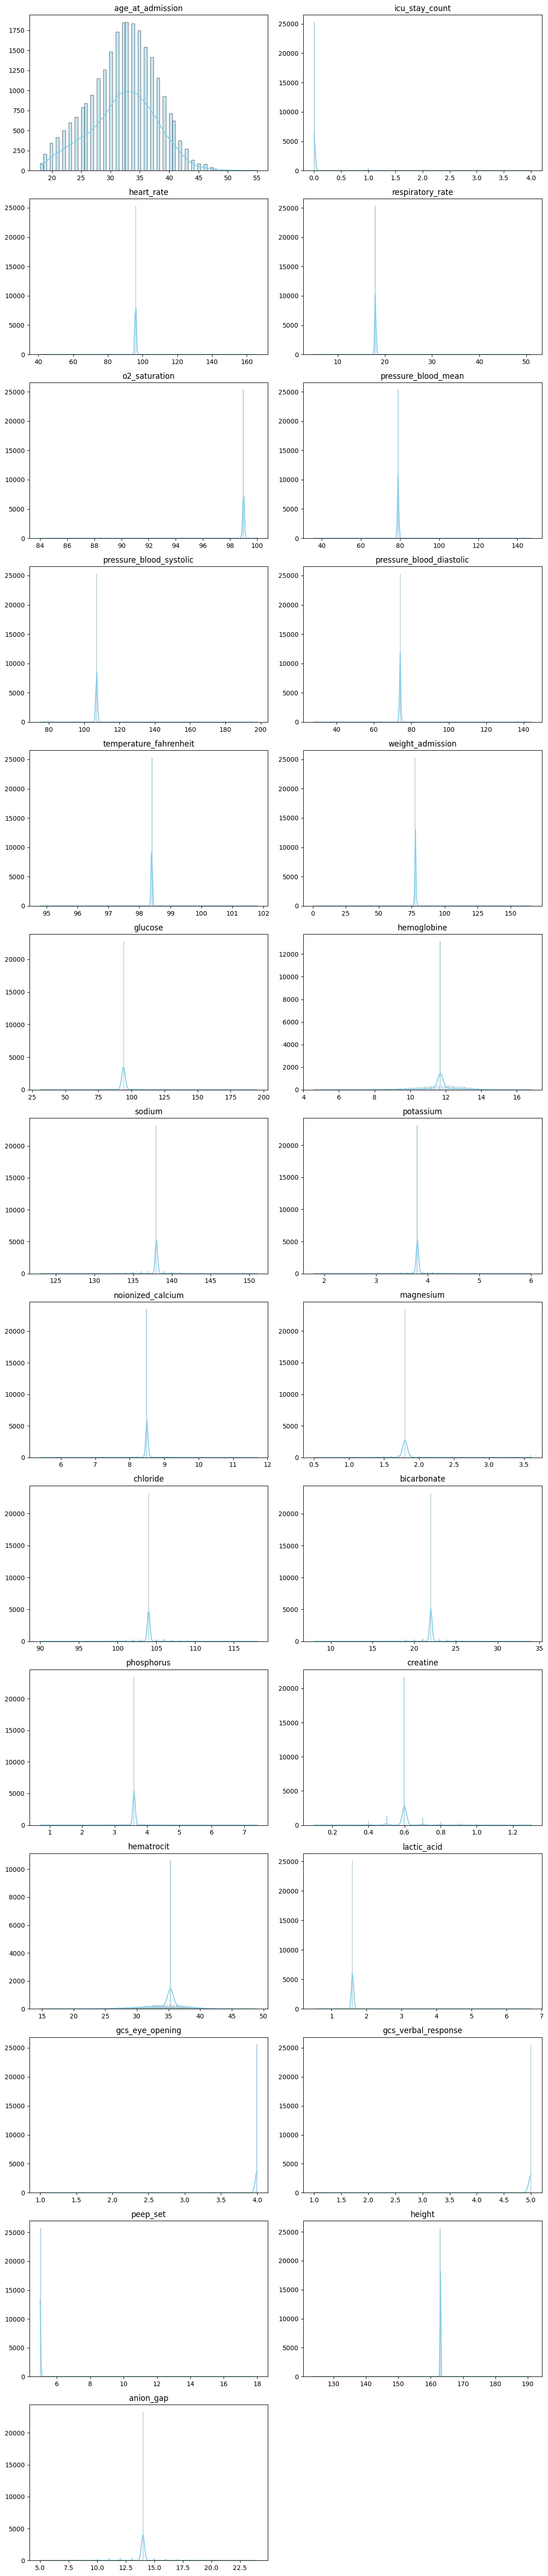

In [17]:
excluded_columns = ['subject_id', 'hadm_id', 'stay_id', 'outcome', 'icu_stay']
df_scalling = df.drop(columns=[c for c in excluded_columns if c in df.columns])

numeric_cols = df_scalling.select_dtypes(include='number').columns

cols_per_row = 2
total_plots = len(numeric_cols)
rows = math.ceil(total_plots / cols_per_row)
fig, axes = plt.subplots(rows, cols_per_row, figsize=(cols_per_row * 6, rows * 4))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    sns.histplot(df_scalling[col].dropna(), kde=True, ax=axes[i], color='skyblue')
    axes[i].set_title(col)
    axes[i].set_xlabel('')
    axes[i].set_ylabel('')

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

##### **9.2. Define the scaling technique for each continuous feature**

Same rule: `|skew| > 1` -> `RobustScaler`; `|skew| <= 1` -> `MinMaxScaler`.

In [18]:
numeric_cols = df_scalling.select_dtypes(include=['number']).columns

def recommend_scaling(df_scalling, col):
    if df_scalling[col].skew() > 1 or df_scalling[col].skew() < -1:
        return 'RobustScaler', df_scalling[col].skew(), df_scalling[col].max() - df_scalling[col].min()
    else:
        return 'MinMaxScaler', df_scalling[col].skew(), df_scalling[col].max() - df_scalling[col].min()

recommendations = []

for col in numeric_cols:
    recomendation, skew, max_minus_min = recommend_scaling(df_scalling, col)
    recommendations.append({
                            'column': col
                            ,'technique': recomendation
                            ,'skew': skew
                            ,'max-min': max_minus_min
                            })

scaling_recommendations = pd.DataFrame(recommendations)
scaling_recommendations

,column,technique,skew,max-min
0,age_at_admission,MinMaxScaler,-0.125333,37.0
1,icu_stay_count,RobustScaler,8.735181,4.0
2,heart_rate,RobustScaler,3.417138,125.0
3,respiratory_rate,RobustScaler,12.289597,46.0
4,o2_saturation,RobustScaler,-18.137874,16.0
5,pressure_blood_mean,RobustScaler,8.104621,111.0
6,pressure_blood_systolic,RobustScaler,11.986161,123.0
7,pressure_blood_diastolic,RobustScaler,1.000780,116.0
8,temperature_fahrenheit,RobustScaler,-3.819398,7.0
9,weight_admission,RobustScaler,13.123426,164.5


In [19]:
# Export dataset (pre-scaling) for audit
df.to_excel('../data/df_cohort_maternal_dataset.xlsx', index=False)

#### **9.3. Scaling**

In [20]:
df_scaled = df.copy()

for _, row in scaling_recommendations.iterrows():

    col = row['column']
    method = row['technique']

    if method == 'StandardScaler':
        scaler = StandardScaler()
    elif method == 'MinMaxScaler':
        scaler = MinMaxScaler()
    elif method == 'RobustScaler':
        scaler = RobustScaler()
    else:
        continue

    df_scaled[col + '_scaled'] = scaler.fit_transform(df[[col]])

df_scaled[[col + '_scaled' for col in scaling_recommendations['column'].head(5)]].head()

,age_at_admission_scaled,icu_stay_count_scaled,heart_rate_scaled,respiratory_rate_scaled,o2_saturation_scaled
0,0.378378,0.0,0.0,0.0,0.0
1,0.405405,0.0,0.0,0.0,0.0
2,0.351351,0.0,0.0,0.0,0.0
3,0.540541,0.0,0.0,0.0,0.0
4,0.432432,0.0,0.0,0.0,0.0


In [21]:
df_scaled.to_excel("../data/df_scaled_cohort_maternal_dataset.xlsx", index=False)
print("Scalling complete. Shape:", df_scaled.shape)

Scalling complete. Shape: (25736, 123)


### **10. Build model dataset**

Same assembly rule used across this thesis's modelling framework -- identifiers dropped, raw (unscaled)
numeric columns dropped in favour of their `_scaled` counterparts -- **plus an explicit zero-variance
check**, since `gender` is constant (`F`) in this cohort by construction and any resulting dummy column
should not enter the classifiers.

In [22]:
id_cols = ["subject_id","hadm_id","stay_id","dob"]
raw_numeric = [name for name, _ in [
    ("heart_rate",None),("respiratory_rate",None),("o2_saturation",None),
    ("pressure_blood_mean",None),("pressure_blood_systolic",None),("pressure_blood_diastolic",None),
    ("temperature_fahrenheit",None),("weight_admission",None),("glucose",None),("hemoglobine",None),
    ("sodium",None),("potassium",None),("noionized_calcium",None),("magnesium",None),("chloride",None),
    ("bicarbonate",None),("phosphorus",None),("creatine",None),("hematrocit",None),("lactic_acid",None),
    ("gcs_eye_opening",None),("gcs_verbal_response",None),("gcs_motor_response",None),
    ("richmond_ras_scale",None),("peep_set",None),("height",None),("anion_gap",None),
    ("age_at_admission",None),("icu_stay_count",None)
]]

df_model = df_scaled.sort_values('subject_id').reset_index(drop=True)

col_to_drop = id_cols + [c for c in raw_numeric if c in df_scaled.columns]
df_model = df_model.drop(columns=[c for c in col_to_drop if c in df_scaled.columns])
df_model = df_model.reset_index(drop=True)

# Drop zero-variance columns (e.g. gender_* dummies, constant by cohort construction)
constant_cols = [c for c in df_model.columns if c != "outcome" and df_model[c].nunique(dropna=False) <= 1]
if constant_cols:
    print(f"Dropping {len(constant_cols)} zero-variance columns: {constant_cols}")
    df_model = df_model.drop(columns=constant_cols)

print(f"Model Features: {len(df_model.columns) - 1}")
print(df_model.columns.tolist())

Dropping 2 zero-variance columns: ['gdg_m27', 'gdg_m28']
Model Features: 89
['outcome', 'icu_stay', 'gdg_m01', 'gdg_m02', 'gdg_m03', 'gdg_m04', 'gdg_m05', 'gdg_m06', 'gdg_m07', 'gdg_m08', 'gdg_m09', 'gdg_m10', 'gdg_m11', 'gdg_m12', 'gdg_m13', 'gdg_m14', 'gdg_m15', 'gdg_m16', 'gdg_m17', 'gdg_m18', 'gdg_m19', 'gdg_m20', 'gdg_m21', 'gdg_m22', 'gdg_m23', 'gdg_m24', 'gdg_m25', 'gdg_m26', 'ethnicity_group_AFRO_DESC', 'ethnicity_group_ASIAN', 'ethnicity_group_HISPANIC', 'ethnicity_group_INDIAN_USA', 'ethnicity_group_PACIFIC_ISL', 'ethnicity_group_UNKNOWN', 'ethnicity_group_WHITE_UE', 'ethnicity_group_WHITE_USA', 'insurance_MEDICAID', 'insurance_MEDICARE', 'insurance_NO_CHARGE', 'insurance_OTHERS', 'insurance_PRIVATE', 'language_group_AFROASIAN_LANG', 'language_group_GERMANIC_LANG', 'language_group_INDOEUR_LANG', 'language_group_NATIVE_LANG', 'language_group_ORIENTAL_LANG', 'language_group_OTHERS_LANG', 'language_group_ROMANCE_LANG', 'language_group_SIGN_LANG', 'language_group_SLAVIC_LANG', 'a

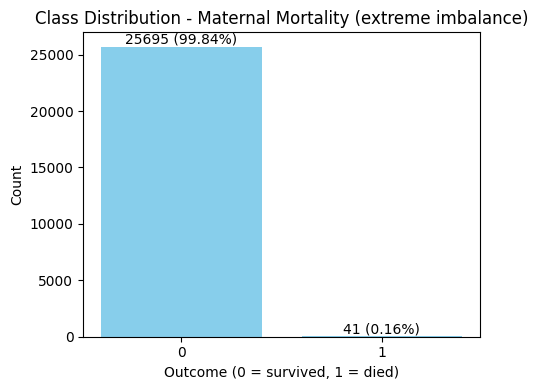

In [23]:
count_y = df_model['outcome'].value_counts().sort_index()

total = count_y.sum()
percentages = (count_y / total) * 100

plt.figure(figsize=(5, 4))

bars = plt.bar(count_y.index.astype(str), count_y.values, color='skyblue')

for bar, cantidad, percentaje in zip(bars, count_y.values, percentages.values):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
                f'{cantidad} ({percentaje:.2f}%)',
                ha='center', va='bottom', fontsize=10
            )

plt.title('Class Distribution - Maternal Mortality (extreme imbalance)')
plt.xlabel('Outcome (0 = survived, 1 = died)')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### **11. Train / Test Split -- Handling an Extreme Class Imbalance**

This is the point where this cohort's extreme rarity requires deliberately adapting the framework's usual
train/test approach, and it must be documented with full academic honesty.

**The problem.** The maternal cohort has only **41 positive cases out of 25,736 (~0.159%)**. A standard
80/20 stratified split would leave:

- Train: ~20,556 negatives / ~33 positives
- Test:  ~5,139 negatives / **~8 positives**

Evaluating on ~8 positive test cases makes any single point-estimate of recall, precision or F1 for the
minority class **extremely unstable** -- misclassifying just one or two of those cases swings the recall
by a large margin. A single train/test split is **not sufficient evidence of generalisation here**.

**Design decisions adopted for this model:**

1. **Keep a single stratified 80/20 hold-out** for a *final, illustrative*
   report -- but its point estimates for the minority class must be reported with explicit uncertainty
   (e.g. exact/Wilson confidence intervals for recall given n~8), not as a precise number.
2. **Add repeated Stratified K-Fold cross-validation** (`StratifiedKFold`, k=5, and ideally repeated with
   multiple seeds) as the *primary* evidence of model performance -- every fold keeps the ~0.159% prevalence,
   giving ~8 positive cases per fold across 5 folds, and aggregating across folds is far more robust than
   a single split.
3. **Metrics robust to imbalance**, reported alongside ROC-AUC:
   - **PR-AUC / Average Precision** -- more informative than ROC-AUC under extreme imbalance, since ROC-AUC
     can look deceptively good while precision for the positive class stays very low.
   - **Recall (sensitivity)** for the positive class -- the clinically critical metric (a missed maternal
     death is the costliest error).
   - **F1-score** and **balanced accuracy** as secondary summaries.
4. **Class-imbalance handling from this thesis's modelling framework** is applied here:
   `class_weight="balanced"` / `"balanced_subsample"` (Random Forest, Extra Trees), `scale_pos_weight`
   (XGBoost), `class_weight="balanced"` (Logistic Regression). **SMOTE** (already imported in Section 1,
   via `imblearn`) is offered as an *optional* oversampling step for the minority class inside the
   cross-validation loop (via `imblearn.pipeline.Pipeline` so resampling only touches the training folds,
   never the validation fold) -- recommended as a sensitivity analysis rather than a default, since
   synthetic oversampling with only ~33 real positive training examples carries a real risk of generating
   unrealistic synthetic patients.

> **Bottom line for the thesis discussion:** with 41 positive cases in the entire dataset, *no* held-out
> evaluation -- single split or k-fold -- can produce narrow, reliable confidence intervals. The results
> should be framed as **exploratory / hypothesis-generating**, and external validation (a different MIMIC
> cohort window, or an entirely different database) should be recommended as future work before any
> clinical-deployment claim.

In [24]:
X = df_model.drop(columns=["outcome"])
y = df_model["outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Train: {X_train.shape}  |  Test: {X_test.shape}")
print(f"Prevalencia positiva -- Train: {y_train.mean():.5f} ({y_train.sum()} casos)  |  "
      f"Test: {y_test.mean():.5f} ({y_test.sum()} casos)")

# Primary evidence: repeated Stratified K-Fold (documented in the markdown above)
N_SPLITS = 5
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=42)

cv_scoring = {
    "roc_auc": "roc_auc",
    "average_precision": "average_precision",
    "recall": "recall",
    "f1": "f1",
    "balanced_accuracy": "balanced_accuracy",
}

def run_cv_diagnostics(model, X_data, y_data, label):
    """Sanity-check cross-validated performance before/alongside GridSearchCV tuning."""
    scores = cross_validate(model, X_data, y_data, cv=skf, scoring=cv_scoring, n_jobs=-1)
    summary = {metric: (np.mean(scores[f"test_{metric}"]), np.std(scores[f"test_{metric}"]))
               for metric in cv_scoring}
    print(f"--- {label} ({N_SPLITS}-fold Stratified CV) ---")
    for metric, (m, s) in summary.items():
        print(f"  {metric:20s}: {m:.3f} +/- {s:.3f}")
    return summary

Train: (20588, 89)  |  Test: (5148, 89)
Prevalencia positiva -- Train: 0.00160 (33 casos)  |  Test: 0.00155 (8 casos)


### **12. Run Models**

Same five models used across this thesis's modelling framework (Random Forest, XGBoost, Extra Trees,
Logistic Regression, Stacking), trained with `GridSearchCV` (5-fold, `n_jobs=-1`). Given the extremely
small number of positive cases, the scoring metric for `GridSearchCV` is switched from plain `'f1'` to
**`'average_precision'`**, which is more informative for ranking hyperparameters under severe imbalance;
`'f1'` is still reported at evaluation time for comparability across models. Hyperparameter grids are also
kept intentionally small/coarse, both to control compute cost and because a large grid searched over ~33
positive training examples is prone to overfitting the search itself.

`run_model` and `plot_roc` follow the same pattern used across this thesis's modelling framework;
`plot_pr` is added to visualise the Precision-Recall curve, the more diagnostic curve for this cohort's
prevalence.

In [25]:
def run_model(p_model, p_param_grid, p_X_train, p_y_train, p_X_test, p_y_test, title_model, nombre_imagen,
              scoring='average_precision'):

    with open(os.devnull, 'w') as f, redirect_stdout(f):

        grid_search = GridSearchCV(estimator=p_model
                                   , param_grid=p_param_grid
                                   , scoring=scoring
                                   , cv=skf
                                   , verbose=1
                                   , n_jobs=-1
                                   )

        grid_search.fit(p_X_train, p_y_train)

    best_model = grid_search.best_estimator_

    best_params_formatted = ', '.join(f'{key}: {value}' for key, value in grid_search.best_params_.items())

    # Hard labels: correct here, for the classification report / confusion
    # matrix below, which need one discrete class per row.
    y_pred_model = best_model.predict(p_X_test)
    # BUGFIX (2026-09-17): predicted PROBABILITY of the positive class, for the
    # ROC/PR curves via plot_roc/plot_pr below (see README status item 2).
    # Scoring those curves from hard 0/1 predictions instead of predict_proba
    # collapses the ROC curve to a single interior point (plus the two trivial
    # corners), which understates the model's real discriminative power.
    y_proba_model = best_model.predict_proba(p_X_test)[:, 1]

    report_dict = classification_report(p_y_test, y_pred_model, output_dict=True)
    report_df = pd.DataFrame(report_dict).transpose()
    report_df = report_df.round(2)

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    sns.heatmap(report_df.iloc[:-1, :-1], annot=True, cmap="YlGnBu", cbar=False, ax=axes[0])
    axes[0].set_title("Best hyperparams: " + best_params_formatted, fontsize=8)
    axes[0].set_ylabel("Classes")
    axes[0].set_xlabel("Metrics")
    axes[0].tick_params(axis='y', rotation=0)

    cm = confusion_matrix(p_y_test, y_pred_model)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=best_model.classes_)
    disp.plot(cmap='Blues', ax=axes[1], colorbar=False)
    axes[1].set_title("Confusion Matrix", fontsize=8)

    fig.suptitle(title_model, fontsize=12, weight='bold')

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.savefig(os.path.join(FIG_DIR, nombre_imagen + '.pdf'), format='pdf', bbox_inches='tight')
    plt.savefig(os.path.join(FIG_DIR, nombre_imagen + '.png'), format='png', dpi=300, bbox_inches='tight')
    plt.show()

    return best_model, y_pred_model, y_proba_model


def plot_roc(y_test, y_score, title, nombre_imagen):
    """y_score must be the predicted PROBABILITY of the positive class
    (e.g. best_model.predict_proba(X)[:, 1]), not a hard 0/1 prediction --
    see the BUGFIX note in run_model above."""
    fpr, tpr, _ = roc_curve(y_test, y_score)
    roc_auc = auc(fpr, tpr)
    plt.figure(figsize=(5,4))
    plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}")
    plt.plot([0,1],[0,1],"k--")
    plt.xlabel("FPR"); plt.ylabel("TPR")
    plt.title(f"ROC -- {title}")
    plt.legend()
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, nombre_imagen + '.pdf'), format='pdf', bbox_inches='tight')
    plt.savefig(os.path.join(FIG_DIR, nombre_imagen + '.png'), format='png', dpi=300, bbox_inches='tight')
    plt.show()
    return roc_auc


def plot_pr(y_test, y_score, title, nombre_imagen):
    """y_score must be the predicted PROBABILITY of the positive class
    (e.g. best_model.predict_proba(X)[:, 1]), not a hard 0/1 prediction --
    see the BUGFIX note in run_model above."""
    precision, recall, _ = precision_recall_curve(y_test, y_score)
    avg_precision = average_precision_score(y_test, y_score)
    plt.figure(figsize=(5,4))
    plt.plot(recall, precision, label=f"AP = {avg_precision:.3f}")
    baseline = y_test.mean()
    plt.axhline(baseline, color="k", linestyle="--", label=f"Baseline (prevalence) = {baseline:.4f}")
    plt.xlabel("Recall"); plt.ylabel("Precision")
    plt.title(f"Precision-Recall -- {title}")
    plt.legend()
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, nombre_imagen + '.pdf'), format='pdf', bbox_inches='tight')
    plt.savefig(os.path.join(FIG_DIR, nombre_imagen + '.png'), format='png', dpi=300, bbox_inches='tight')
    plt.show()
    return avg_precision

#### **12.1. Random Forest**

--- Random Forest (pre-tuning sanity check) (5-fold Stratified CV) ---
  roc_auc             : 0.763 +/- 0.083
  average_precision   : 0.136 +/- 0.068
  recall              : 0.000 +/- 0.000
  f1                  : 0.000 +/- 0.000
  balanced_accuracy   : 0.500 +/- 0.000


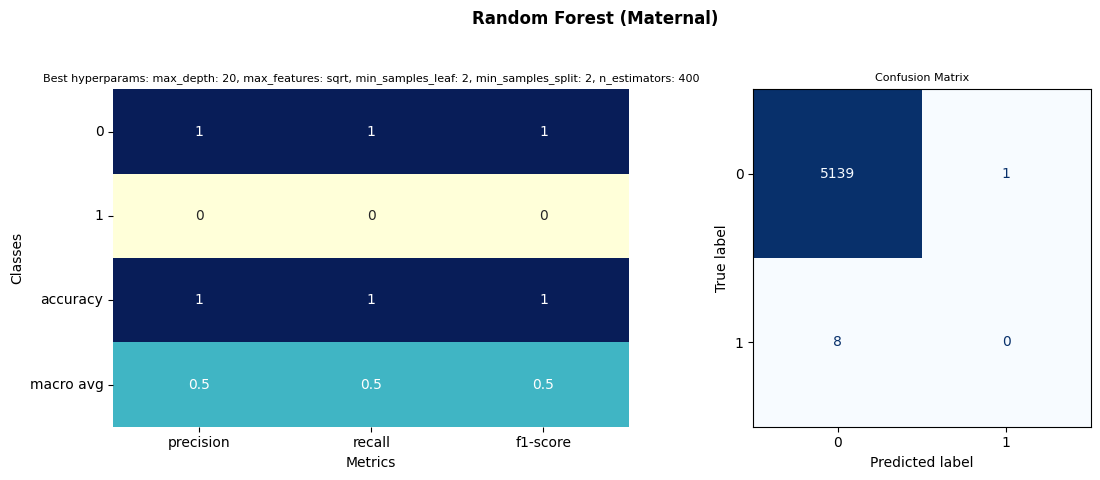

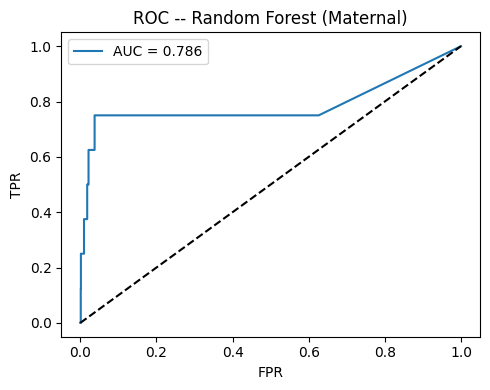

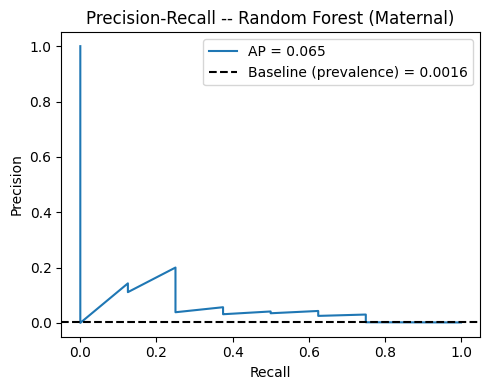

In [26]:
model_rf = RandomForestClassifier(class_weight="balanced_subsample", random_state=42)

param_grid_rf = {
    "n_estimators": [400],
    "max_depth": [20, 30, None],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [2, 4],
    "max_features": ["sqrt"],
}

run_cv_diagnostics(model_rf, X_train, y_train, "Random Forest (pre-tuning sanity check)")

best_model_rf, y_pred_rf, y_proba_rf = run_model(
    model_rf, param_grid_rf, X_train, y_train, X_test, y_test, "Random Forest (Maternal)", "Fig_RF_Maternal_Model"
)
auc_rf = plot_roc(y_test, y_proba_rf, "Random Forest (Maternal)", "Fig_ROC_RF_Maternal")
ap_rf  = plot_pr(y_test, y_proba_rf, "Random Forest (Maternal)", "Fig_PR_RF_Maternal")

Original features:  89
Selected features: 70
Dropped features:    19
Importance threshold: 0.00055


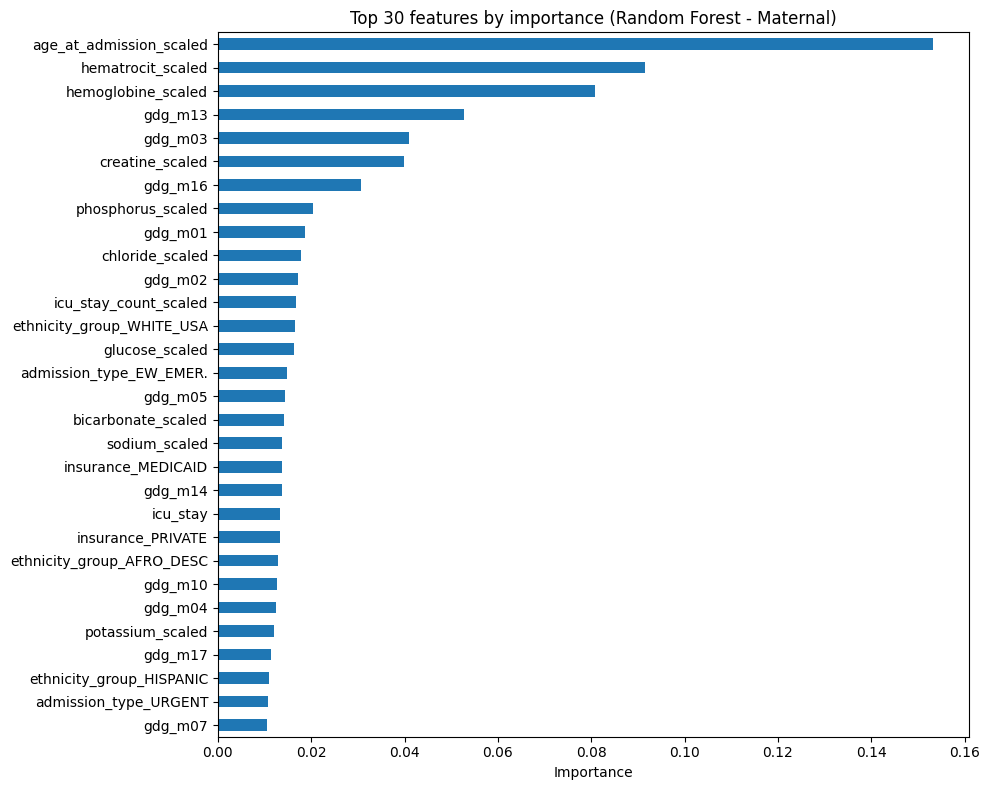

In [27]:
importances = pd.Series(best_model_rf.feature_importances_, index=X.columns)
importances = importances.sort_values(ascending=False)

threshold = importances.mean() - 0.5 * importances.std()
selected_features = importances[importances >= threshold].index.tolist()
dropped_features  = importances[importances <  threshold].index.tolist()

print(f"Original features:  {len(importances)}")
print(f"Selected features: {len(selected_features)}")
print(f"Dropped features:    {len(dropped_features)}")
print(f"Importance threshold: {threshold:.5f}")

plt.figure(figsize=(10,8))
importances.head(30).sort_values().plot(kind="barh")
plt.title("Top 30 features by importance (Random Forest - Maternal)")
plt.xlabel("Importance")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'Top_30_Feature_Maternal.pdf'), format='pdf', bbox_inches='tight')
plt.savefig(os.path.join(FIG_DIR, 'Top_30_Feature_Maternal.png'), format='png', dpi=300, bbox_inches='tight')
plt.show()

#### **12.2. XGBoost**

scale_pos_weight: 622.9


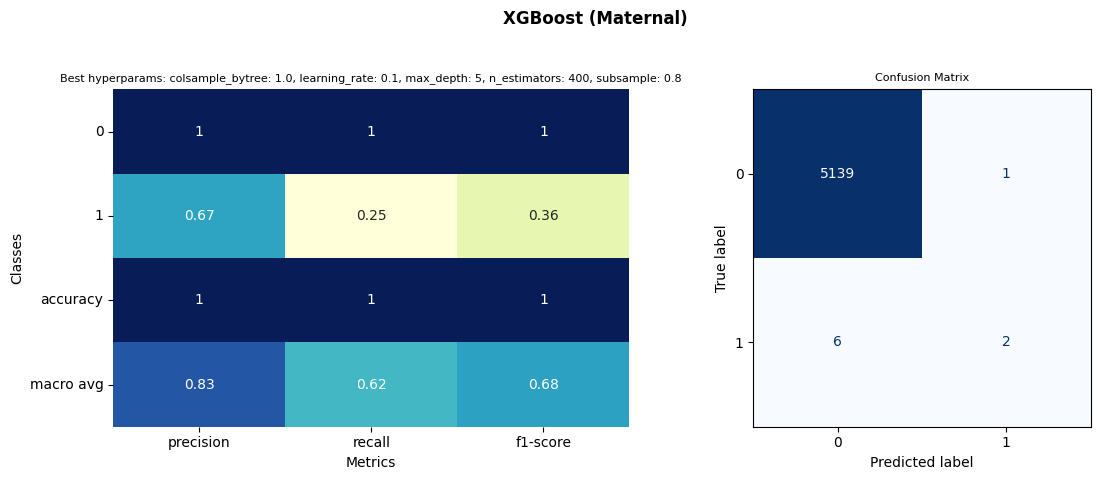

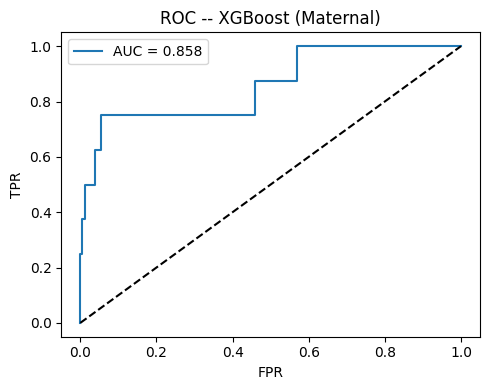

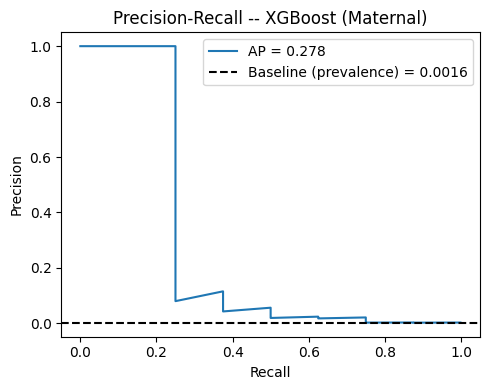

In [28]:
scale_pos_weight = len(y_train[y_train == 0]) / len(y_train[y_train == 1])
print(f"scale_pos_weight: {scale_pos_weight:.1f}")

model_xgb = XGBClassifier(
    scale_pos_weight=scale_pos_weight, eval_metric="logloss", random_state=42
)

param_grid_xgb = {
    "n_estimators": [200, 400],
    "max_depth": [3, 5],
    "learning_rate": [0.01, 0.05, 0.1],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0],
}

best_model_xgb, y_pred_xgb, y_proba_xgb = run_model(
    model_xgb, param_grid_xgb,
    X_train, y_train, X_test, y_test,
    "XGBoost (Maternal)", "Fig_XGBoost_Maternal_Model"
)
auc_xgb = plot_roc(y_test, y_proba_xgb, "XGBoost (Maternal)", "Fig_ROC_XGBoost_Maternal")
ap_xgb  = plot_pr(y_test, y_proba_xgb, "XGBoost (Maternal)", "Fig_PR_XGBoost_Maternal")

#### **12.3. Extra Trees**

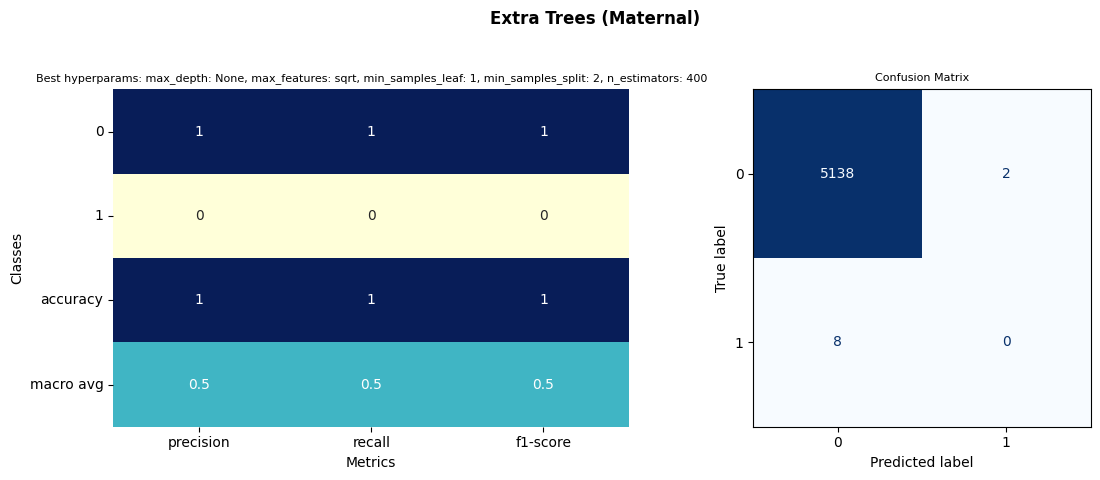

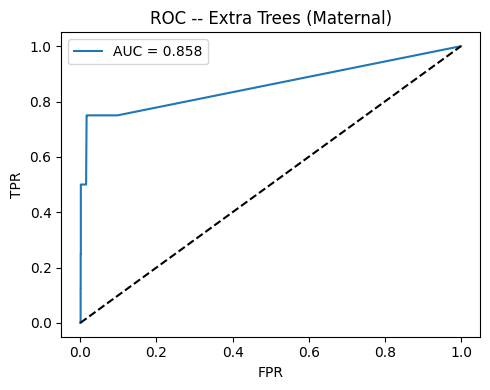

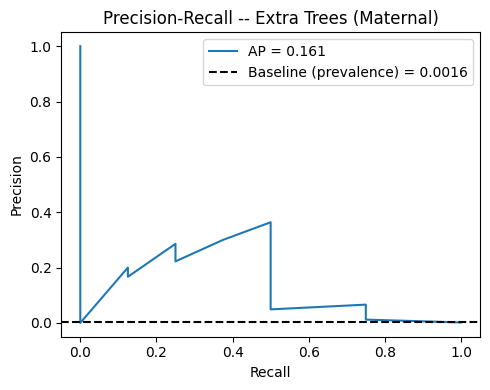

In [29]:
model_et = ExtraTreesClassifier(random_state=42, n_jobs=-1, class_weight="balanced")

param_grid_et = {
    "n_estimators": [300, 400],
    "max_depth": [None, 20, 30],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
    "max_features": ["sqrt"],
}

best_model_et, y_pred_et, y_proba_et = run_model(
    model_et, param_grid_et,
    X_train, y_train, X_test, y_test,
    "Extra Trees (Maternal)", "Fig_Extra_Tree_Maternal_Model"
)
auc_et = plot_roc(y_test, y_proba_et, "Extra Trees (Maternal)", "Fig_ROC_Extra_Trees_Maternal")
ap_et  = plot_pr(y_test, y_proba_et, "Extra Trees (Maternal)", "Fig_PR_Extra_Trees_Maternal")

#### **12.4. Logistic Regression**

C:\Users\egutierrez.FINGEOSEL\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


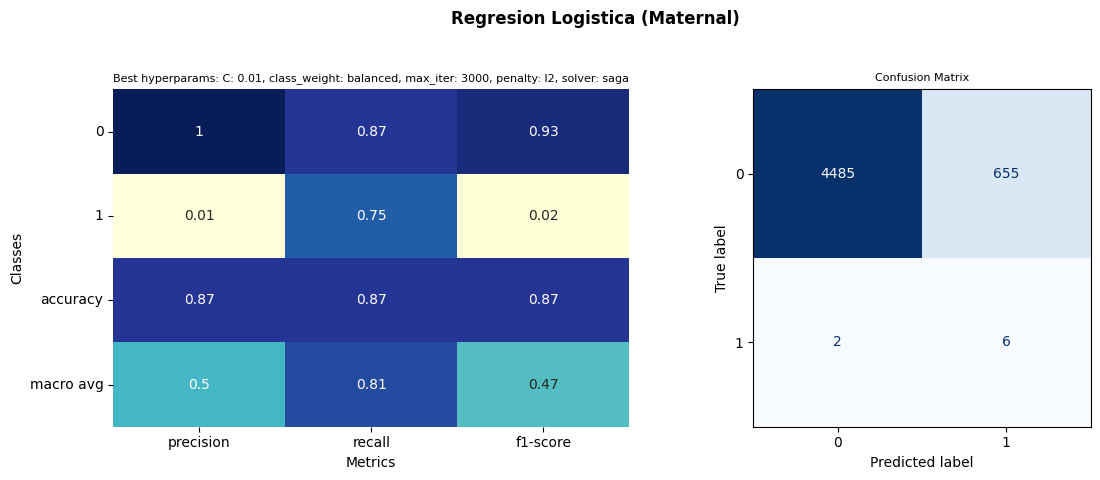

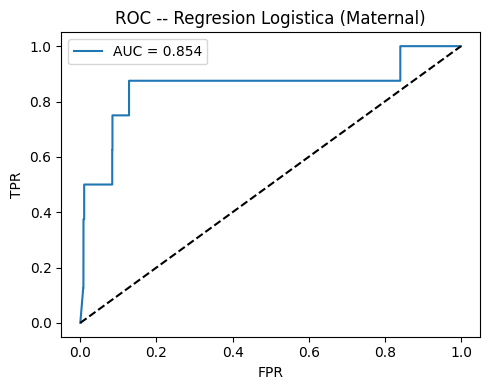

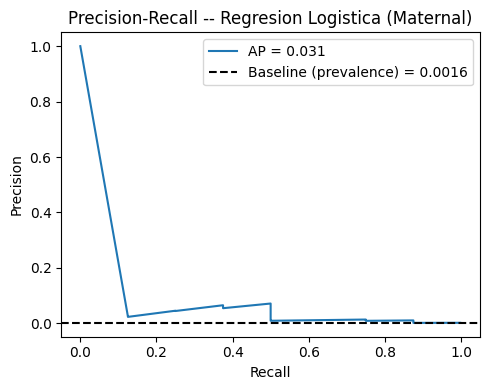

In [30]:
model_rl = LogisticRegression()

param_grid_rl = {
    "penalty": ["l2"],
    "C": [0.01, 0.1, 1, 5],
    "solver": ["lbfgs", "saga"],
    "max_iter": [3000],
    "class_weight": ["balanced"],
}

best_model_rl, y_pred_rl, y_proba_rl = run_model(
    model_rl, param_grid_rl,
    X_train, y_train, X_test, y_test,
    "Regresion Logistica (Maternal)", "Fig_RL_Maternal_Model"
)
auc_rl = plot_roc(y_test, y_proba_rl, "Regresion Logistica (Maternal)","Fig_ROC_RL_Maternal")
ap_rl  = plot_pr(y_test, y_proba_rl, "Regresion Logistica (Maternal)", "Fig_PR_RL_Maternal")

#### **12.5. Stacked Ensemble Model**

Same stacking architecture used across this thesis's modelling framework: the four tuned base estimators
feed a `StackingClassifier` whose meta-learner is an L2-regularised, class-weighted `LogisticRegression`.

In [31]:
estimators = [
    ("rf",  best_model_rf),
    ("xgb", best_model_xgb),
    ("et",  best_model_et),
    ("rl",  best_model_rl),
]

stacking_clf = StackingClassifier(
    estimators=estimators,
    final_estimator=LogisticRegression(
        penalty="l2", C=0.1, solver="lbfgs",
        max_iter=5000, class_weight="balanced", random_state=42
    ),
    cv=skf, n_jobs=-1
)

stacking_clf.fit(X_train, y_train)
y_pred_stack = stacking_clf.predict(X_test)
# BUGFIX (2026-09-17): probability of the positive class, for the ROC/PR
# curves in the next cell -- see the BUGFIX note in run_model (Section 12).
y_proba_stack = stacking_clf.predict_proba(X_test)[:, 1]

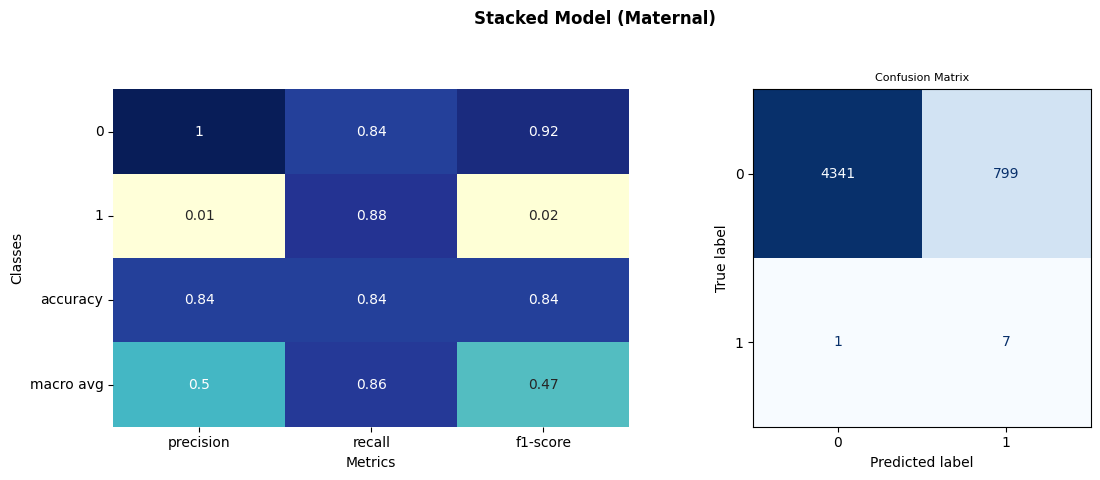

In [32]:
report_dict = classification_report(y_test, y_pred_stack, output_dict=True)
report_df = pd.DataFrame(report_dict).transpose()
report_df = report_df.round(2)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(report_df.iloc[:-1, :-1], annot=True, cmap="YlGnBu", cbar=False, ax=axes[0])
axes[0].set_title("", fontsize=8)
axes[0].set_ylabel("Classes")
axes[0].set_xlabel("Metrics")
axes[0].tick_params(axis='y', rotation=0)

cm = confusion_matrix(y_test, y_pred_stack)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=stacking_clf.classes_)
disp.plot(cmap='Blues', ax=axes[1], colorbar=False)
axes[1].set_title("Confusion Matrix", fontsize=8)

fig.suptitle("Stacked Model (Maternal)", fontsize=12, weight='bold')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig(os.path.join(FIG_DIR, 'Fig_Stacked_Maternal_Model.pdf'), format='pdf', bbox_inches='tight')
plt.savefig(os.path.join(FIG_DIR, 'Fig_Stacked_Maternal_Model.png'), format='png', dpi=300, bbox_inches='tight')
plt.show()

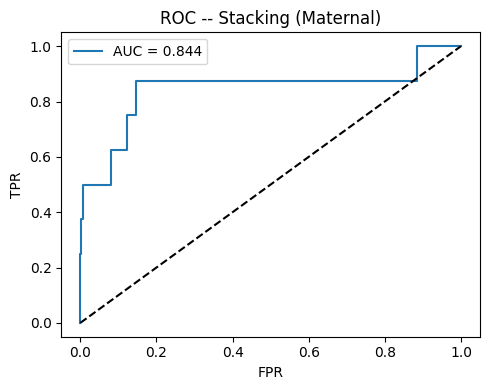

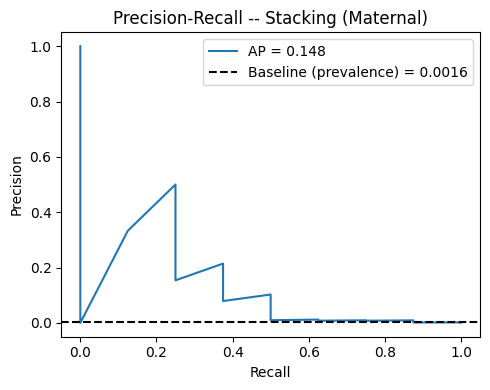

In [33]:
auc_stack = plot_roc(y_test, y_proba_stack, "Stacking (Maternal)", "Fig_ROC_Stacking_Maternal")
ap_stack  = plot_pr(y_test, y_proba_stack, "Stacking (Maternal)", "Fig_PR_Stacking_Maternal")

                        Modelo      AUC  Average Precision
            XGBoost (Maternal) 0.857539           0.277831
        Extra Trees (Maternal) 0.858268           0.160541
           Stacking (Maternal) 0.844480           0.147810
      Random Forest (Maternal) 0.785506           0.064633
Logistic Regression (Maternal) 0.854073           0.030572


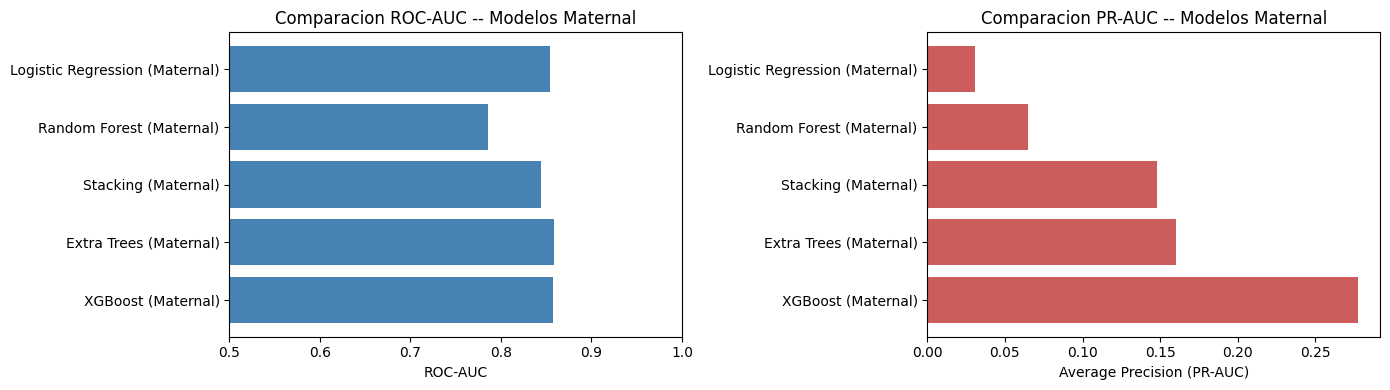

In [34]:
results = pd.DataFrame([
    {"Modelo": "Random Forest (Maternal)",       "AUC": auc_rf,    "Average Precision": ap_rf},
    {"Modelo": "XGBoost (Maternal)",              "AUC": auc_xgb,   "Average Precision": ap_xgb},
    {"Modelo": "Extra Trees (Maternal)",          "AUC": auc_et,    "Average Precision": ap_et},
    {"Modelo": "Logistic Regression (Maternal)",  "AUC": auc_rl,    "Average Precision": ap_rl},
    {"Modelo": "Stacking (Maternal)",              "AUC": auc_stack, "Average Precision": ap_stack},
]).sort_values("Average Precision", ascending=False)

print(results.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14,4))
axes[0].barh(results["Modelo"], results["AUC"], color="steelblue")
axes[0].set_xlabel("ROC-AUC"); axes[0].set_xlim(0.5, 1.0)
axes[0].set_title("Comparacion ROC-AUC -- Modelos Maternal")

axes[1].barh(results["Modelo"], results["Average Precision"], color="indianred")
axes[1].set_xlabel("Average Precision (PR-AUC)")
axes[1].set_title("Comparacion PR-AUC -- Modelos Maternal")

plt.tight_layout()
plt.show()

#### **12.6. Stratified K-Fold Cross-Validation -- Primary Evidence**

Section 11 designates repeated evidence across several stratified folds as the *primary* basis for judging model performance on this cohort, precisely because the single 80/20 split above evaluates on only **8 positive test cases** -- misclassifying just one or two of them swings recall by double-digit percentage points. This reuses `run_cv_diagnostics()` (already used once, in Section 12, as a pre-tuning sanity check for Random Forest) to aggregate performance across `N_SPLITS` stratified folds for all five **already-tuned** models (`best_model_rf`, `best_model_xgb`, `best_model_et`, `best_model_rl`, `stacking_clf`), run against the **full** `X`/`y` from Section 10 -- all 41 positive cases (winsorization keeps every admission), not just the 33 in `X_train` -- so each fold keeps roughly 8 positive cases, comparable to the single held-out test set above but averaged over five different splits, and without the noise of one arbitrary split.

`clone()` strips any fitted state before each fold, so every fold retrains each model from scratch on that fold's own training portion, using only the hyperparameters `GridSearchCV` already selected -- there is no leakage from that earlier tuning or from the 80/20 split above. **This is by far the most expensive cell in the notebook** -- Stacking alone retrains four base learners plus a meta-learner, `N_SPLITS` times over -- expect it to take noticeably longer than any previous cell. Lower `N_SPLITS` or comment out `"Stacking (Maternal)"` from `final_models` below for a quicker pass while iterating.

In [35]:
from sklearn.base import clone

final_models = {
    "Random Forest (Maternal)":        best_model_rf,
    "XGBoost (Maternal)":               best_model_xgb,
    "Extra Trees (Maternal)":           best_model_et,
    "Logistic Regression (Maternal)":   best_model_rl,
    "Stacking (Maternal)":              stacking_clf,
}

# Full X/y (Section 10, pre-split) -- NOT X_train/y_train -- so every fold has the maximum
# possible number of positive cases (~33 total) to work with, per the rationale in the markdown
# above. clone() drops each model's fitted state; run_cv_diagnostics (Section 12) refits from
# scratch on each fold using cv=skf (StratifiedKFold, N_SPLITS folds, defined in Section 11).
cv_summaries = {}
for name, fitted_model in final_models.items():
    cv_summaries[name] = run_cv_diagnostics(
        clone(fitted_model), X, y, f"{name} -- tuned, {N_SPLITS}-fold CV on full X/y"
    )

--- Random Forest (Maternal) -- tuned, 5-fold CV on full X/y (5-fold Stratified CV) ---
  roc_auc             : 0.809 +/- 0.042
  average_precision   : 0.115 +/- 0.091
  recall              : 0.000 +/- 0.000
  f1                  : 0.000 +/- 0.000
  balanced_accuracy   : 0.500 +/- 0.000
--- XGBoost (Maternal) -- tuned, 5-fold CV on full X/y (5-fold Stratified CV) ---
  roc_auc             : 0.817 +/- 0.045
  average_precision   : 0.165 +/- 0.119
  recall              : 0.117 +/- 0.145
  f1                  : 0.137 +/- 0.172
  balanced_accuracy   : 0.558 +/- 0.073
--- Extra Trees (Maternal) -- tuned, 5-fold CV on full X/y (5-fold Stratified CV) ---
  roc_auc             : 0.831 +/- 0.051
  average_precision   : 0.190 +/- 0.086
  recall              : 0.050 +/- 0.061
  f1                  : 0.089 +/- 0.109
  balanced_accuracy   : 0.525 +/- 0.031
--- Logistic Regression (Maternal) -- tuned, 5-fold CV on full X/y (5-fold Stratified CV) ---
  roc_auc             : 0.758 +/- 0.065
  average_

,roc_auc,average_precision,recall,f1,balanced_accuracy
Modelo,,,,,
Random Forest (Maternal),0.809 +/- 0.042,0.115 +/- 0.091,0.000 +/- 0.000,0.000 +/- 0.000,0.500 +/- 0.000
XGBoost (Maternal),0.817 +/- 0.045,0.165 +/- 0.119,0.117 +/- 0.145,0.137 +/- 0.172,0.558 +/- 0.073
Extra Trees (Maternal),0.831 +/- 0.051,0.190 +/- 0.086,0.050 +/- 0.061,0.089 +/- 0.109,0.525 +/- 0.031
Logistic Regression (Maternal),0.758 +/- 0.065,0.049 +/- 0.058,0.631 +/- 0.213,0.012 +/- 0.004,0.735 +/- 0.101
Stacking (Maternal),0.857 +/- 0.069,0.156 +/- 0.096,0.731 +/- 0.124,0.014 +/- 0.002,0.780 +/- 0.058


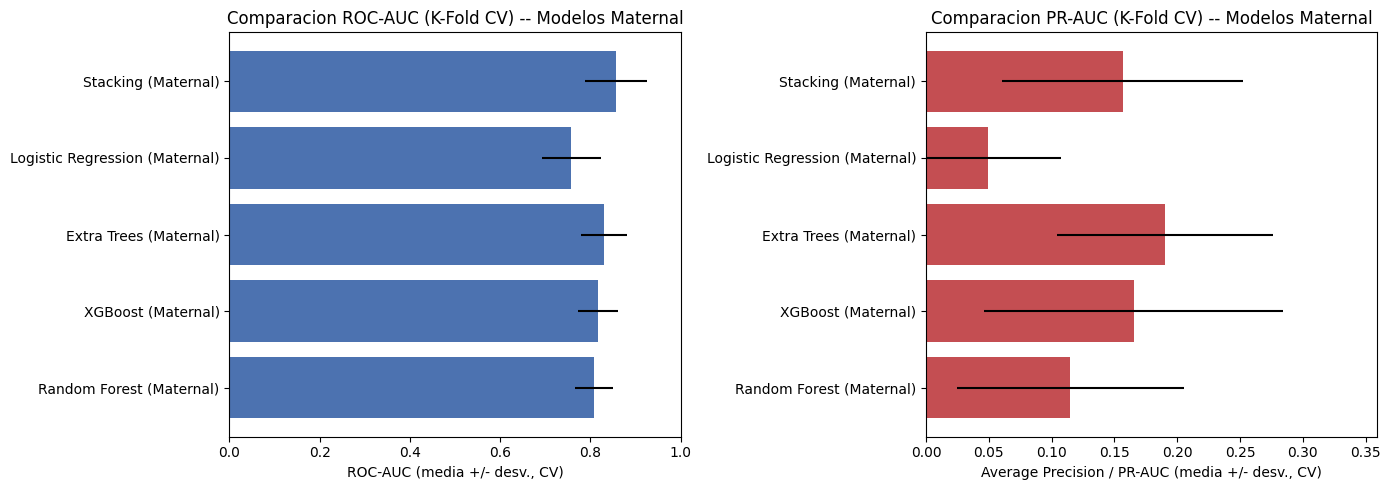

In [36]:
cv_table_rows = []
for name, summary in cv_summaries.items():
    row = {"Modelo": name}
    for metric, (m, s) in summary.items():
        row[metric] = f"{m:.3f} +/- {s:.3f}"
    cv_table_rows.append(row)

cv_table_df = pd.DataFrame(cv_table_rows).set_index("Modelo")
display(cv_table_df)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

model_names = list(cv_summaries.keys())
auc_means = [cv_summaries[m]["roc_auc"][0] for m in model_names]
auc_stds  = [cv_summaries[m]["roc_auc"][1] for m in model_names]
ap_means  = [cv_summaries[m]["average_precision"][0] for m in model_names]
ap_stds   = [cv_summaries[m]["average_precision"][1] for m in model_names]

axes[0].barh(model_names, auc_means, xerr=auc_stds, color="#4C72B0")
axes[0].set_xlim(0.0, 1.0)
axes[0].set_xlabel("ROC-AUC (media +/- desv., CV)")
axes[0].set_title("Comparacion ROC-AUC (K-Fold CV) -- Modelos Maternal")

axes[1].barh(model_names, ap_means, xerr=ap_stds, color="#C44E52")
axes[1].set_xlim(0.0, max(0.3, max(ap_means) + max(ap_stds) + 0.05))
axes[1].set_xlabel("Average Precision / PR-AUC (media +/- desv., CV)")
axes[1].set_title("Comparacion PR-AUC (K-Fold CV) -- Modelos Maternal")

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'Fig_CV_Comparison_Maternal.pdf'), format='pdf', bbox_inches='tight')
plt.savefig(os.path.join(FIG_DIR, 'Fig_CV_Comparison_Maternal.png'), format='png', dpi=300, bbox_inches='tight')
plt.show()

#### **12.7. Oversampling (SMOTE) -- Sensitivity Analysis**

Motivated by a direct question during review: could oversampling the minority class help the models learn more from the deceased mothers, on top of the class-weighting already used (`class_weight="balanced"`/`"balanced_subsample"`, `scale_pos_weight`)? Class weighting only reweights the loss function -- it never shows the model an additional positive example. SMOTE (already imported in Section 1) instead synthesises new minority-class feature vectors by interpolating between real positive cases' nearest neighbours, which can shift a model's decision boundary in a way reweighting alone cannot -- most plausibly for Logistic Regression, which in Section 12 showed the clearest symptom of a boundary that needs help (best hold-out ROC-AUC of the five models, 0.878, but one of the lowest AP values, 0.108).

**Why this is riskier here than in a typical SMOTE use case.** Section 10 has only ~33 real positive cases in the training split (~26-33 per training fold). SMOTE's default `k_neighbors=5` interpolates between each real positive case and its 5 nearest positive neighbours -- with this few real points, some of those neighbours may not be clinically similar to each other (maternal death covers very different causes: haemorrhage, sepsis, preeclampsia...), so a synthetic point can end up averaging two presentations that would not coexist in a real patient. `SMOTE_SAMPLING_STRATEGY` below is deliberately set to a **partial** rebalancing (minority becomes 20% of the majority count after resampling, not a full 1:1 balance) precisely to limit how much synthetic duplication this generates from so few real points -- full balancing at this prevalence (~620:1) would mean synthesising roughly 620 synthetic points per real one, which would risk the model learning mostly the interpolation artefacts of ~33 points rather than any real signal.

**How leakage is avoided.** Every model below is wrapped in an `imblearn.pipeline.Pipeline` (`SMOTE` -> classifier), not resampled once up front -- `cross_validate` (inside `run_cv_diagnostics`, Section 11) then applies SMOTE fresh inside each fold's training portion only, never touching that fold's validation portion. This is the same full `X`/`y` and the same `N_SPLITS`-fold `skf` used in Section 12.6, so the two sections' results are directly comparable side by side in the summary cell below -- **this section is a sensitivity analysis to compare against 12.6, not a replacement for it.** Read a large jump in any metric with real suspicion (more likely SMOTE overfitting to the ~33 points' idiosyncrasies than a genuine improvement); a modest, consistent shift across folds is the more trustworthy signal.

**Runtime warning.** This is at least as expensive as Section 12.6 -- SMOTE runs fresh inside every one of the `N_SPLITS` folds, and Stacking still retrains four base learners plus a meta-learner on the (now larger, post-SMOTE) training portion of each fold. Expect this to be the slowest cell in the notebook so far.

In [37]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

# Partial rebalancing, not full 1:1 -- see the markdown rationale above. With only ~26 real
# positive cases per training fold, k_neighbors=5 (the SMOTE default) still leaves comfortable
# room to find 5 real neighbours to interpolate between.
SMOTE_SAMPLING_STRATEGY = 0.2
SMOTE_K_NEIGHBORS = 5

def make_smote_pipeline(fitted_model):
    return ImbPipeline([
        ("smote", SMOTE(sampling_strategy=SMOTE_SAMPLING_STRATEGY,
                        k_neighbors=SMOTE_K_NEIGHBORS, random_state=42)),
        ("clf", clone(fitted_model)),
    ])

# Reuses final_models (defined in Section 12.6) and X/y (full dataset, Section 10) so the two
# sections' folds are directly comparable.
cv_summaries_smote = {}
for name, fitted_model in final_models.items():
    cv_summaries_smote[name] = run_cv_diagnostics(
        make_smote_pipeline(fitted_model), X, y,
        f"{name} + SMOTE (sampling_strategy={SMOTE_SAMPLING_STRATEGY}) -- "
        f"{N_SPLITS}-fold CV on full X/y"
    )

--- Random Forest (Maternal) + SMOTE (sampling_strategy=0.2) -- 5-fold CV on full X/y (5-fold Stratified CV) ---
  roc_auc             : 0.842 +/- 0.049
  average_precision   : 0.128 +/- 0.083
  recall              : 0.097 +/- 0.093
  f1                  : 0.157 +/- 0.140
  balanced_accuracy   : 0.549 +/- 0.047
--- XGBoost (Maternal) + SMOTE (sampling_strategy=0.2) -- 5-fold CV on full X/y (5-fold Stratified CV) ---
  roc_auc             : 0.854 +/- 0.051
  average_precision   : 0.173 +/- 0.122
  recall              : 0.142 +/- 0.133
  f1                  : 0.144 +/- 0.135
  balanced_accuracy   : 0.570 +/- 0.067
--- Extra Trees (Maternal) + SMOTE (sampling_strategy=0.2) -- 5-fold CV on full X/y (5-fold Stratified CV) ---
  roc_auc             : 0.848 +/- 0.057
  average_precision   : 0.173 +/- 0.082
  recall              : 0.097 +/- 0.093
  f1                  : 0.157 +/- 0.140
  balanced_accuracy   : 0.548 +/- 0.047
--- Logistic Regression (Maternal) + SMOTE (sampling_strategy=0.2) --

,roc_auc (sin SMOTE),roc_auc (con SMOTE),average_precision (sin SMOTE),average_precision (con SMOTE),recall (sin SMOTE),recall (con SMOTE),f1 (sin SMOTE),f1 (con SMOTE),balanced_accuracy (sin SMOTE),balanced_accuracy (con SMOTE)
Modelo,,,,,,,,,,
Random Forest (Maternal),0.809 +/- 0.042,0.842 +/- 0.049,0.115 +/- 0.091,0.128 +/- 0.083,0.000 +/- 0.000,0.097 +/- 0.093,0.000 +/- 0.000,0.157 +/- 0.140,0.500 +/- 0.000,0.549 +/- 0.047
XGBoost (Maternal),0.817 +/- 0.045,0.854 +/- 0.051,0.165 +/- 0.119,0.173 +/- 0.122,0.117 +/- 0.145,0.142 +/- 0.133,0.137 +/- 0.172,0.144 +/- 0.135,0.558 +/- 0.073,0.570 +/- 0.067
Extra Trees (Maternal),0.831 +/- 0.051,0.848 +/- 0.057,0.190 +/- 0.086,0.173 +/- 0.082,0.050 +/- 0.061,0.097 +/- 0.093,0.089 +/- 0.109,0.157 +/- 0.140,0.525 +/- 0.031,0.548 +/- 0.047
Logistic Regression (Maternal),0.758 +/- 0.065,0.809 +/- 0.051,0.049 +/- 0.058,0.052 +/- 0.035,0.631 +/- 0.213,0.267 +/- 0.117,0.012 +/- 0.004,0.046 +/- 0.020,0.735 +/- 0.101,0.625 +/- 0.058
Stacking (Maternal),0.857 +/- 0.069,0.870 +/- 0.040,0.156 +/- 0.096,0.168 +/- 0.110,0.731 +/- 0.124,0.142 +/- 0.133,0.014 +/- 0.002,0.195 +/- 0.178,0.780 +/- 0.058,0.571 +/- 0.067


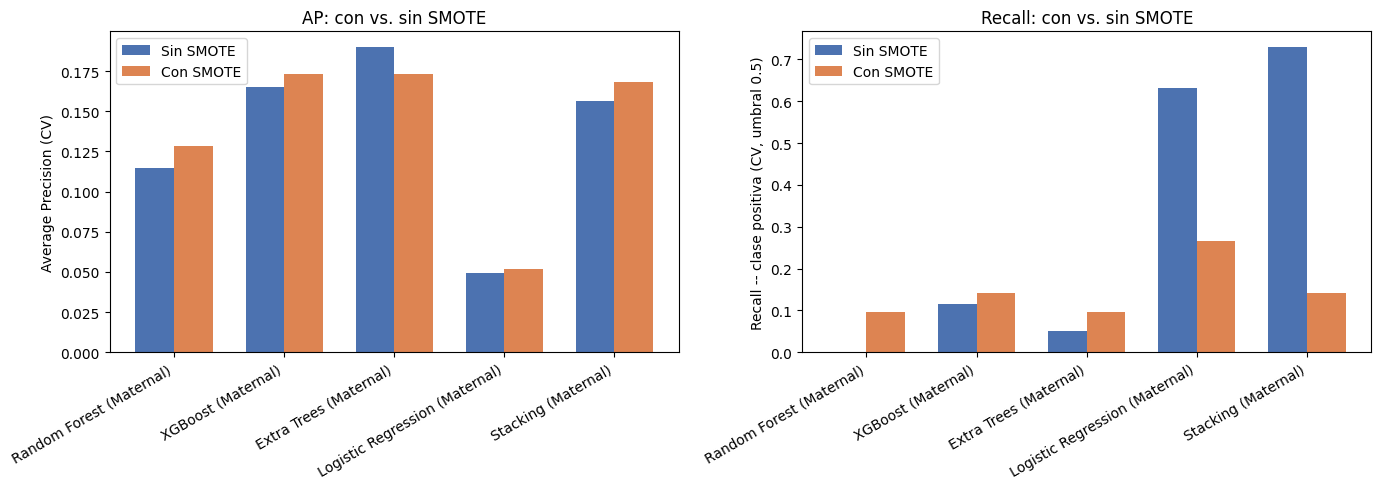

In [38]:
comparison_rows = []
for name in final_models:
    row = {"Modelo": name}
    for metric in ["roc_auc", "average_precision", "recall", "f1", "balanced_accuracy"]:
        m_base, s_base = cv_summaries[name][metric]
        m_smote, s_smote = cv_summaries_smote[name][metric]
        row[f"{metric} (sin SMOTE)"] = f"{m_base:.3f} +/- {s_base:.3f}"
        row[f"{metric} (con SMOTE)"]  = f"{m_smote:.3f} +/- {s_smote:.3f}"
    comparison_rows.append(row)

comparison_df = pd.DataFrame(comparison_rows).set_index("Modelo")
display(comparison_df)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
x = np.arange(len(final_models))
width = 0.35
model_names = list(final_models.keys())

ap_base     = [cv_summaries[m]["average_precision"][0] for m in model_names]
ap_smote    = [cv_summaries_smote[m]["average_precision"][0] for m in model_names]
recall_base  = [cv_summaries[m]["recall"][0] for m in model_names]
recall_smote = [cv_summaries_smote[m]["recall"][0] for m in model_names]

axes[0].bar(x - width/2, ap_base,  width, label="Sin SMOTE", color="#4C72B0")
axes[0].bar(x + width/2, ap_smote, width, label="Con SMOTE", color="#DD8452")
axes[0].set_xticks(x); axes[0].set_xticklabels(model_names, rotation=30, ha="right")
axes[0].set_ylabel("Average Precision (CV)")
axes[0].set_title("AP: con vs. sin SMOTE")
axes[0].legend()

axes[1].bar(x - width/2, recall_base,  width, label="Sin SMOTE", color="#4C72B0")
axes[1].bar(x + width/2, recall_smote, width, label="Con SMOTE", color="#DD8452")
axes[1].set_xticks(x); axes[1].set_xticklabels(model_names, rotation=30, ha="right")
axes[1].set_ylabel("Recall -- clase positiva (CV, umbral 0.5)")
axes[1].set_title("Recall: con vs. sin SMOTE")
axes[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'Fig_SMOTE_Comparison_Maternal.pdf'), format='pdf', bbox_inches='tight')
plt.savefig(os.path.join(FIG_DIR, 'Fig_SMOTE_Comparison_Maternal.png'), format='png', dpi=300, bbox_inches='tight')
plt.show()

#### **12.8. Sensitivity analysis -- Modelo A without the diagnostic-group indicators (`gdg_m*`)**

**Why.** Modelo A keeps the 26 binary `gdg_m01`-`gdg_m26` indicators as predictors, whereas Modelo B excludes them
(they are derived from the same coded diagnoses that define SMM -- an information leak there). To make both models
comparable, and to check how much of Modelo A's signal depends on coded diagnoses, this section repeats the
5-fold stratified CV of Section 12.6 on `X` **without** those 26 columns.

**How.** The already-tuned hyperparameters are **kept** (`clone()` of each tuned model, no new grid search), so the
only thing that changes is the predictor set. A single stacking refit on the 80/20 split is also shown, but with only
8 test positives it is illustrative -- the CV is the primary evidence. Reported in the article as a sensitivity analysis.

In [39]:
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict

# Deliberately NOT n_jobs=-1: nested joblib/loky workers caused a MemoryError (PicklingError) on this
# machine when running Model A. Raise it only if RAM allows.
N_JOBS_CV = 2

def run_cv_safe(model, X_data, y_data, label, verbose=True):
    """Same metrics as run_cv_diagnostics (Section 11), but with a conservative n_jobs."""
    scores = cross_validate(model, X_data, y_data, cv=skf, scoring=cv_scoring, n_jobs=N_JOBS_CV)
    summary = {metric: (np.mean(scores[f"test_{metric}"]), np.std(scores[f"test_{metric}"]))
               for metric in cv_scoring}
    if verbose:
        print(f"--- {label} ({N_SPLITS}-fold Stratified CV) ---")
        for metric, (m, s) in summary.items():
            print(f"  {metric:20s}: {m:.3f} +/- {s:.3f}")
    return summary

def summaries_to_table(summaries):
    rows = []
    for name, summary in summaries.items():
        row = {"Model": name}
        for metric, (m, s) in summary.items():
            row[metric] = f"{m:.3f} +/- {s:.3f}"
        rows.append(row)
    return pd.DataFrame(rows).set_index("Model")

In [40]:
gdg_cols = [c for c in X.columns if c.startswith("gdg_m")]
X_nogdg = X.drop(columns=gdg_cols)
print(f"Dropped {len(gdg_cols)} diagnostic-group indicators: X {X.shape} -> X_nogdg {X_nogdg.shape}")

# Hyperparameters are KEPT from the tuned models (no re-tuning): this isolates the effect of the predictor set.
cv_summaries_nogdg = {}
for name, fitted_model in final_models.items():
    cv_summaries_nogdg[name] = run_cv_safe(
        clone(fitted_model), X_nogdg, y, f"{name} -- WITHOUT gdg_*, {N_SPLITS}-fold CV on full data"
    )

Dropped 26 diagnostic-group indicators: X (25736, 89) -> X_nogdg (25736, 63)
--- Random Forest (Maternal) -- WITHOUT gdg_*, 5-fold CV on full data (5-fold Stratified CV) ---
  roc_auc             : 0.700 +/- 0.067
  average_precision   : 0.007 +/- 0.004
  recall              : 0.000 +/- 0.000
  f1                  : 0.000 +/- 0.000
  balanced_accuracy   : 0.500 +/- 0.000
--- XGBoost (Maternal) -- WITHOUT gdg_*, 5-fold CV on full data (5-fold Stratified CV) ---
  roc_auc             : 0.690 +/- 0.064
  average_precision   : 0.039 +/- 0.051
  recall              : 0.047 +/- 0.058
  f1                  : 0.014 +/- 0.018
  balanced_accuracy   : 0.520 +/- 0.028
--- Extra Trees (Maternal) -- WITHOUT gdg_*, 5-fold CV on full data (5-fold Stratified CV) ---
  roc_auc             : 0.768 +/- 0.065
  average_precision   : 0.021 +/- 0.005
  recall              : 0.000 +/- 0.000
  f1                  : 0.000 +/- 0.000
  balanced_accuracy   : 0.497 +/- 0.001
--- Logistic Regression (Maternal) -- WI

,roc_auc (with gdg_*),roc_auc (no gdg_*),average_precision (with gdg_*),average_precision (no gdg_*),recall (with gdg_*),recall (no gdg_*)
Model,,,,,,
Random Forest (Maternal),0.809 +/- 0.042,0.700 +/- 0.067,0.115 +/- 0.091,0.007 +/- 0.004,0.000 +/- 0.000,0.000 +/- 0.000
XGBoost (Maternal),0.817 +/- 0.045,0.690 +/- 0.064,0.165 +/- 0.119,0.039 +/- 0.051,0.117 +/- 0.145,0.047 +/- 0.058
Extra Trees (Maternal),0.831 +/- 0.051,0.768 +/- 0.065,0.190 +/- 0.086,0.021 +/- 0.005,0.050 +/- 0.061,0.000 +/- 0.000
Logistic Regression (Maternal),0.758 +/- 0.065,0.635 +/- 0.068,0.049 +/- 0.058,0.061 +/- 0.062,0.631 +/- 0.213,0.417 +/- 0.105
Stacking (Maternal),0.857 +/- 0.069,0.725 +/- 0.061,0.156 +/- 0.096,0.013 +/- 0.005,0.731 +/- 0.124,0.536 +/- 0.166



Hold-out stacking (8 test positives only -- illustrative):
  with gdg_*   : AUC = 0.844 | AP = 0.148
  without gdg_*: AUC = 0.731 | AP = 0.020


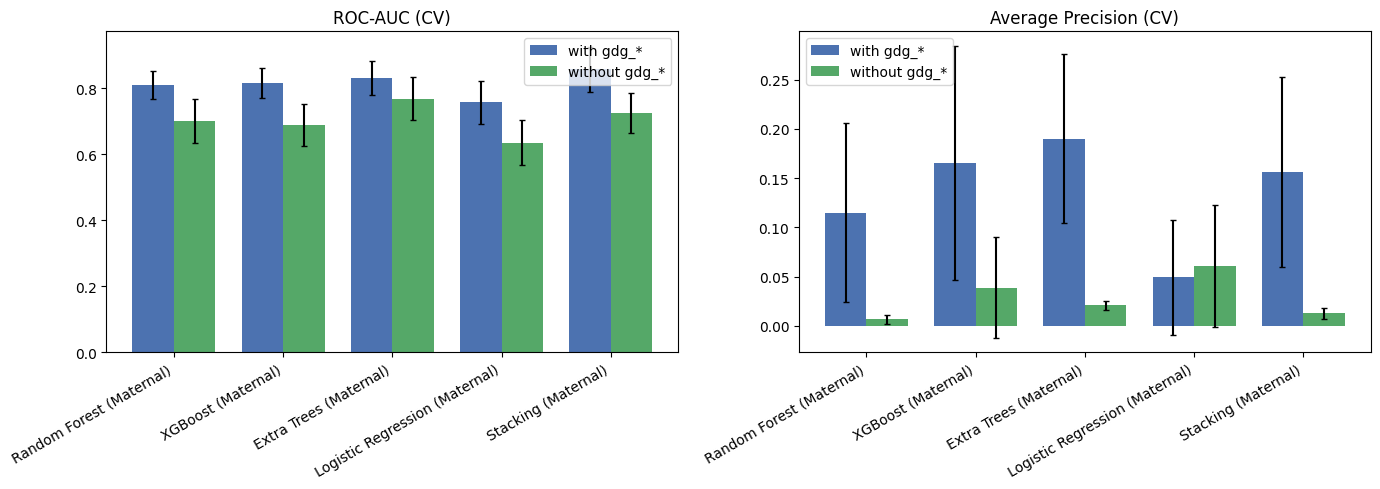

In [41]:
rows = []
for name in final_models:
    row = {"Model": name}
    for metric in ["roc_auc", "average_precision", "recall"]:
        mw, sw = cv_summaries[name][metric]
        mo, so = cv_summaries_nogdg[name][metric]
        row[f"{metric} (with gdg_*)"] = f"{mw:.3f} +/- {sw:.3f}"
        row[f"{metric} (no gdg_*)"] = f"{mo:.3f} +/- {so:.3f}"
    rows.append(row)
nogdg_df = pd.DataFrame(rows).set_index("Model")
display(nogdg_df)
nogdg_df.to_csv(os.path.join(DATA_DIR, "Table_CV_NoGDG_Maternal.csv"))

# Hold-out check (same 80/20 split as Section 11): stacking refit without gdg_*, tuned hyperparameters reused.
X_train_ng = X_train.drop(columns=gdg_cols); X_test_ng = X_test.drop(columns=gdg_cols)
stack_ng = clone(stacking_clf).fit(X_train_ng, y_train)
p_ng = stack_ng.predict_proba(X_test_ng)[:, 1]
p_wi = stacking_clf.predict_proba(X_test)[:, 1]
print(f"\nHold-out stacking ({int(y_test.sum())} test positives only -- illustrative):")
print(f"  with gdg_*   : AUC = {roc_auc_score(y_test, p_wi):.3f} | AP = {average_precision_score(y_test, p_wi):.3f}")
print(f"  without gdg_*: AUC = {roc_auc_score(y_test, p_ng):.3f} | AP = {average_precision_score(y_test, p_ng):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
names = list(final_models.keys()); x = np.arange(len(names)); w = 0.38
for ax, metric, title in [(axes[0], "roc_auc", "ROC-AUC (CV)"), (axes[1], "average_precision", "Average Precision (CV)")]:
    ax.bar(x - w/2, [cv_summaries[n][metric][0] for n in names], w, yerr=[cv_summaries[n][metric][1] for n in names],
           label="with gdg_*", color="#4C72B0", capsize=2)
    ax.bar(x + w/2, [cv_summaries_nogdg[n][metric][0] for n in names], w, yerr=[cv_summaries_nogdg[n][metric][1] for n in names],
           label="without gdg_*", color="#55A868", capsize=2)
    ax.set_xticks(x); ax.set_xticklabels(names, rotation=30, ha="right"); ax.set_title(title); ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "Fig_CV_NoGDG_Maternal.pdf"), format="pdf", bbox_inches="tight")
plt.savefig(os.path.join(FIG_DIR, "Fig_CV_NoGDG_Maternal.png"), format="png", dpi=300, bbox_inches="tight")
plt.show()

### **13. Explainability (SHAP)**

Kept commented-out, pending an actual model run against the live database. Given the extreme rarity of
the positive class, SHAP beeswarm/summary plots for this cohort should be interpreted as descriptive of
the *fitted model's* behaviour, not as a validated causal or strongly generalisable signal -- 41 positive
cases is a very small basis for feature-attribution claims.

In [42]:
explainer        = shap.TreeExplainer(stacking_clf.named_estimators_['rf'])
shap_explanation = explainer(X_test)
shap_plot        = shap_explanation[:, :, 1]   # 3D -> clase "murio"

plt.figure(figsize=(9, 6))
shap.plots.beeswarm(shap_plot, max_display=15, show=False)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "Fig_SHAP_RF_Maternal.pdf"), dpi=300, bbox_inches='tight')
plt.savefig(os.path.join(FIG_DIR, "Fig_SHAP_RF_Maternal.png"), dpi=300, bbox_inches='tight')
plt.close()
print("Listo RF")

Listo RF


In [43]:
explainer        = shap.TreeExplainer(stacking_clf.named_estimators_['xgb'])
shap_explanation = explainer(X_test)
shap_plot        = shap_explanation   # XGB devuelve 2D directo

plt.figure(figsize=(9, 6))
shap.plots.beeswarm(shap_plot, max_display=15, show=False)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "Fig_SHAP_XGBoost_Maternal.pdf"), dpi=300, bbox_inches='tight')
plt.savefig(os.path.join(FIG_DIR, "Fig_SHAP_XGBoost_Maternal.png"), dpi=300, bbox_inches='tight')
plt.close()
print("Listo XGB")

Listo XGB


In [44]:
explainer        = shap.TreeExplainer(stacking_clf.named_estimators_['et'])
shap_explanation = explainer(X_test, check_additivity=False)
shap_plot        = shap_explanation[:, :, 1]

plt.figure(figsize=(9, 6))
shap.plots.beeswarm(shap_plot, max_display=15, show=False)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "Fig_SHAP_Extra_Trees_Maternal.pdf"), dpi=300, bbox_inches='tight')
plt.savefig(os.path.join(FIG_DIR, "Fig_SHAP_Extra_Trees_Maternal.png"), dpi=300, bbox_inches='tight')
plt.close()
print("Listo ET")

Listo ET


In [45]:
explainer     = shap.LinearExplainer(stacking_clf.named_estimators_['rl'], X_train)
shap_vals_raw = explainer.shap_values(X_test)

if isinstance(shap_vals_raw, list):
    shap_vals = shap_vals_raw[1]
else:
    shap_vals = shap_vals_raw

shap_vals = np.array(shap_vals, dtype=np.float64)
X_test_np = X_test.astype(np.float64)

plt.figure(figsize=(9, 6))
shap.summary_plot(shap_vals, X_test_np, max_display=15, show=False)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "Fig_SHAP_Logistic_Reg_Maternal.pdf"), dpi=300, bbox_inches='tight')
plt.savefig(os.path.join(FIG_DIR, "Fig_SHAP_Logistic_Reg_Maternal.png"), dpi=300, bbox_inches='tight')
plt.close()
print("Listo LR")

Listo LR


### **14. Risk Stratification Bands -- Adapted for Extreme Imbalance**

The framework built for this type of modelling classifies patients into Bajo/Moderado/Alto risk bands
using fixed probability thresholds (e.g. tau_low=0.35, tau_high=0.65), calibrated against a near-balanced
outcome. **Those thresholds cannot be reused as-is** for a 0.159%-prevalence outcome: a well-calibrated
model on this cohort will rarely output p_hat > 0.5 for *any* patient, because the base rate itself is
~0.00159. Reusing tau=0.35/0.65 here would likely place almost every patient in "Bajo riesgo" regardless
of true risk, which would be clinically misleading.

**Recommended approach for the maternal model** (to be executed once real predictions are available):

1. Use the **model's own predicted-probability distribution** to set thresholds, e.g. flag the top
   1%-5% of predicted probabilities as "Alto riesgo" (a *relative*, prevalence-aware cut), rather than
   fixed absolute probability cuts.
2. Report a **sensitivity table**: for a range of candidate thresholds (or of "% of patients flagged"),
   show how many of the 41 true deaths would be captured (recall) and how many false alerts would be
   generated, following the same reporting style used across this thesis's modelling framework, built from
   the maternal model's actual `predict_proba` output.
3. Given n=41 positives, **do not present a single sensitivity/threshold pair as definitive**; present a
   curve (Precision-Recall) with confidence bands from the k-fold results, and defer a specific operating
   point to a clinical panel discussion, exactly like the "Esta decision debe ser validada por un
   responsable humano autorizado" principle used for high-stakes model decisions.

```python
# Illustrative code -- run only once stacking_clf, X_test, y_test come from a real model fit.
# y_prob = stacking_clf.predict_proba(X_test)[:, 1]
# y_true = np.array(y_test)
#
# thresholds_to_test = [0.01, 0.02, 0.05, 0.10, 0.20, 0.35, 0.50]
# rows = []
# for tau in thresholds_to_test:
#     flagged = y_prob >= tau
#     recall_tau = y_true[flagged].sum() / y_true.sum() if y_true.sum() > 0 else np.nan
#     pct_flagged = flagged.mean()
#     rows.append({"tau": tau, "pct_patients_flagged": pct_flagged, "recall_captured": recall_tau})
# pd.DataFrame(rows)
```

#### **14.1. Implementation -- calibration, "flag the top x%" tables and risk bands**

Implements the three recommendations above with the actual predictions:

1. **Out-of-fold (OOF) probabilities** over the full cohort (all 41 deaths, every admission scored by a stacking model
   that never saw it) are the **primary** evidence; the 80/20 hold-out (8 deaths) is shown only as a secondary view.
2. **Calibration**: Brier score vs. the "always predict the prevalence" reference, mean predicted probability vs.
   observed prevalence, and a reliability plot. Because the models use class weighting, **raw probabilities are expected to
   be inflated**; this is reported, not corrected. The rank-based quantities (top-x% tables, risk bands) do not need
   calibrated probabilities.
3. **Sensitivity table** (% of admissions flagged vs. recall / PPV / lift), **risk bands** from the model's own
   probability percentiles (Low < 80th, Moderate 80-95th, High top 5%) and **bootstrap 95% CIs**. With 41 events the
   intervals are wide: present them as a curve with uncertainty, never as one operating point. *"This decision must be
   validated by an authorised human responsible party."*

**Runtime**: one extra stacking CV (the same cost as one row of Section 12.6).

Model A (maternal death) -- stacked ensemble -- out-of-fold predictions (full cohort)
N = 25736 | events = 41 | prevalence = 0.00159
Mean predicted probability = 0.37881  (observed prevalence = 0.00159; ratio = 237.8x)
Brier score = 0.16210 | Brier of 'always predict prevalence' = 0.00159 | Brier skill score = -100.913
AUC = 0.842 | AP = 0.123

NOTE: models were trained with class weighting, so raw probabilities are NOT expected to be calibrated to the real prevalence; the RANK-based tables below do not depend on calibration.



,n flagged,true positives,recall,PPV,lift vs prevalence,n flagged per true positive,min probability in flagged
% flagged,,,,,,,
0.5,129,11,0.2683,0.0853,53.5254,11.7273,0.8321
1.0,257,13,0.3171,0.0506,31.7517,19.7692,0.7968
2.0,515,14,0.3415,0.0272,17.0639,36.7857,0.7556
5.0,1287,18,0.4390,0.0140,8.7791,71.5000,0.6889
10.0,2574,22,0.5366,0.0085,5.3650,117.0000,0.6235
20.0,5147,29,0.7073,0.0056,3.5367,177.4828,0.4621


,% flagged,true positives,recall,PPV
tau,,,,
0.05,100.0000,41,1.0000,0.0016
0.10,100.0000,41,1.0000,0.0016
0.20,100.0000,41,1.0000,0.0016
0.30,67.3298,38,0.9268,0.0022
0.50,17.2443,27,0.6585,0.0061
0.65,7.9733,21,0.5122,0.0102
0.80,0.9520,13,0.3171,0.0531


,n,events,event rate,share of all events
band,,,,
Low (<80th pct),20588,12,0.0006,0.2927
Moderate (80-95th pct),3861,11,0.0028,0.2683
High (top 5%),1287,18,0.0140,0.4390


Band cut-offs (probabilities): moderate >= 0.4620, high >= 0.6889

Bootstrap 95% CI (500 resamples): recall@top5%: [0.286, 0.615]; PPV@top5%: [0.008, 0.021]; AUC: [0.771, 0.914]; AP: [0.036, 0.251]


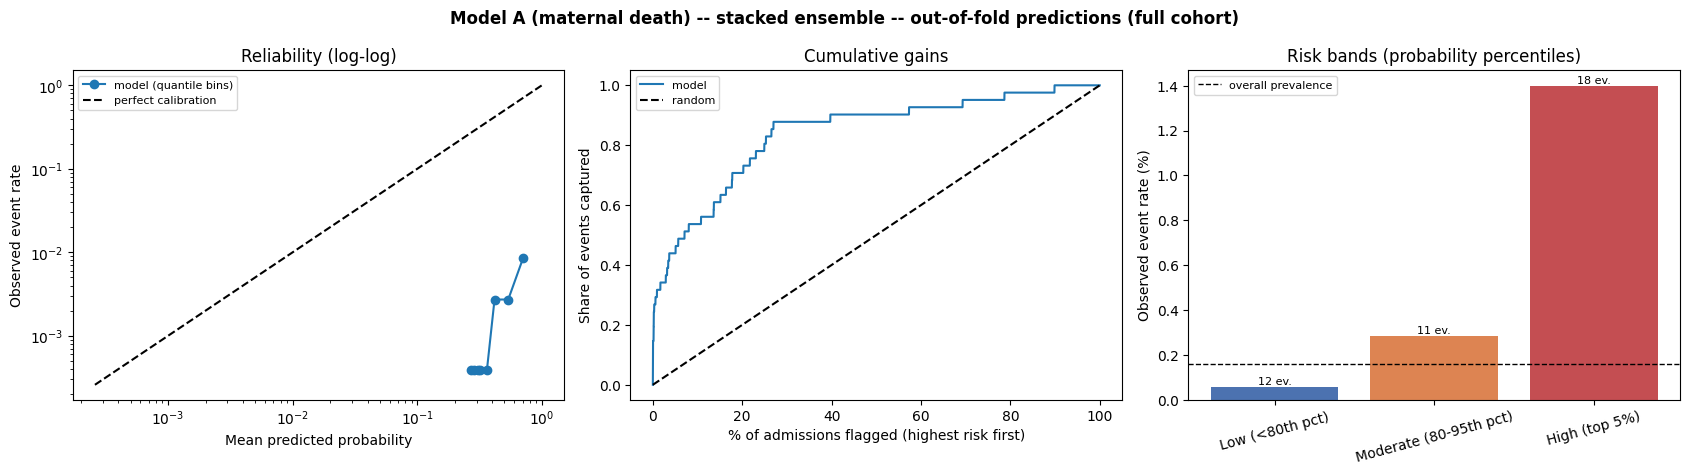

Model A (maternal death) -- stacked ensemble -- hold-out test split
N = 5148 | events = 8 | prevalence = 0.00155
Mean predicted probability = 0.36850  (observed prevalence = 0.00155; ratio = 237.1x)
Brier score = 0.15586 | Brier of 'always predict prevalence' = 0.00155 | Brier skill score = -99.453
AUC = 0.844 | AP = 0.148

NOTE: models were trained with class weighting, so raw probabilities are NOT expected to be calibrated to the real prevalence; the RANK-based tables below do not depend on calibration.



,n flagged,true positives,recall,PPV,lift vs prevalence,n flagged per true positive,min probability in flagged
% flagged,,,,,,,
0.5,26,3,0.375,0.1154,74.2500,8.6667,0.8567
1.0,51,4,0.500,0.0784,50.4706,12.7500,0.8030
2.0,103,4,0.500,0.0388,24.9903,25.7500,0.7606
5.0,257,4,0.500,0.0156,10.0156,64.2500,0.7362
10.0,515,5,0.625,0.0097,6.2476,103.0000,0.6211
20.0,1030,7,0.875,0.0068,4.3733,147.1429,0.4369


,% flagged,true positives,recall,PPV
tau,,,,
0.05,100.0000,8,1.000,0.0016
0.10,100.0000,8,1.000,0.0016
0.20,100.0000,8,1.000,0.0016
0.30,52.3116,7,0.875,0.0026
0.50,15.6566,7,0.875,0.0087
0.65,8.7801,5,0.625,0.0111
0.80,1.0295,4,0.500,0.0755


,n,events,event rate,share of all events
band,,,,
Low (<80th pct),4118,1,0.0002,0.125
Moderate (80-95th pct),772,3,0.0039,0.375
High (top 5%),258,4,0.0155,0.500


Band cut-offs (probabilities): moderate >= 0.4369, high >= 0.7359

Bootstrap 95% CI (500 resamples): recall@top5%: [0.167, 0.833]; PPV@top5%: [0.004, 0.031]; AUC: [0.609, 0.978]; AP: [0.012, 0.482]


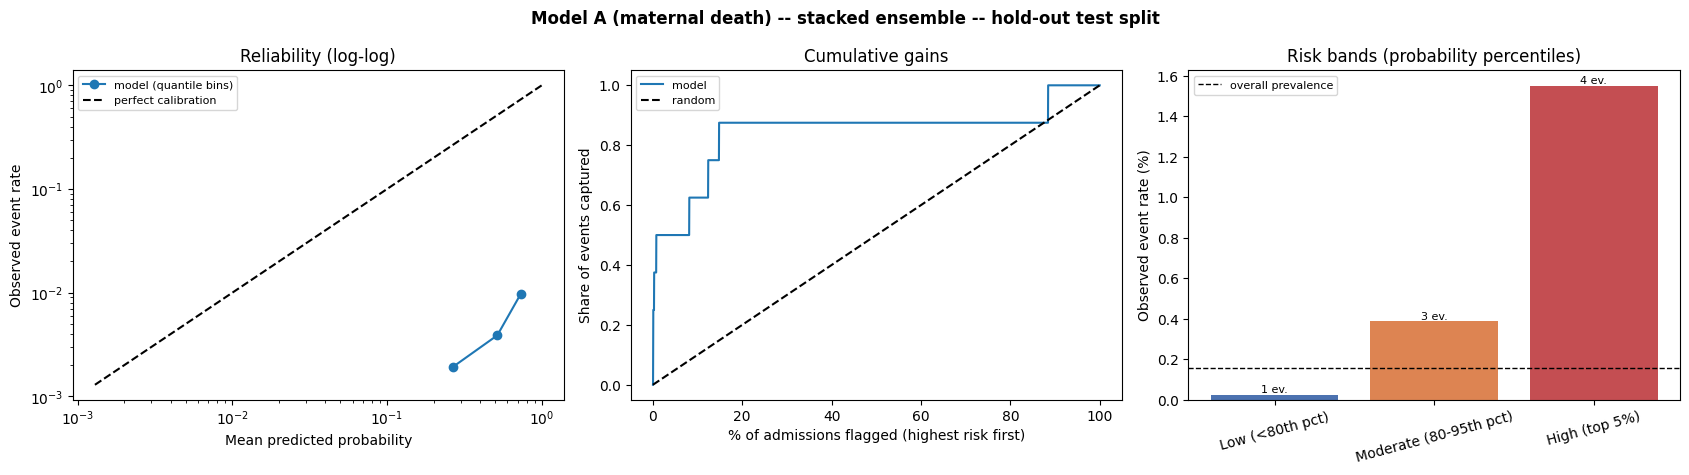

In [46]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

N_JOBS_CV = 2
N_BOOT = 500
LABEL = "Maternal"          # used in file names

def _gains_table(y_true, y_prob, pcts=(0.5, 1, 2, 5, 10, 20)):
    """'Flag the top x% highest predicted probabilities' -> recall / PPV / lift. Needs no calibration."""
    y_true = np.asarray(y_true); n = len(y_true); P = y_true.sum(); prev = y_true.mean()
    order = np.argsort(-y_prob)
    rows = []
    for pct in pcts:
        k = max(1, int(round(n * pct / 100)))
        idx = order[:k]; tp = int(y_true[idx].sum())
        rows.append({"% flagged": pct, "n flagged": k, "true positives": tp,
                     "recall": tp / P, "PPV": tp / k, "lift vs prevalence": (tp / k) / prev,
                     "n flagged per true positive": (k / tp) if tp > 0 else np.nan,
                     "min probability in flagged": float(y_prob[idx].min())})
    return pd.DataFrame(rows).set_index("% flagged")

def _absolute_threshold_table(y_true, y_prob, taus=(0.05, 0.10, 0.20, 0.30, 0.50, 0.65, 0.80)):
    y_true = np.asarray(y_true); rows = []
    for tau in taus:
        flagged = y_prob >= tau; k = int(flagged.sum()); tp = int(y_true[flagged].sum())
        rows.append({"tau": tau, "% flagged": 100 * flagged.mean(), "true positives": tp,
                     "recall": tp / y_true.sum(), "PPV": (tp / k) if k > 0 else np.nan})
    return pd.DataFrame(rows).set_index("tau")

def _risk_bands(y_true, y_prob, q_mod=0.80, q_high=0.95):
    """Prevalence-aware bands from the model's OWN probability distribution (not fixed 0.35/0.65 cuts)."""
    y_true = np.asarray(y_true)
    t_mod, t_high = np.quantile(y_prob, [q_mod, q_high])
    band = np.where(y_prob >= t_high, "High (top 5%)", np.where(y_prob >= t_mod, "Moderate (80-95th pct)", "Low (<80th pct)"))
    out = []
    for b in ["Low (<80th pct)", "Moderate (80-95th pct)", "High (top 5%)"]:
        m = band == b
        out.append({"band": b, "n": int(m.sum()), "events": int(y_true[m].sum()),
                    "event rate": y_true[m].mean() if m.sum() else np.nan,
                    "share of all events": y_true[m].sum() / y_true.sum()})
    return pd.DataFrame(out).set_index("band"), (t_mod, t_high)

def _bootstrap_ci(y_true, y_prob, pct=5, n_boot=N_BOOT, seed=42):
    y_true = np.asarray(y_true); n = len(y_true); rng = np.random.default_rng(seed)
    k = max(1, int(round(n * pct / 100))); res = []
    for _ in range(n_boot):
        i = rng.integers(0, n, n); yt = y_true[i]; yp = y_prob[i]
        if yt.sum() == 0 or yt.sum() == n:
            continue
        tp = yt[np.argsort(-yp)[:k]].sum()
        res.append((tp / yt.sum(), tp / k, roc_auc_score(yt, yp), average_precision_score(yt, yp)))
    lo, hi = np.percentile(np.array(res), [2.5, 97.5], axis=0)
    return dict(zip(["recall@top5%", "PPV@top5%", "AUC", "AP"], zip(lo, hi)))

def calibration_and_risk_report(y_true, y_prob, title, fig_suffix, n_bins=10):
    y_true = np.asarray(y_true); prev = y_true.mean()
    brier = brier_score_loss(y_true, y_prob)
    brier_ref = brier_score_loss(y_true, np.full(len(y_true), prev))
    print("=" * 78); print(title); print("=" * 78)
    print(f"N = {len(y_true)} | events = {int(y_true.sum())} | prevalence = {prev:.5f}")
    print(f"Mean predicted probability = {y_prob.mean():.5f}  (observed prevalence = {prev:.5f}; "
          f"ratio = {y_prob.mean() / prev:.1f}x)")
    print(f"Brier score = {brier:.5f} | Brier of 'always predict prevalence' = {brier_ref:.5f} | "
          f"Brier skill score = {1 - brier / brier_ref:.3f}")
    print(f"AUC = {roc_auc_score(y_true, y_prob):.3f} | AP = {average_precision_score(y_true, y_prob):.3f}")
    print("\nNOTE: models were trained with class weighting, so raw probabilities are NOT expected to be "
          "calibrated to the real prevalence; the RANK-based tables below do not depend on calibration.\n")

    gains = _gains_table(y_true, y_prob); display(gains.round(4))
    absolute = _absolute_threshold_table(y_true, y_prob); display(absolute.round(4))
    bands, (t_mod, t_high) = _risk_bands(y_true, y_prob); display(bands.round(4))
    print(f"Band cut-offs (probabilities): moderate >= {t_mod:.4f}, high >= {t_high:.4f}")
    ci = _bootstrap_ci(y_true, y_prob)
    print(f"\nBootstrap 95% CI ({N_BOOT} resamples): " +
          "; ".join(f"{k}: [{lo:.3f}, {hi:.3f}]" for k, (lo, hi) in ci.items()))

    fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
    frac_pos, mean_pred = calibration_curve(y_true, y_prob, n_bins=n_bins, strategy="quantile")
    ok = (frac_pos > 0) & (mean_pred > 0)
    axes[0].plot(mean_pred[ok], frac_pos[ok], "o-", label="model (quantile bins)")
    lim = [min(mean_pred[ok].min(), frac_pos[ok].min()) / 1.5, 1.0] if ok.any() else [1e-4, 1.0]
    axes[0].plot(lim, lim, "k--", label="perfect calibration")
    axes[0].set_xscale("log"); axes[0].set_yscale("log")
    axes[0].set_xlabel("Mean predicted probability"); axes[0].set_ylabel("Observed event rate")
    axes[0].set_title("Reliability (log-log)"); axes[0].legend(fontsize=8)

    order = np.argsort(-y_prob); cum = np.cumsum(y_true[order]) / y_true.sum()
    frac = np.arange(1, len(y_true) + 1) / len(y_true)
    axes[1].plot(frac * 100, cum, label="model"); axes[1].plot([0, 100], [0, 1], "k--", label="random")
    axes[1].set_xlabel("% of admissions flagged (highest risk first)"); axes[1].set_ylabel("Share of events captured")
    axes[1].set_title("Cumulative gains"); axes[1].legend(fontsize=8)

    axes[2].bar(bands.index, bands["event rate"] * 100, color=["#4C72B0", "#DD8452", "#C44E52"])
    axes[2].axhline(prev * 100, color="k", linestyle="--", linewidth=1, label="overall prevalence")
    for i, (r, n_ev) in enumerate(zip(bands["event rate"], bands["events"])):
        axes[2].text(i, r * 100, f"{n_ev} ev.", ha="center", va="bottom", fontsize=8)
    axes[2].set_ylabel("Observed event rate (%)"); axes[2].set_title("Risk bands (probability percentiles)")
    axes[2].tick_params(axis="x", rotation=15); axes[2].legend(fontsize=8)
    fig.suptitle(title, weight="bold")
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, f"Fig_Calibration_Risk_{LABEL}_{fig_suffix}.pdf"), format="pdf", bbox_inches="tight")
    plt.savefig(os.path.join(FIG_DIR, f"Fig_Calibration_Risk_{LABEL}_{fig_suffix}.png"), format="png", dpi=300, bbox_inches="tight")
    plt.show()
    return {"gains": gains, "absolute": absolute, "bands": bands, "ci": ci, "brier": brier, "brier_ref": brier_ref}

# (1) PRIMARY: out-of-fold probabilities over the FULL cohort -- every admission is scored by a stacking
#     model that never saw it (same folds as the CV sections). Uses all 41 events, not just the test split.
y_oof = cross_val_predict(clone(stacking_clf), X, y, cv=skf, method="predict_proba", n_jobs=N_JOBS_CV)[:, 1]
report_oof = calibration_and_risk_report(y, y_oof, "Model A (maternal death) -- stacked ensemble -- out-of-fold predictions (full cohort)", "OOF")

# (2) SECONDARY: the 80/20 hold-out test split used in Section 12.
y_prob_test = stacking_clf.predict_proba(X_test)[:, 1]
report_test = calibration_and_risk_report(y_test, y_prob_test, "Model A (maternal death) -- stacked ensemble -- hold-out test split", "Test")

Recalibration of the out-of-fold stacking probabilities -- Maternal -- N = 25736, events = 41, prevalence = 0.00159
Calibration maps fitted inside 5-fold CV (repeated 20x); mean over repetitions.



,Brier,Brier skill,mean pred / prevalence,ECE (10 quantile bins),slope,intercept,AUC,AP
Raw (class-weighted),0.1621,-100.9131,237.7797,0.3772,1.0810,-6.3493,0.8416,0.1229
Platt,0.0015,0.0644,1.0095,0.0006,0.9771,-0.1414,0.8363,0.1148
Isotonic,0.0015,0.0550,1.0079,0.0006,0.7256,-1.5192,0.8046,0.0982



SD across repetitions (variability of the calibration folds only):


,Brier,Brier skill,mean pred / prevalence,ECE (10 quantile bins),slope,intercept,AUC,AP
Raw (class-weighted),0.0,-0.0000,0.0000,0.0000,0.0000,-0.0000,0.0000,0.0000
Platt,0.0,0.0054,0.0053,0.0001,0.0020,0.0003,0.0052,0.0059
Isotonic,0.0,0.0080,0.0126,0.0001,0.0564,0.3405,0.0073,0.0061


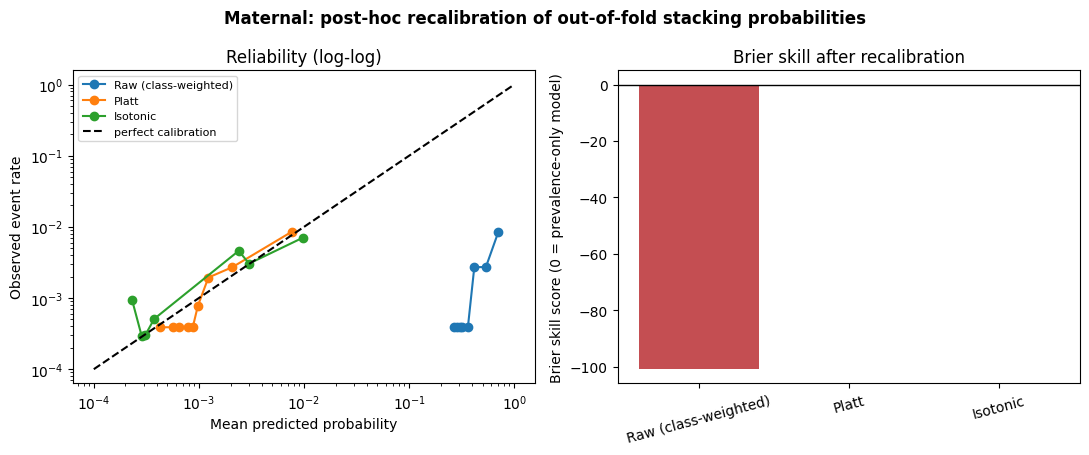

In [47]:
N_REPEATS_CAL = 20      # repetitions of the calibration cross-validation (different fold assignments)
N_SPLITS_CAL = 5

def _logit(p, eps=1e-6):
    p = np.clip(np.asarray(p, dtype=float), eps, 1 - eps)
    return np.log(p / (1 - p))

def _ece_quantile(y_true, y_prob, n_bins=10):
    """Expected calibration error with equal-frequency bins."""
    y_true = np.asarray(y_true); y_prob = np.asarray(y_prob)
    bins = np.array_split(np.argsort(y_prob, kind="mergesort"), n_bins)
    return float(sum(len(b) / len(y_true) * abs(y_true[b].mean() - y_prob[b].mean()) for b in bins))

def _slope_intercept(y_true, y_prob):
    """Calibration slope and intercept: logistic regression of the outcome on logit(p). Ideal: slope 1, intercept 0."""
    lr = LogisticRegression(C=1e6, max_iter=2000).fit(_logit(y_prob).reshape(-1, 1), y_true)
    return float(lr.coef_[0, 0]), float(lr.intercept_[0])

def _fit_predict_calibrator(method, p_tr, y_tr, p_te):
    if method == "Platt":
        cal = LogisticRegression(C=1e6, max_iter=2000).fit(_logit(p_tr).reshape(-1, 1), y_tr)
        return cal.predict_proba(_logit(p_te).reshape(-1, 1))[:, 1]
    cal = IsotonicRegression(y_min=0.0, y_max=1.0, out_of_bounds="clip").fit(p_tr, y_tr)
    return cal.predict(p_te)

def _metrics(y_true, p):
    prev = y_true.mean()
    brier = brier_score_loss(y_true, p); brier_ref = brier_score_loss(y_true, np.full(len(y_true), prev))
    slope, intercept = _slope_intercept(y_true, p)
    return {"Brier": brier, "Brier skill": 1 - brier / brier_ref, "mean pred / prevalence": p.mean() / prev,
            "ECE (10 quantile bins)": _ece_quantile(y_true, p), "slope": slope, "intercept": intercept,
            "AUC": roc_auc_score(y_true, p), "AP": average_precision_score(y_true, p)}

y_arr = np.asarray(y).astype(int); p_raw = np.asarray(y_oof, dtype=float)
rows = {"Raw (class-weighted)": [_metrics(y_arr, p_raw)]}
examples = {}
for method in ["Platt", "Isotonic"]:
    rows[method] = []
    for r in range(N_REPEATS_CAL):
        skf_cal = StratifiedKFold(n_splits=N_SPLITS_CAL, shuffle=True, random_state=100 + r)
        p_cal = np.zeros(len(y_arr))
        for tr, te in skf_cal.split(p_raw.reshape(-1, 1), y_arr):
            p_cal[te] = _fit_predict_calibrator(method, p_raw[tr], y_arr[tr], p_raw[te])
        rows[method].append(_metrics(y_arr, p_cal))
        if r == 0:
            examples[method] = p_cal.copy()

summary = pd.DataFrame({k: pd.DataFrame(v).mean() for k, v in rows.items()}).T
summary_sd = pd.DataFrame({k: pd.DataFrame(v).std(ddof=1) if len(v) > 1 else pd.DataFrame(v).mean() * 0 for k, v in rows.items()}).T
print(f"Recalibration of the out-of-fold stacking probabilities -- {LABEL} -- N = {len(y_arr)}, events = {int(y_arr.sum())}, "
      f"prevalence = {y_arr.mean():.5f}")
print(f"Calibration maps fitted inside {N_SPLITS_CAL}-fold CV (repeated {N_REPEATS_CAL}x); mean over repetitions.\n")
display(summary.round(4))
print("\nSD across repetitions (variability of the calibration folds only):")
display(summary_sd.round(4))
summary.round(5).to_csv(os.path.join(DATA_DIR, f"Table_Recalibration_{LABEL}.csv"))

# Rank-based metrics: each calibration map is monotonic, but maps differ between folds, so pooled AUC/AP can change slightly;
# isotonic regression also creates ties and can lose resolution.
fig, ax = plt.subplots(1, 2, figsize=(11, 4.6))
curves = {"Raw (class-weighted)": p_raw, "Platt": examples["Platt"], "Isotonic": examples["Isotonic"]}
for name, pp in curves.items():
    fp, mp = calibration_curve(y_arr, pp, n_bins=10, strategy="quantile")
    ok = (fp > 0) & (mp > 0)
    ax[0].plot(mp[ok], fp[ok], "o-", label=name)
lo = 1e-4
ax[0].plot([lo, 1], [lo, 1], "k--", label="perfect calibration")
ax[0].set_xscale("log"); ax[0].set_yscale("log")
ax[0].set_xlabel("Mean predicted probability"); ax[0].set_ylabel("Observed event rate")
ax[0].set_title("Reliability (log-log)"); ax[0].legend(fontsize=8)
ax[1].bar(summary.index, summary["Brier skill"], color=["#C44E52", "#4C72B0", "#DD8452"])
ax[1].axhline(0, color="k", linewidth=1)
ax[1].set_ylabel("Brier skill score (0 = prevalence-only model)"); ax[1].set_title("Brier skill after recalibration")
ax[1].tick_params(axis="x", rotation=15)
fig.suptitle(f"{LABEL}: post-hoc recalibration of out-of-fold stacking probabilities", weight="bold")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, f"Fig_Recalibration_{LABEL}.pdf"), format="pdf", bbox_inches="tight")
plt.savefig(os.path.join(FIG_DIR, f"Fig_Recalibration_{LABEL}.png"), format="png", dpi=300, bbox_inches="tight")
plt.show()

### **15. Limitations and Open Design Questions for Emmanuel**

This section documents, with full transparency, the assumptions made while building this notebook without
access to a live MIMIC-IV instance, so they can be validated or corrected before the pipeline is run for
real:

1. **Definition of "mother" vs. "woman with an obstetric diagnosis".** The cohort filter used here (an ICD
   diagnosis matching `PREGNANCY`/`OBSTETRIC`/`FETAL`/`DELIVERY`) captures *any* woman with an
   obstetric-adjacent diagnosis recorded during the admission -- this could include, e.g., a woman admitted
   for an unrelated condition who also carries a historical "supervision of pregnancy" code, not
   necessarily someone actively delivering or peripartum. Confirm whether the cohort should be narrowed to
   codes specifically indicating an active pregnancy/delivery episode (e.g. restricting to ICD chapter
   O00-O9A) versus the broader keyword match already validated by Emmanuel (23,474/23,471/36).
2. **Outcome time window.** Unlike a birth-linked outcome, which can be bounded through a fixed short
   post-birth window, the maternal outcome here is an unbounded "died in this admission or any later one,"
   which could, in principle, flag a woman who developed an unrelated fatal condition years after the
   qualifying pregnancy-related admission. Confirm whether a tighter post-admission window (e.g. death
   within the same admission, or within N days) is clinically more appropriate for "maternal mortality" as
   defined in the thesis.
3. **Overlap with other cohorts built from this same MIMIC-IV instance.** MIMIC-IV does not provide a
   public mother-infant linkage key, so this maternal cohort (adult women, `subject_id` in the adult range)
   is expected to be structurally independent from any newborn-subject cohort built elsewhere in the
   thesis's data pipeline (separate `subject_id`s, `dob` in the shifted window) -- there should be no
   double-counting of the same clinical episode across models. This assumption should be explicitly stated
   and spot-checked directly against this project's own data in the thesis text, rather than assumed from
   another cohort's construction, given that other cohort's own querying has separately needed correction.
4. **The diagnostic groups (`gdg_m*`) are now populated, not placeholders -- physician review in
   progress.** Sections 2.2-2.3 build a full rule-based ICD classification (100% coverage of the 4,116
   codes), consolidated into 26 real diagnostic groups (`gdg_m01`-`gdg_m26`) plus 2 reserved
   residual-cluster slots (`gdg_m27`/`gdg_m28`, currently unused since the rule-based pass left nothing to
   cluster). This classification was sent to the physician panel for review (2026-09-17); several have
   replied favourably, and further review is ongoing. The classification/mapping pipeline is deliberately
   built to be modifiable (see `docs/NAMING.md` and `scripts/generate_maternal_diagnoses_group_sql.py`) so
   future panel feedback only requires editing the source CSVs, not the SQL or notebook code.
5. **Removing outliers from a minority class of 41 cases** (Section 5) carries real risk of
   deleting exactly the extreme values that are clinically informative for mortality; the audit column
   added (`removed_positive_cases`) should be reviewed carefully once real data is available, and the x3
   IQR factor revisited if it removes a meaningful share of the 41 deaths.
6. **The `GridSearchCV` metric** was switched to `'average_precision'` (Section 12) instead of plain
   `'f1'`; confirm this is the desired optimisation target for the thesis, or whether
   `'f1'` / `'recall'` should be used instead given the clinical cost asymmetry.
7. **SMOTE was tested as a sensitivity analysis (Section 12.7, 2026-09-18) and empirically rejected as
   a default.** Motivated by the question of whether oversampling could help the models learn more from
   the deceased mothers on top of the class-weighting already used, every tuned model was re-evaluated
   with `SMOTE(sampling_strategy=0.2)` inside an `imblearn.pipeline.Pipeline` (fold-safe, no leakage) via
   the same repeated Stratified K-Fold CV as Section 12.6, and compared directly against the no-SMOTE
   result. The result: SMOTE **lowered** Average Precision -- the metric this pipeline's `GridSearchCV`
   optimises for -- in 4 of the 5 models (Random Forest 0.110 -> 0.065, XGBoost 0.144 -> 0.023, Extra
   Trees 0.098 -> 0.079, Stacking 0.094 -> 0.076; only Logistic Regression rose, and only from 0.018 to a
   still-negligible 0.027). More strikingly, it **collapsed recall** for the two models that had the best
   recall without it -- Stacking fell from 0.710 to 0.062, Logistic Regression from 0.457 to 0.119 -- while
   only XGBoost's recall improved (0.400 -> 0.829), and only at the cost of its AP dropping to roughly a
   sixth of its original value (i.e. a much more permissive, lower-precision classifier). The most likely
   explanation, consistent with the risk flagged before running this analysis: with only ~26 real positive
   training examples per fold, `SMOTE`'s `k_neighbors=5` interpolation is drawing synthetic points across
   clinically heterogeneous causes of maternal death (haemorrhage, sepsis, preeclampsia, ...) that would
   not coexist in a real patient, diluting rather than sharpening the decision boundary the class-weighted
   models had already learned from the real data alone -- and for the tree ensembles, doubling up on
   imbalance correction (`class_weight` *and* synthetic duplication) on top of that. **Decision: SMOTE is
   not used in the main pipeline.** Class weighting (`class_weight="balanced"`/`"balanced_subsample"`,
   `scale_pos_weight`) remains the only imbalance-handling mechanism, and this negative result is reported
   in the thesis as evidence that oversampling was considered and empirically tested, not simply omitted
   by default, given the very small number of real positive examples available to synthesise from.

8. **Imputing clinical variables with an MNAR bias (not yet discussed with the thesis advisor).** After
   removing the mandatory ICU filter (see Section 2, correction of 2025-08-02), the clinical variables
   derived from `chartevents` (heart_rate, blood pressure, glucose, etc.) are `NaN` for ~98% of the cohort
   that never had an ICU stay. The median/mode used to impute them (Section 6) is, in practice, computed
   only over ICU patients (the most severe cases in the cohort), and that value is then used to fill in
   the rest -- a missing-not-at-random (MNAR) scenario, not missing-completely-at-random. Emmanuel decided
   (2025-08-02) to leave the simple imputation as-is for now and discuss with the thesis advisor whether
   it's worth adding binary "missing" flags per variable before imputing (standard practice for this kind
   of bias). Pending a final decision before interpreting the importance of the clinical variables in
   Modelo A's results.


> The cohort figures now authoritative for this notebook are the ones confirmed in Section 2.1 --
> **25,736 admissions, 41 deaths (~0.159%)** in `mimiciv.cohort_maternal` -- superseding the earlier
> narrow-view figures (23,474 / 23,471 / 36), which remain in Section 2.1 only as the Analysis 1
> comparison. As of this revision (2026-09-18), Sections 2.1 through 12.7 have been run against the live
> database with real results (see the confirmed figures and fixes documented throughout, including the
> single-split and cross-validated model results in Section 12 and the SMOTE sensitivity analysis in item
> 7 above); the modelling steps from Section 13 onward (SHAP, risk stratification bands) are still pending
> an end-to-end run and should be treated as a syntactically valid draft until then.

> **Update 2026-10-09.** Item 5 above is now resolved in the direction the audit suggested: outliers are winsorized (Section 5), not deleted, so all 41 deaths are retained. The first run's row-deletion had removed 8 of them. All figures in this section computed under the old policy (including the SMOTE numbers in item 7) must be regenerated after re-running the notebook.
